In [2]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as ticker

Wygenerowano: baseline_hotspots_stacked.pdf oraz baseline_hotspots_stacked.png


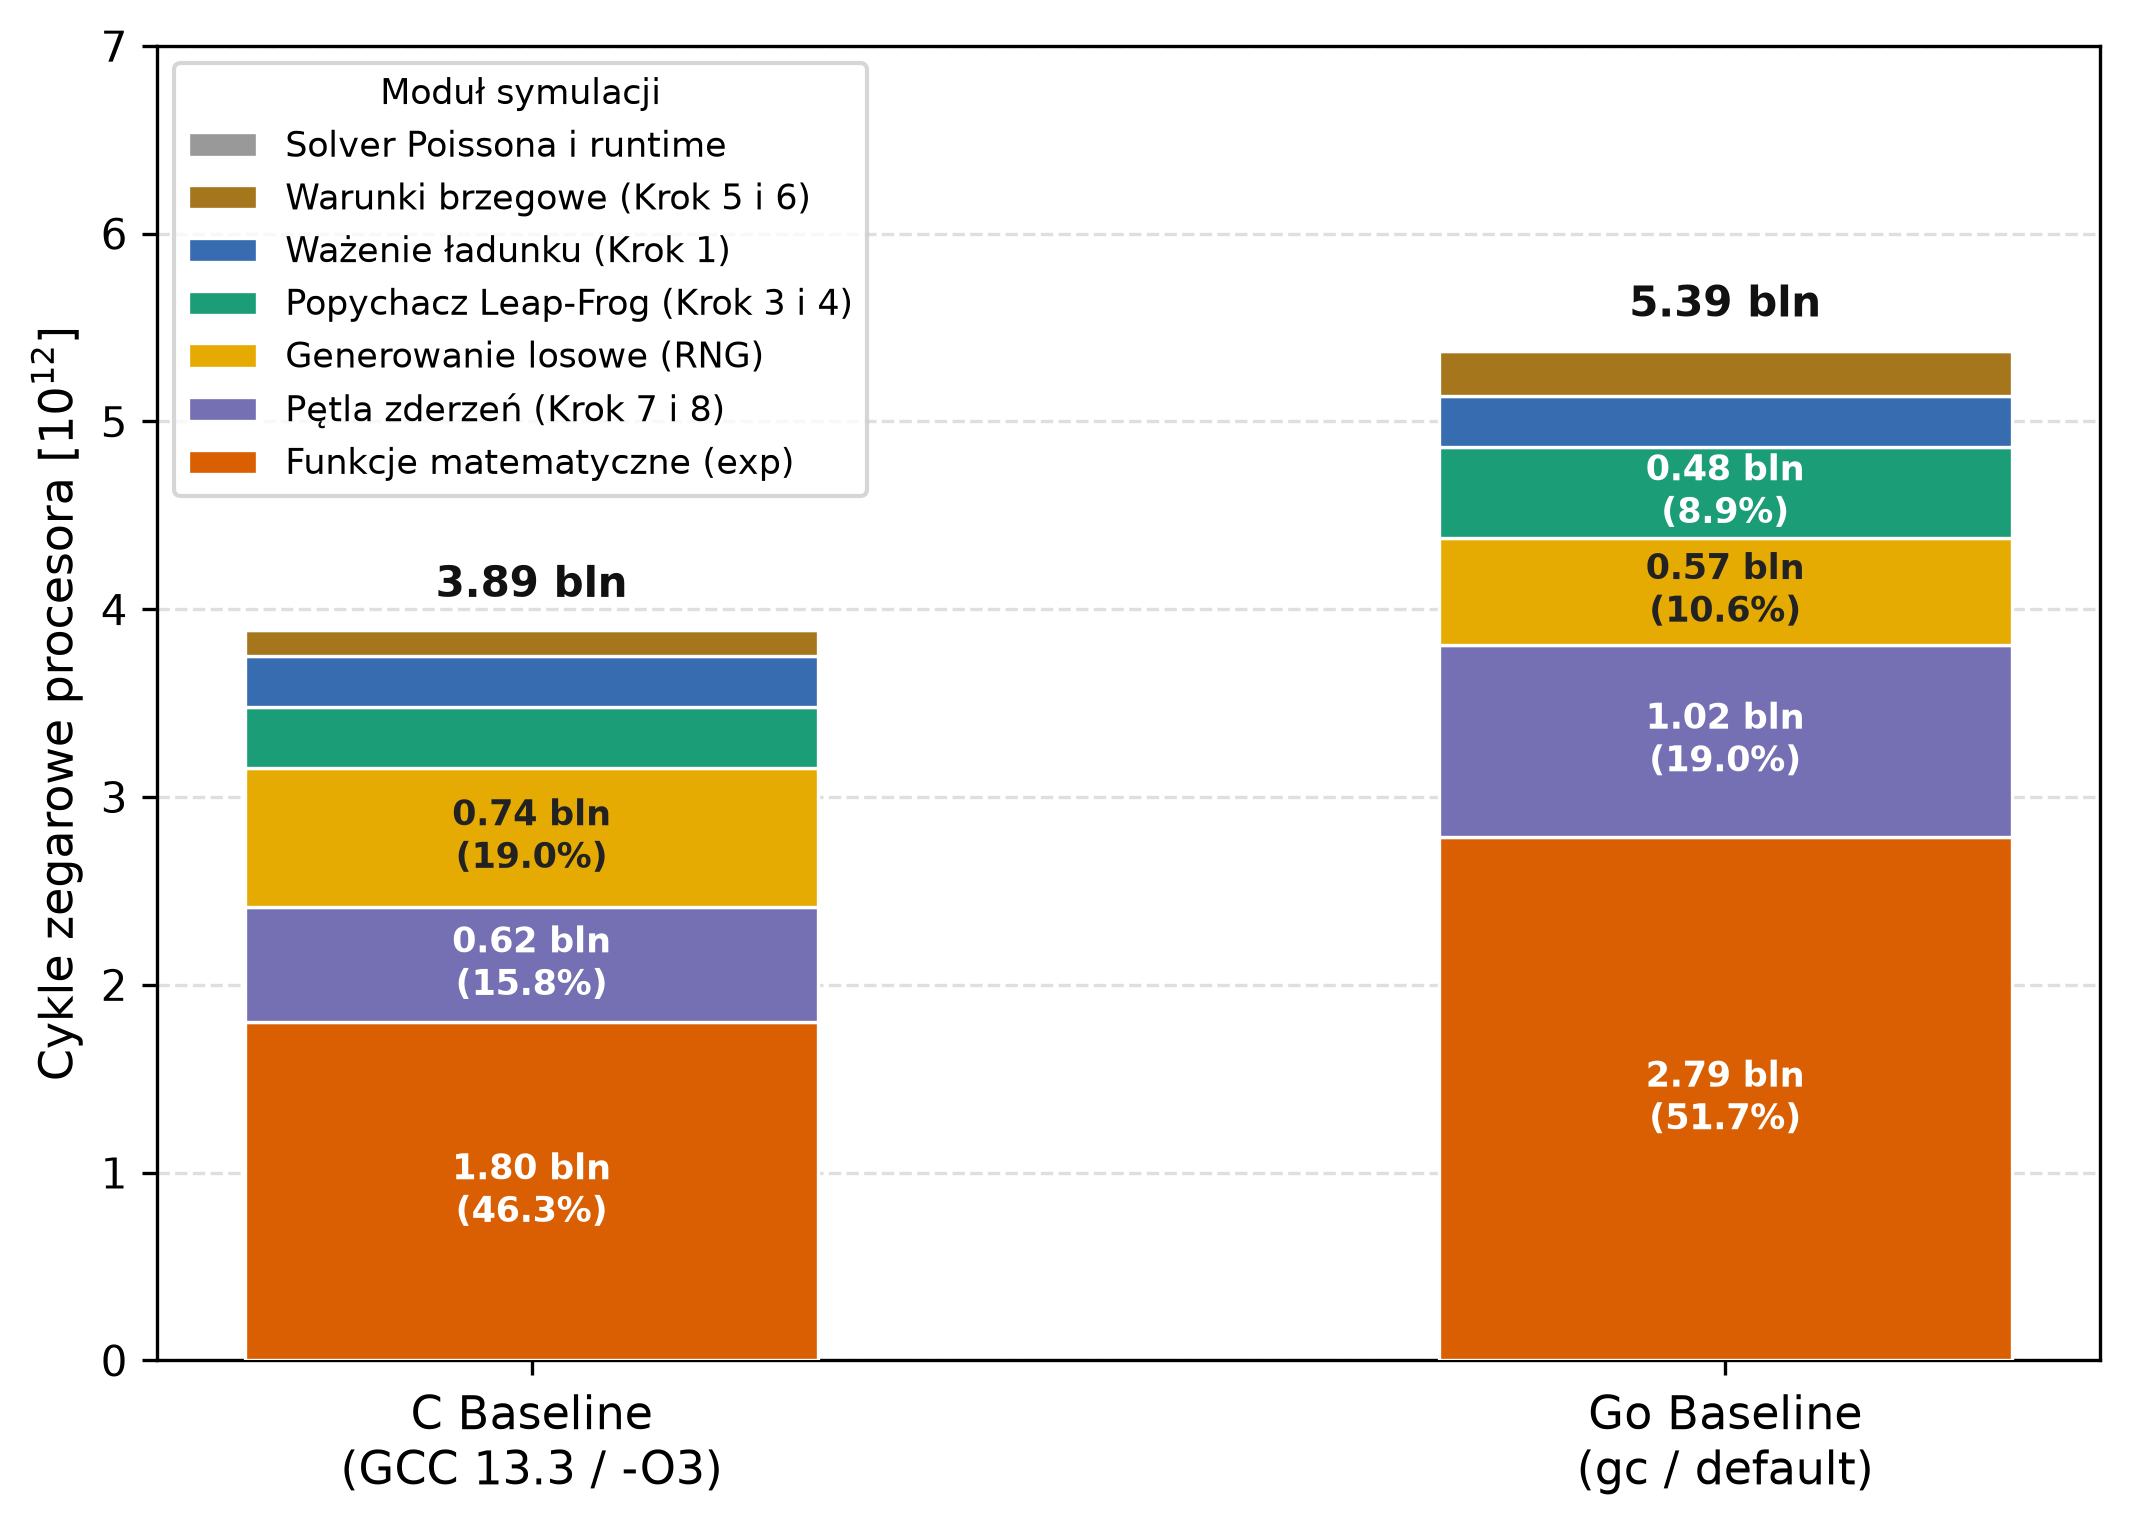

In [48]:
# 1. Konfiguracja stylu akademickiego
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 11,
    'ytick.labelsize': 10,
    'figure.autolayout': True,
    'figure.dpi': 300,
})

# 2. Definicja kategorii (od dołu do góry słupka)
categories = [
    "Funkcje matematyczne (exp)",
    "Pętla zderzeń (Krok 7 i 8)",
    "Generowanie losowe (RNG)",
    "Popychacz Leap-Frog (Krok 3 i 4)",
    "Ważenie ładunku (Krok 1)",
    "Warunki brzegowe (Krok 5 i 6)",
    "Solver Poissona i runtime",
]

# Dane w bilionach cykli CPU (skalowane do oficjalnej Tabeli 5.2):
cpp_cycles = [1.80109, 0.61563, 0.73792, 0.32228, 0.27172, 0.13955, 0.00418]
go_cycles = [2.78765, 1.02428, 0.56928, 0.48249, 0.27170, 0.23882, 0.01132]

# Procenty do etykiet tekstowych wewnątrz pasków:
cpp_pct = [46.27, 15.82, 18.96, 8.28, 6.98, 3.59, 0.11]
go_pct = [51.71, 19.00, 10.56, 8.95, 5.04, 4.43, 0.21]

colors = [
    "#d95f02",  # exp - wyraźny ceglasty/terakota (główny bottleneck)
    "#7570b3",  # zderzenia - fiolet
    "#e6ab02",  # RNG - ciepły bursztyn
    "#1b9e77",  # popychacz Leap-Frog - szmaragd
    "#386cb0",  # depozycja ładunku - stonowany błękit
    "#a6761d",  # warunki brzegowe - oliwka/ochra
    "#999999",  # Poisson i inne - neutralna szarość
]

# 4. Rysowanie wykresu
fig, ax = plt.subplots(figsize=(7.2, 5.2))

x_pos = np.array([0, 1])
x_labels = ["C Baseline\n(GCC 13.3 / -O3)", "Go Baseline\n(gc / default)"]
bar_width = 0.48

bottom = np.zeros(2)
bars_handles = []

for i in range(len(categories)):
    vals = np.array([cpp_cycles[i], go_cycles[i]])
    p = ax.bar(
        x_pos, vals, bar_width,
        bottom=bottom,
        label=categories[i],
        color=colors[i],
        edgecolor="white",
        linewidth=0.8,
        zorder=3
    )
    bars_handles.append(p)

    # Etykiety wewnątrz segmentów (dla pasków o wysokości >= 0.4 bln)
    for j in range(2):
        val = vals[j]
        pct = cpp_pct[i] if j == 0 else go_pct[i]
        if val >= 0.4:
            # Kolor tekstu: biały dla ciemnych, ciemny dla jasnych
            text_color = "white" if colors[i] not in ["#e6ab02", "#fdb462"] else "#222222"
            ax.text(
                x_pos[j],
                bottom[j] + val / 2.0,
                f"{val:.2f} bln\n({pct:.1f}%)",
                ha="center",
                va="center",
                fontsize=8.5,
                fontweight="bold",
                color=text_color,
                zorder=4
            )

    bottom = bottom + vals

# 5. Łączne sumy nad słupkami
total_cpp = sum(cpp_cycles)
total_go = sum(go_cycles)

ax.text(x_pos[0], total_cpp +  0.12, f"{total_cpp:.2f} bln",
        ha="center", va="bottom", fontsize=10, fontweight="bold", color="#111111")
ax.text(x_pos[1], total_go +  0.12, f"{total_go:.2f} bln",
        ha="center", va="bottom", fontsize=10, fontweight="bold", color="#111111")

# 6. Siatka, osie i limity
ax.set_ylabel("Cykle zegarowe procesora [$10^{12}$]")
ax.set_xticks(x_pos)
ax.set_xticklabels(x_labels)
ax.set_ylim(0, 7)
ax.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
ax.set_axisbelow(True)

# 7. Legenda z odwróconą kolejnością (zgodna z kolejnością pasków od góry)
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles[::-1], labels[::-1],
    # bbox_to_anchor=(1.02, 1.0),
    loc="upper left",
    frameon=True,
    # framealpha=0.95,
    edgecolor="#cccccc",
    title="Moduł symulacji",
    title_fontsize='small',
    fontsize='small'
)

# 8. Zapis wyników
out_pdf = "baseline_hotspots_stacked.pdf"
out_png = "baseline_hotspots_stacked.png"
plt.savefig(out_pdf, bbox_inches="tight")
plt.savefig(out_png, bbox_inches="tight", dpi=300)
print(f"Wygenerowano: {out_pdf} oraz {out_png}")

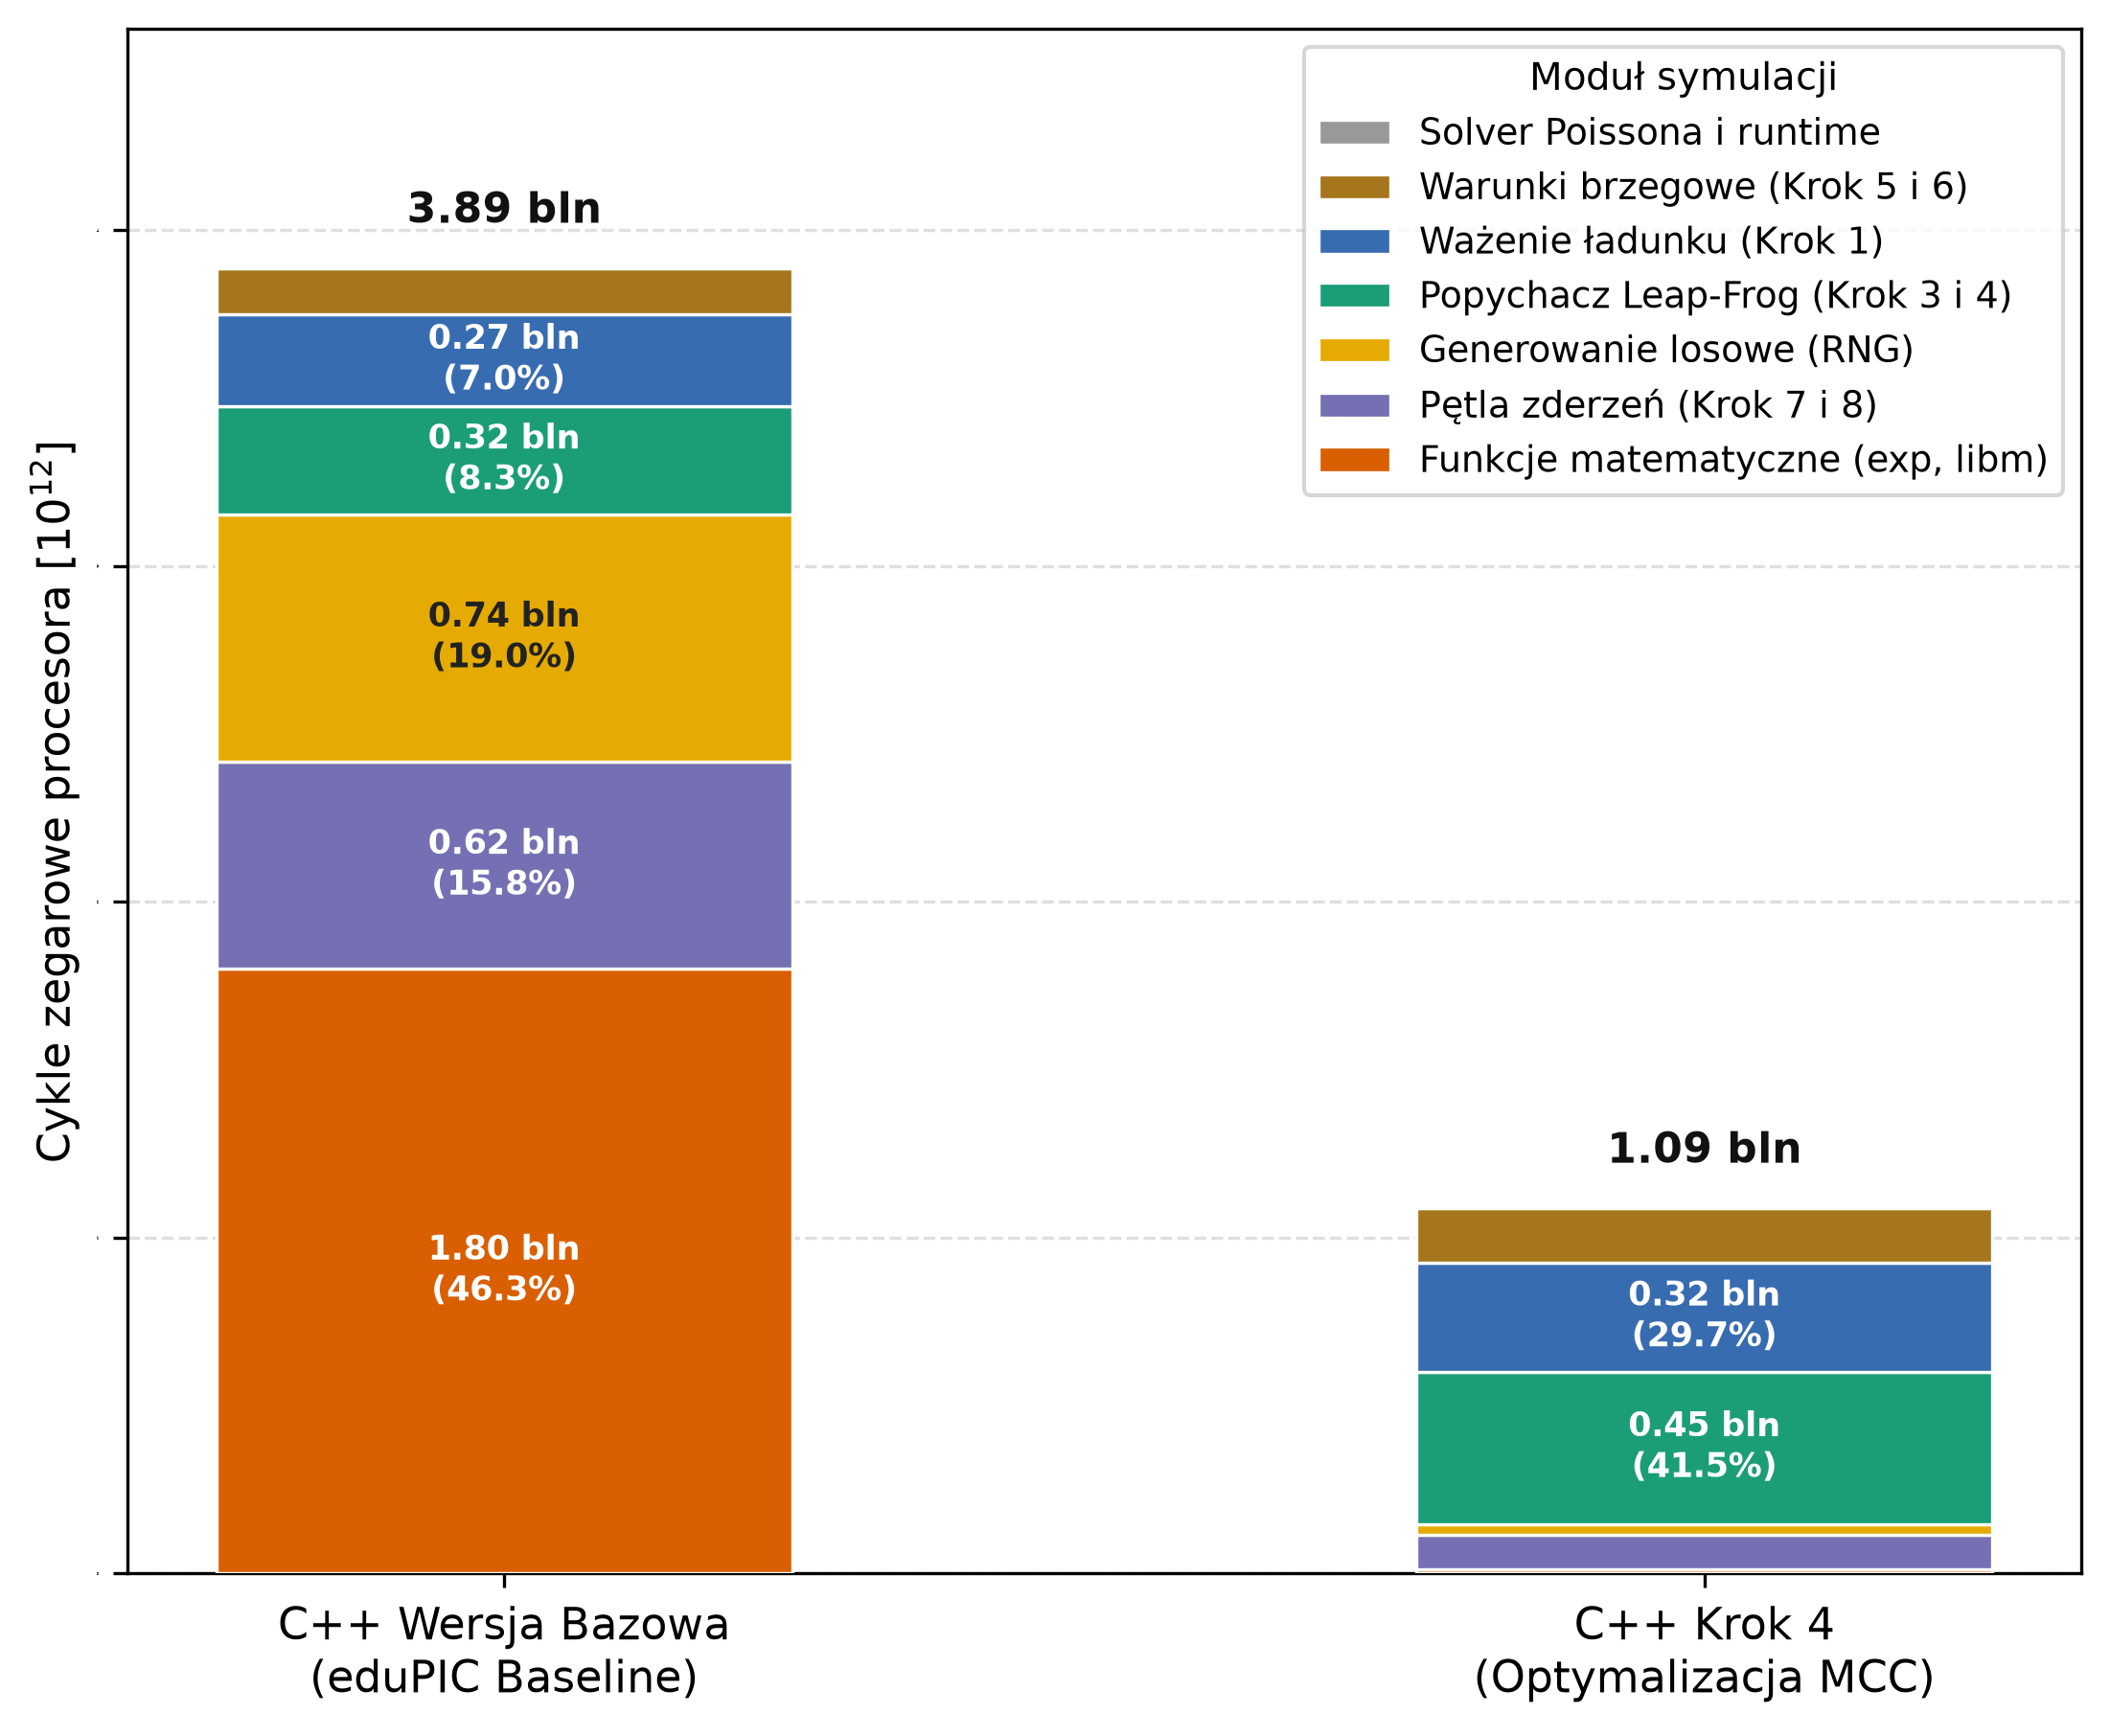

Wygenerowano Opcję A: cpp_mcc_hotspots_stacked.pdf oraz cpp_mcc_hotspots_stacked.png


In [ ]:
# OPCJA A: Ewolucja hotspotów C (Baseline vs Krok 4 Euler/Fast-Path)
# Styl w 100% zgodny z baseline_hotspots_stacked.pdf

# 1. Konfiguracja stylu akademickiego
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 12,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 11,
    'ytick.labelsize': 1,
    'figure.autolayout': True,
    'figure.dpi': 300,
})

plt.rc('legend',fontsize=14)

# 2. Kategorie (od dołu do góry słupka, tożsame z baseline_hotspots_stacked)
categories = [
    "Funkcje matematyczne (exp, libm)",
    "Pętla zderzeń (Krok 7 i 8)",
    "Generowanie losowe (RNG)",
    "Popychacz Leap-Frog (Krok 3 i 4)",
    "Ważenie ładunku (Krok 1)",
    "Warunki brzegowe (Krok 5 i 6)",
    "Solver Poissona i runtime",
]

# 3. Dane w bilionach cykli CPU (10^12)
# Baseline: 3.89 bln cykli (z oficjalnej tabeli pracy)
# Krok 4: perf.segregated (896.99 mld) przeskalowane do średniej perf stat 1.0934 bln
scale_euler = 1.09341 / 0.89699
cpp_base = [1.80109, 0.61563, 0.73792, 0.32228, 0.27172, 0.13955, 0.00418]
cpp_opt  = [
    0.01156 * scale_euler,  # funkcje matematyczne: 0.014 bln (1.29%)
    0.08316 * scale_euler,  # pętla zderzeń: 0.101 bln (9.27%)
    0.02659 * scale_euler,  # RNG: 0.032 bln (2.96%)
    0.37218 * scale_euler,  # Leap-Frog: 0.454 bln (41.49%)
    0.26642 * scale_euler,  # Ważenie CIC: 0.325 bln (29.70%)
    0.13377 * scale_euler,  # Brzegi: 0.163 bln (14.91%)
    0.00331 * scale_euler,  # Poisson i inne: 0.004 bln (0.37%)
]

cpp_base_pct = [46.27, 15.82, 18.96, 8.28, 6.98, 3.59, 0.11]
cpp_opt_pct  = [1.29, 9.27, 2.96, 41.49, 29.70, 14.91, 0.37]

colors = [
    "#d95f02",  # exp / libm - ceglasty
    "#7570b3",  # zderzenia - fiolet
    "#e6ab02",  # RNG - bursztyn
    "#1b9e77",  # Leap-Frog - szmaragd
    "#386cb0",  # depozycja ładunku - błękit
    "#a6761d",  # warunki brzegowe - ochra
    "#999999",  # Poisson i inne - szary
]

# 4. Rysowanie słupków skumulowanych
fig, ax = plt.subplots(figsize=(7.5, 6.2))
bar_width = 0.48
x_pos = [0, 1]
x_labels = ["C Wersja Bazowa\n(eduPIC Baseline)", "C Krok 4\n(Optymalizacja MCC)"]

bottom = np.zeros(2)
for i in range(len(categories)):
    vals = [cpp_base[i], cpp_opt[i]]
    p = ax.bar(
        x_pos, vals, bar_width, bottom=bottom, label=categories[i],
        color=colors[i], edgecolor="white", linewidth=0.8, zorder=3
    )
    
    # Etykiety tekstowe wewnątrz segmentów (dla pasków >= 0.14 bln)
    for j in range(2):
        val = vals[j]
        pct = cpp_base_pct[i] if j == 0 else cpp_opt_pct[i]
        if val >= 0.2:
            text_color = "white" if colors[i] not in ["#e6ab02", "#fdb462"] else "#222222"
            ax.text(
                x_pos[j], bottom[j]  val / 2.0,
                f"{val:.2f} bln\n({pct:.1f}%)",
                ha="center", va="center",
                fontsize=8.5, fontweight="bold",
                color=text_color, zorder=4
            )
    bottom = vals

# 5. Łączne sumy nad słupkami
total_base = sum(cpp_base)
total_opt  = sum(cpp_opt)
ax.text(x_pos[0], total_base  0.10, f"{total_base:.2f} bln", ha="center", va="bottom", fontsize=10.5, fontweight="bold", color="#111111")
ax.text(x_pos[1], total_opt  0.10, f"{total_opt:.2f} bln", ha="center", va="bottom", fontsize=10.5, fontweight="bold", color="#111111")

# 6. Osie, siatka i limity
ax.set_ylabel("Cykle zegarowe procesora [$10^{12}$]")
ax.set_xticks(x_pos)
ax.set_xticklabels(x_labels)
ax.set_ylim(0, 4.6)
ax.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
ax.set_axisbelow(True)

# 7. Legenda
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="upper right", frameon=True, edgecolor="#cccccc", title="Moduł symulacji", fontsize=9, title_fontsize=9.5)

# 8. Zapis wyników
out_pdf_a = "cpp_mcc_hotspots_stacked.pdf"
out_png_a = "cpp_mcc_hotspots_stacked.png"
plt.savefig(out_pdf_a, bbox_inches="tight")
plt.savefig(out_png_a, bbox_inches="tight", dpi=300)
plt.show()
print(f"Wygenerowano Opcję A: {out_pdf_a} oraz {out_png_a}")


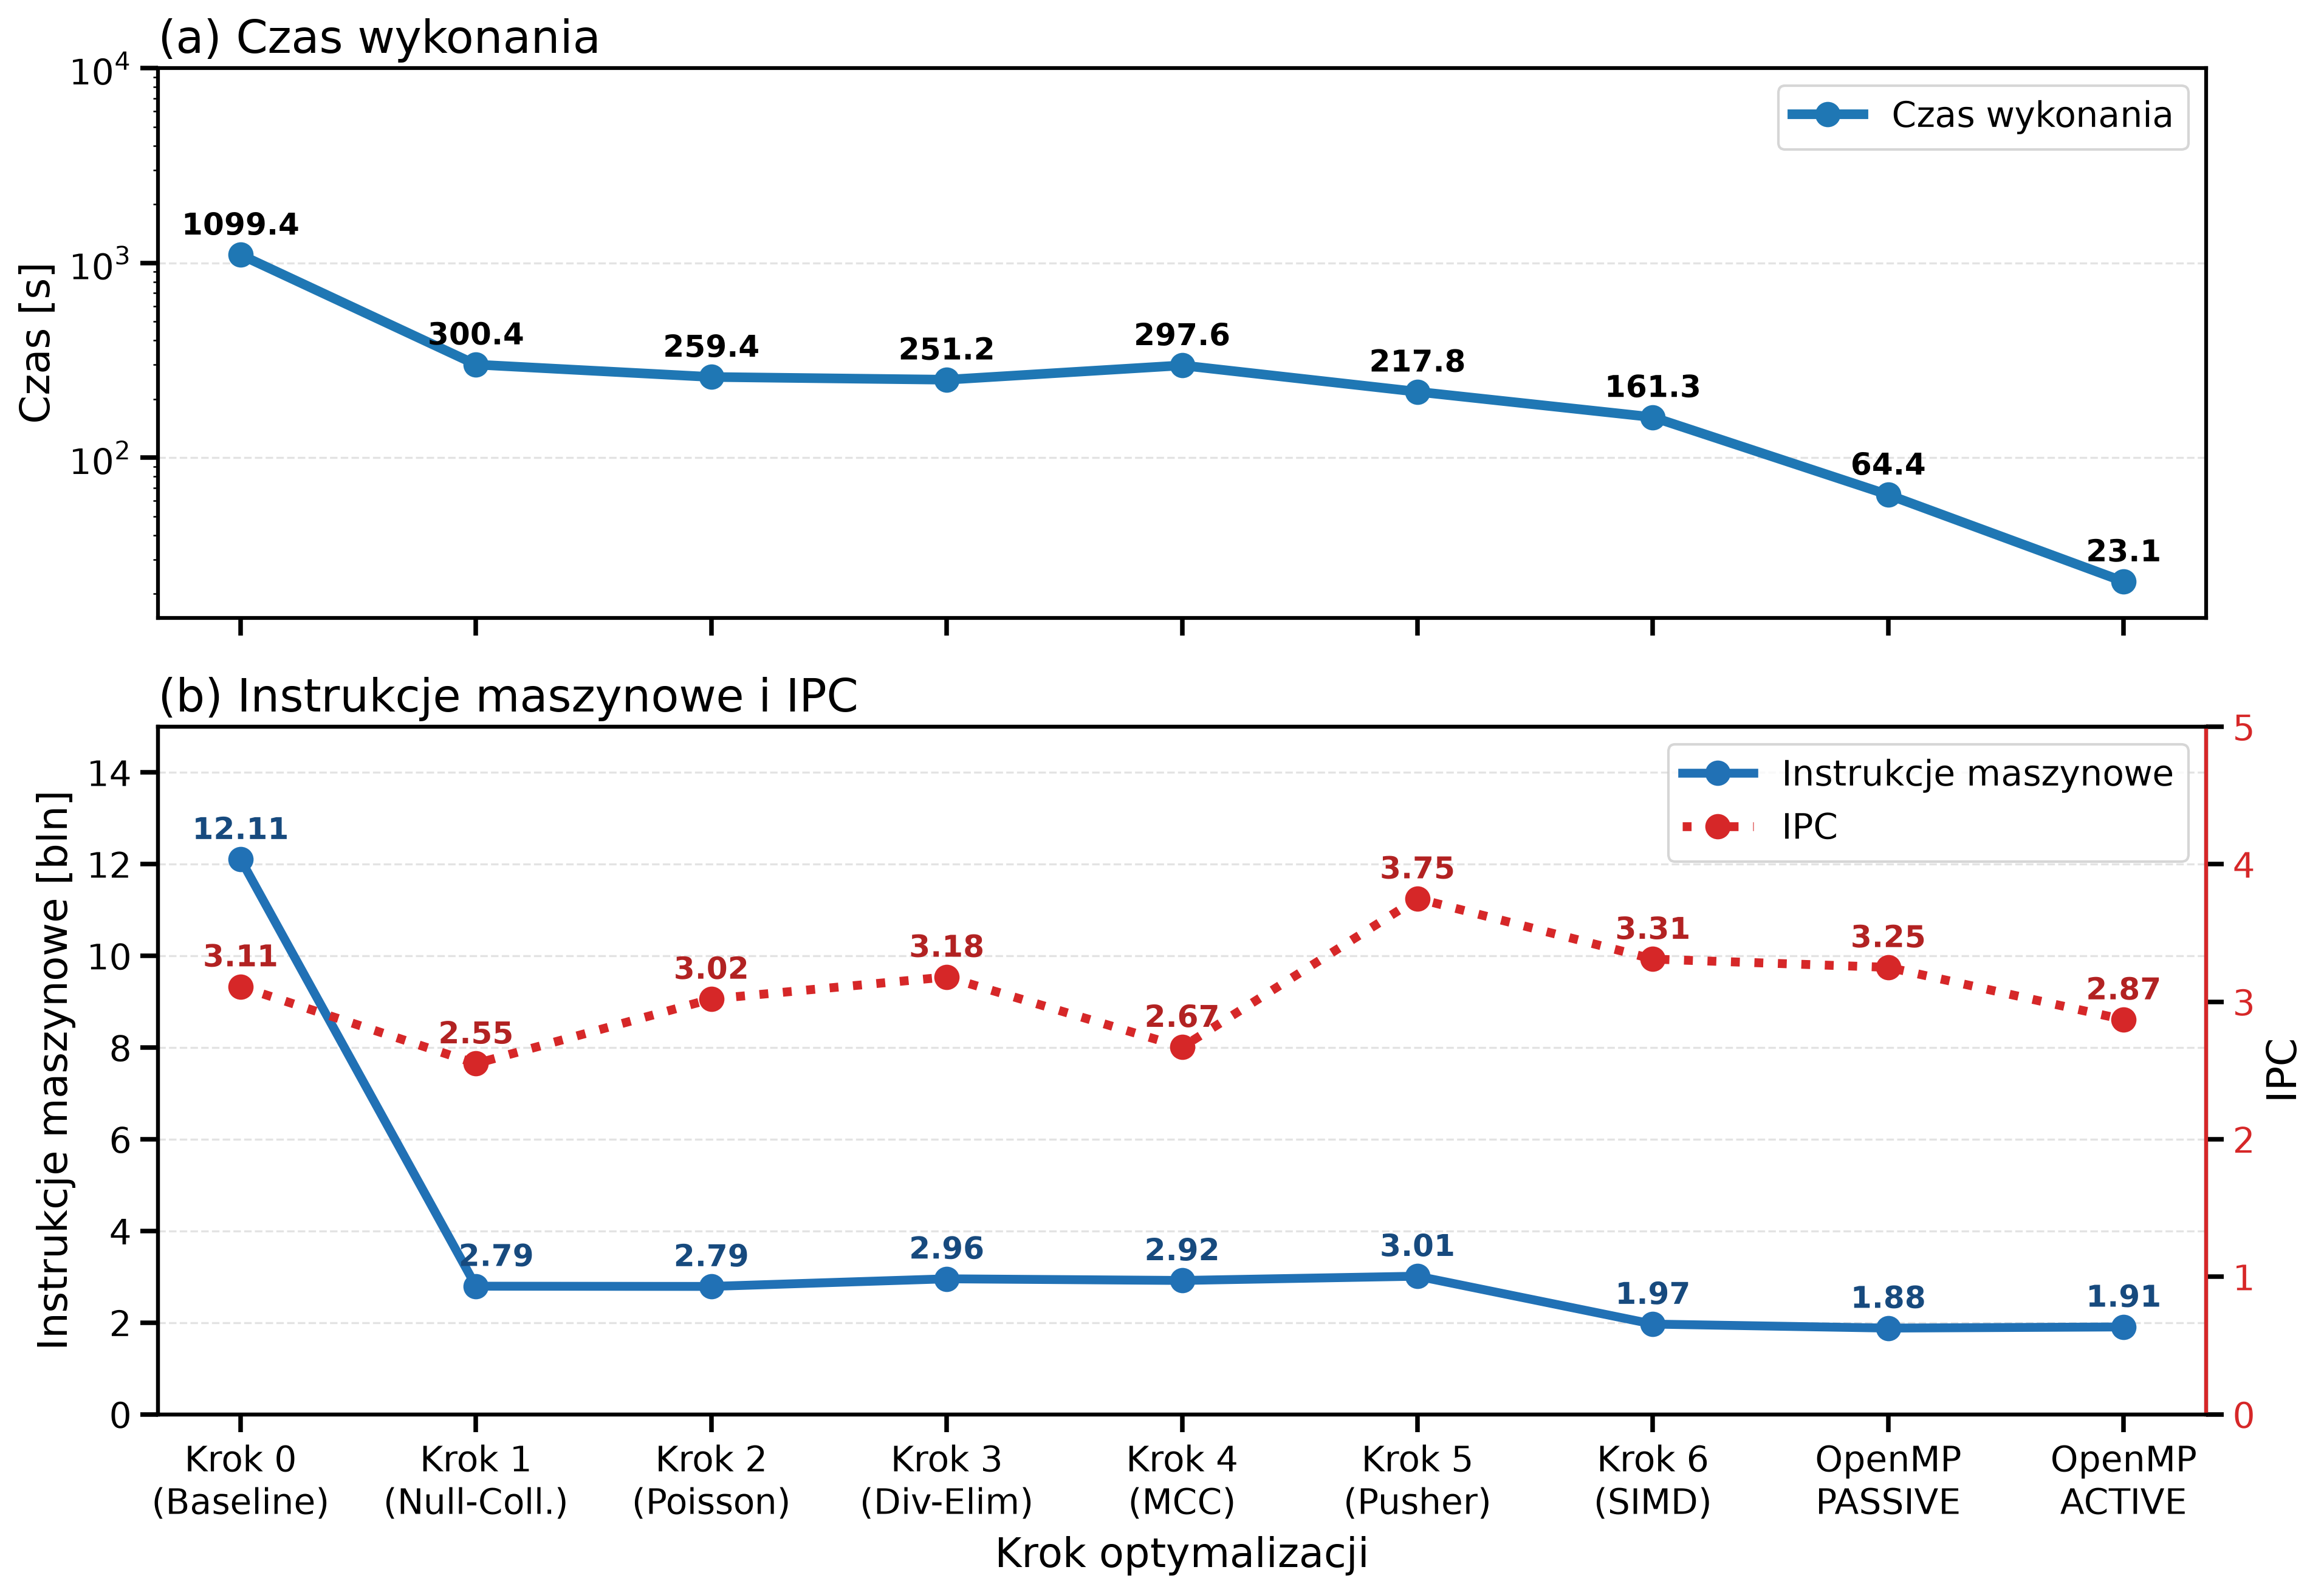

In [50]:
labels = [
    "Krok 0\n(Baseline)",
    "Krok 1\n(Null-Coll.)",
    "Krok 2\n(Poisson)",
    "Krok 3\n(Div-Elim)",
    "Krok 4\n(MCC)",
    "Krok 5\n(Pusher)",
    "Krok 6\n(SIMD)",
    "OpenMP\nPASSIVE",
    "OpenMP\nACTIVE",
]

time_s = [1099.38, 300.38, 259.45, 251.19, 297.63, 217.82, 161.32, 64.43, 23.11]
instructions_bln = [12.107, 2.794, 2.789, 2.955, 2.919, 3.012, 1.967, 1.880, 1.905]
ipc = [3.11, 2.55, 3.02, 3.18, 2.67, 3.75, 3.31, 3.25, 2.87]

# Pozycje na osi X
x = np.arange(len(labels))

plt.rcParams.update({
    "font.size": 15,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "figure.dpi": 300,
})

fig, (ax_time, ax_perf) = plt.subplots(
    2, 1,
    figsize=(13, 9),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 1.25]},
)

# ---------------------------------------------------------------------
# Panel (a): czas wykonania
# ---------------------------------------------------------------------
ax_time.plot(
    x,
    time_s,
    color="#1f77b4",
    marker="o",
    markersize=9,
    linewidth=3.8,
    label="Czas wykonania",
)

ax_time.set_yscale("log")
ax_time.set_title("(a) Czas wykonania", loc="left")
ax_time.set_ylabel("Czas [s]")
ax_time.set_ylim(15, 10000)
ax_time.set_xlim(-0.35, len(x) - 0.65)
ax_time.grid(axis="y", linestyle="--", alpha=0.35)
ax_time.legend(loc="upper right")

# Etykiety wartości nad punktami
for i, value in enumerate(time_s):
    ax_time.annotate(
        f"{value:.1f}",
        xy=(i, value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=12,
        fontweight="bold",
    )

# ---------------------------------------------------------------------
# Panel (b): instrukcje i IPC — dwie osie Y
# ---------------------------------------------------------------------

ax_perf.plot(
    x,
    instructions_bln,
    color="#2171b5",
    marker="o",
    markersize=9,
    linewidth=3.5,
    label="Instrukcje maszynowe",
)

ax_perf.set_title(
    "(b) Instrukcje maszynowe i IPC",
    loc="left",
)
ax_perf.set_ylabel("Instrukcje maszynowe [bln]")
ax_perf.set_ylim(0, 15)
ax_perf.grid(axis="y", linestyle="--", alpha=0.35)

# Etykiety liczby instrukcji
for i, value in enumerate(instructions_bln):
    offset_x = 8 if i==1 else 0
    
    ax_perf.annotate(
        f"{value:.2f}",
        xy=(i, value),
        xytext=(offset_x, 8),
        textcoords="offset points",
        ha="center",
        fontsize=12,
        fontweight="bold",
        color="#174a7e",
    )

# Druga oś Y: IPC
ax_ipc = ax_perf.twinx()

ipc_line = ax_ipc.plot(
    x,
    ipc,
    color="#d62728",
    marker="o",
    linestyle=":",
    linewidth=3.5,
    markersize=9,
    label="IPC",
)

ax_ipc.set_ylabel("IPC")
ax_ipc.set_ylim(0, 5)
ax_ipc.tick_params(axis="y", labelcolor="#d62728")
ax_ipc.spines["right"].set_color("#d62728")

# Etykiety IPC
for i, value in enumerate(ipc):
    ax_ipc.annotate(
        f"{value:.2f}",
        xy=(i, value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        color="#b22222",
        fontsize=12,
        fontweight="bold",
    )

# Wspólna legenda dla obu osi
handles_left, labels_left = ax_perf.get_legend_handles_labels()
handles_right, labels_right = ax_ipc.get_legend_handles_labels()

ax_perf.legend(
    handles_left + handles_right,
    labels_left + labels_right,
    loc="upper right",
)

# Wspólna oś X
ax_perf.set_xticks(x)
ax_perf.set_xticklabels(labels)
ax_perf.set_xlabel("Krok optymalizacji")

for ax in (ax_time, ax_perf, ax_ipc):
    ax.tick_params(
        axis="both",
        which="major",
        labelsize=14,
        width=1.8,
        length=7,
    )
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)

plt.tight_layout()

# Opcjonalny zapis do pliku
plt.savefig(
    "wykresy_optymalizacji.pdf",
    bbox_inches="tight",
)

plt.show()

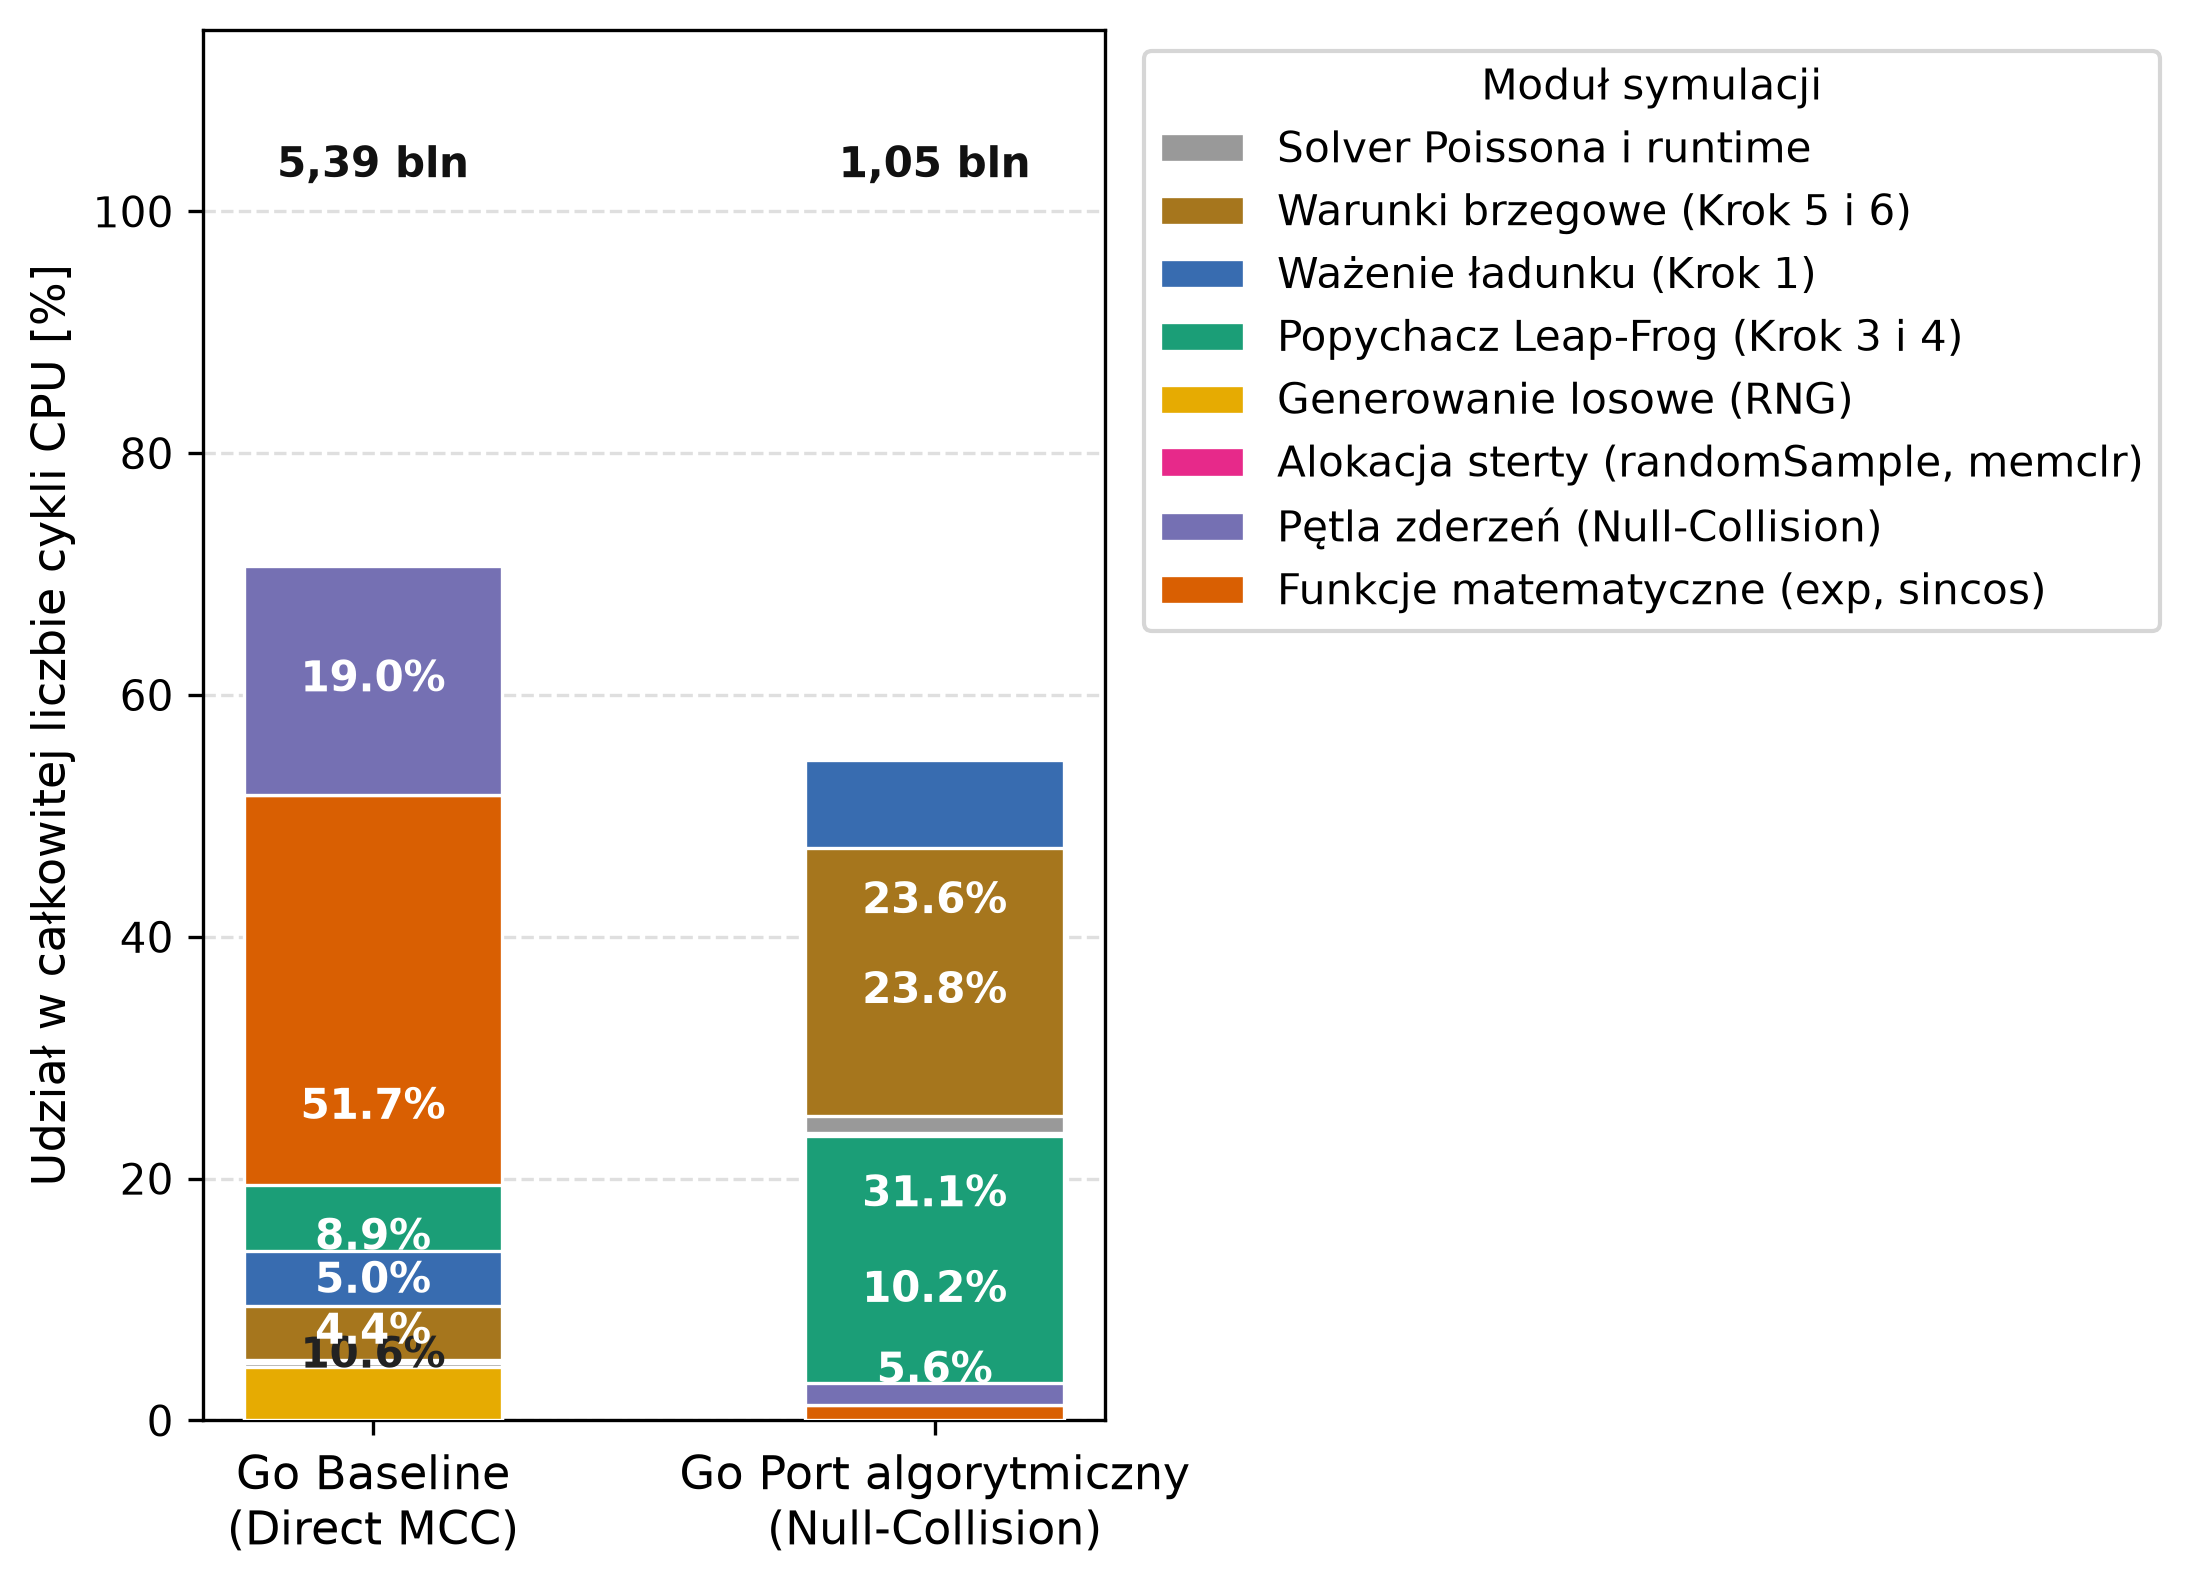

Wygenerowano: go_mcc_hotspots_stacked.pdf oraz go_mcc_hotspots_stacked.png


In [52]:
# 1. Konfiguracja stylu akademickiego (spójna z pracą)
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 11,
    'xtick.labelsize': 11,
    'ytick.labelsize': 10,
    'figure.autolayout': True,
    'figure.dpi': 300,
})

# 2. Kategorie (od dołu do góry słupka)
categories = [
    "Funkcje matematyczne (exp, sincos)",
    "Pętla zderzeń (Null-Collision)",
    "Alokacja sterty (randomSample, memclr)",  # <-- NOWE WĄSKIE GARDŁO
    "Generowanie losowe (RNG)",
    "Popychacz Leap-Frog (Krok 3 i 4)",
    "Ważenie ładunku (Krok 1)",
    "Warunki brzegowe (Krok 5 i 6)",
    "Solver Poissona i runtime",
]

# 3. Zweryfikowane dane procentowe z perf record (suma = 100%)
go_base_pct = np.array([51.71, 19.00,  0.00, 10.56,  8.95,  5.04,  4.43, 0.31])
go_opt_pct = np.array([1.24,  5.60, 10.23,  3.08, 31.09, 23.56, 23.75, 1.45])

# 4. Paleta kolorów (spójna z baseline_hotspots_stacked  wyróżnienie alokacji)
colors = [
    "#d95f02",  # exp / matematyka - ceglasty
    "#7570b3",  # zderzenia fizyczne - fiolet
    "#e7298a",  # ALOKACJA STERTY - wyrazisty amarant/róż (nowy problem)
    "#e6ab02",  # RNG - bursztyn
    "#1b9e77",  # Leap-Frog - szmaragd
    "#386cb0",  # depozycja ładunku - stonowany błękit
    "#a6761d",  # warunki brzegowe - oliwka/ochra
    "#999999",  # Poisson i inne - neutralna szarość
]

# 5. Rysowanie wykresu
fig, ax = plt.subplots(figsize=(7.4, 5.4))

x_pos = np.array([0, 1])
x_labels = ["Go Baseline\n(Direct MCC)",
            "Go Port algorytmiczny\n(Null-Collision)"]
bar_width = 0.46

bottom = np.zeros(2)

for i in range(len(categories)):
    pcts = np.array([go_base_pct[i], go_opt_pct[i]])
    ax.bar(
        x_pos, pcts, bar_width,
        bottom=bottom,
        label=categories[i],
        color=colors[i],
        edgecolor="white",
        linewidth=0.8,
        zorder=3
    )

    # Etykiety tekstowe wewnątrz segmentów (dla udziału >= 4.0%)
    for j in range(2):
        pct = pcts[j]
        if pct >= 4.0:
            text_color = "white" if colors[i] not in [
                "#e6ab02", "#fdb462"] else "#222222"
            ax.text(
                x_pos[j], bottom[j] + pct / 2.0,
                f"{pct:.1f}%",
                ha="center", va="center",
                fontsize=10, fontweight="bold",
                color=text_color,
                zorder=4
            )

    bottom = pcts

# 6. Łączne liczby cykli nad słupkami (skala globalna)
ax.text(x_pos[0], 102.0, "5,39 bln",
        ha="center", va="bottom", fontsize=10, fontweight="bold", color="#111111")
ax.text(x_pos[1], 102.0, "1,05 bln",
        ha="center", va="bottom", fontsize=10, fontweight="bold", color="#111111")

# 7. Osie i formatowanie
ax.set_ylabel("Udział w całkowitej liczbie cykli CPU [%]")
ax.set_xticks(x_pos)
ax.set_xticklabels(x_labels)
ax.set_ylim(0, 115)  # miejsce na adnotacje nad słupkami
ax.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
ax.set_axisbelow(True)

# 8. Legenda z odwróconą kolejnością (zgodna ze słupkami od góry)
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles[::-1], labels[::-1],
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    frameon=True,
    edgecolor="#cccccc",
    title="Moduł symulacji",
    title_fontsize=10,
    fontsize=10
)

# 9. Zapis wyników
out_pdf = "go_mcc_hotspots_stacked.pdf"
out_png = "go_mcc_hotspots_stacked.png"
plt.savefig(out_pdf, bbox_inches="tight")
plt.savefig(out_png, bbox_inches="tight", dpi=300)
plt.show()
print(f"Wygenerowano: {out_pdf} oraz {out_png}")

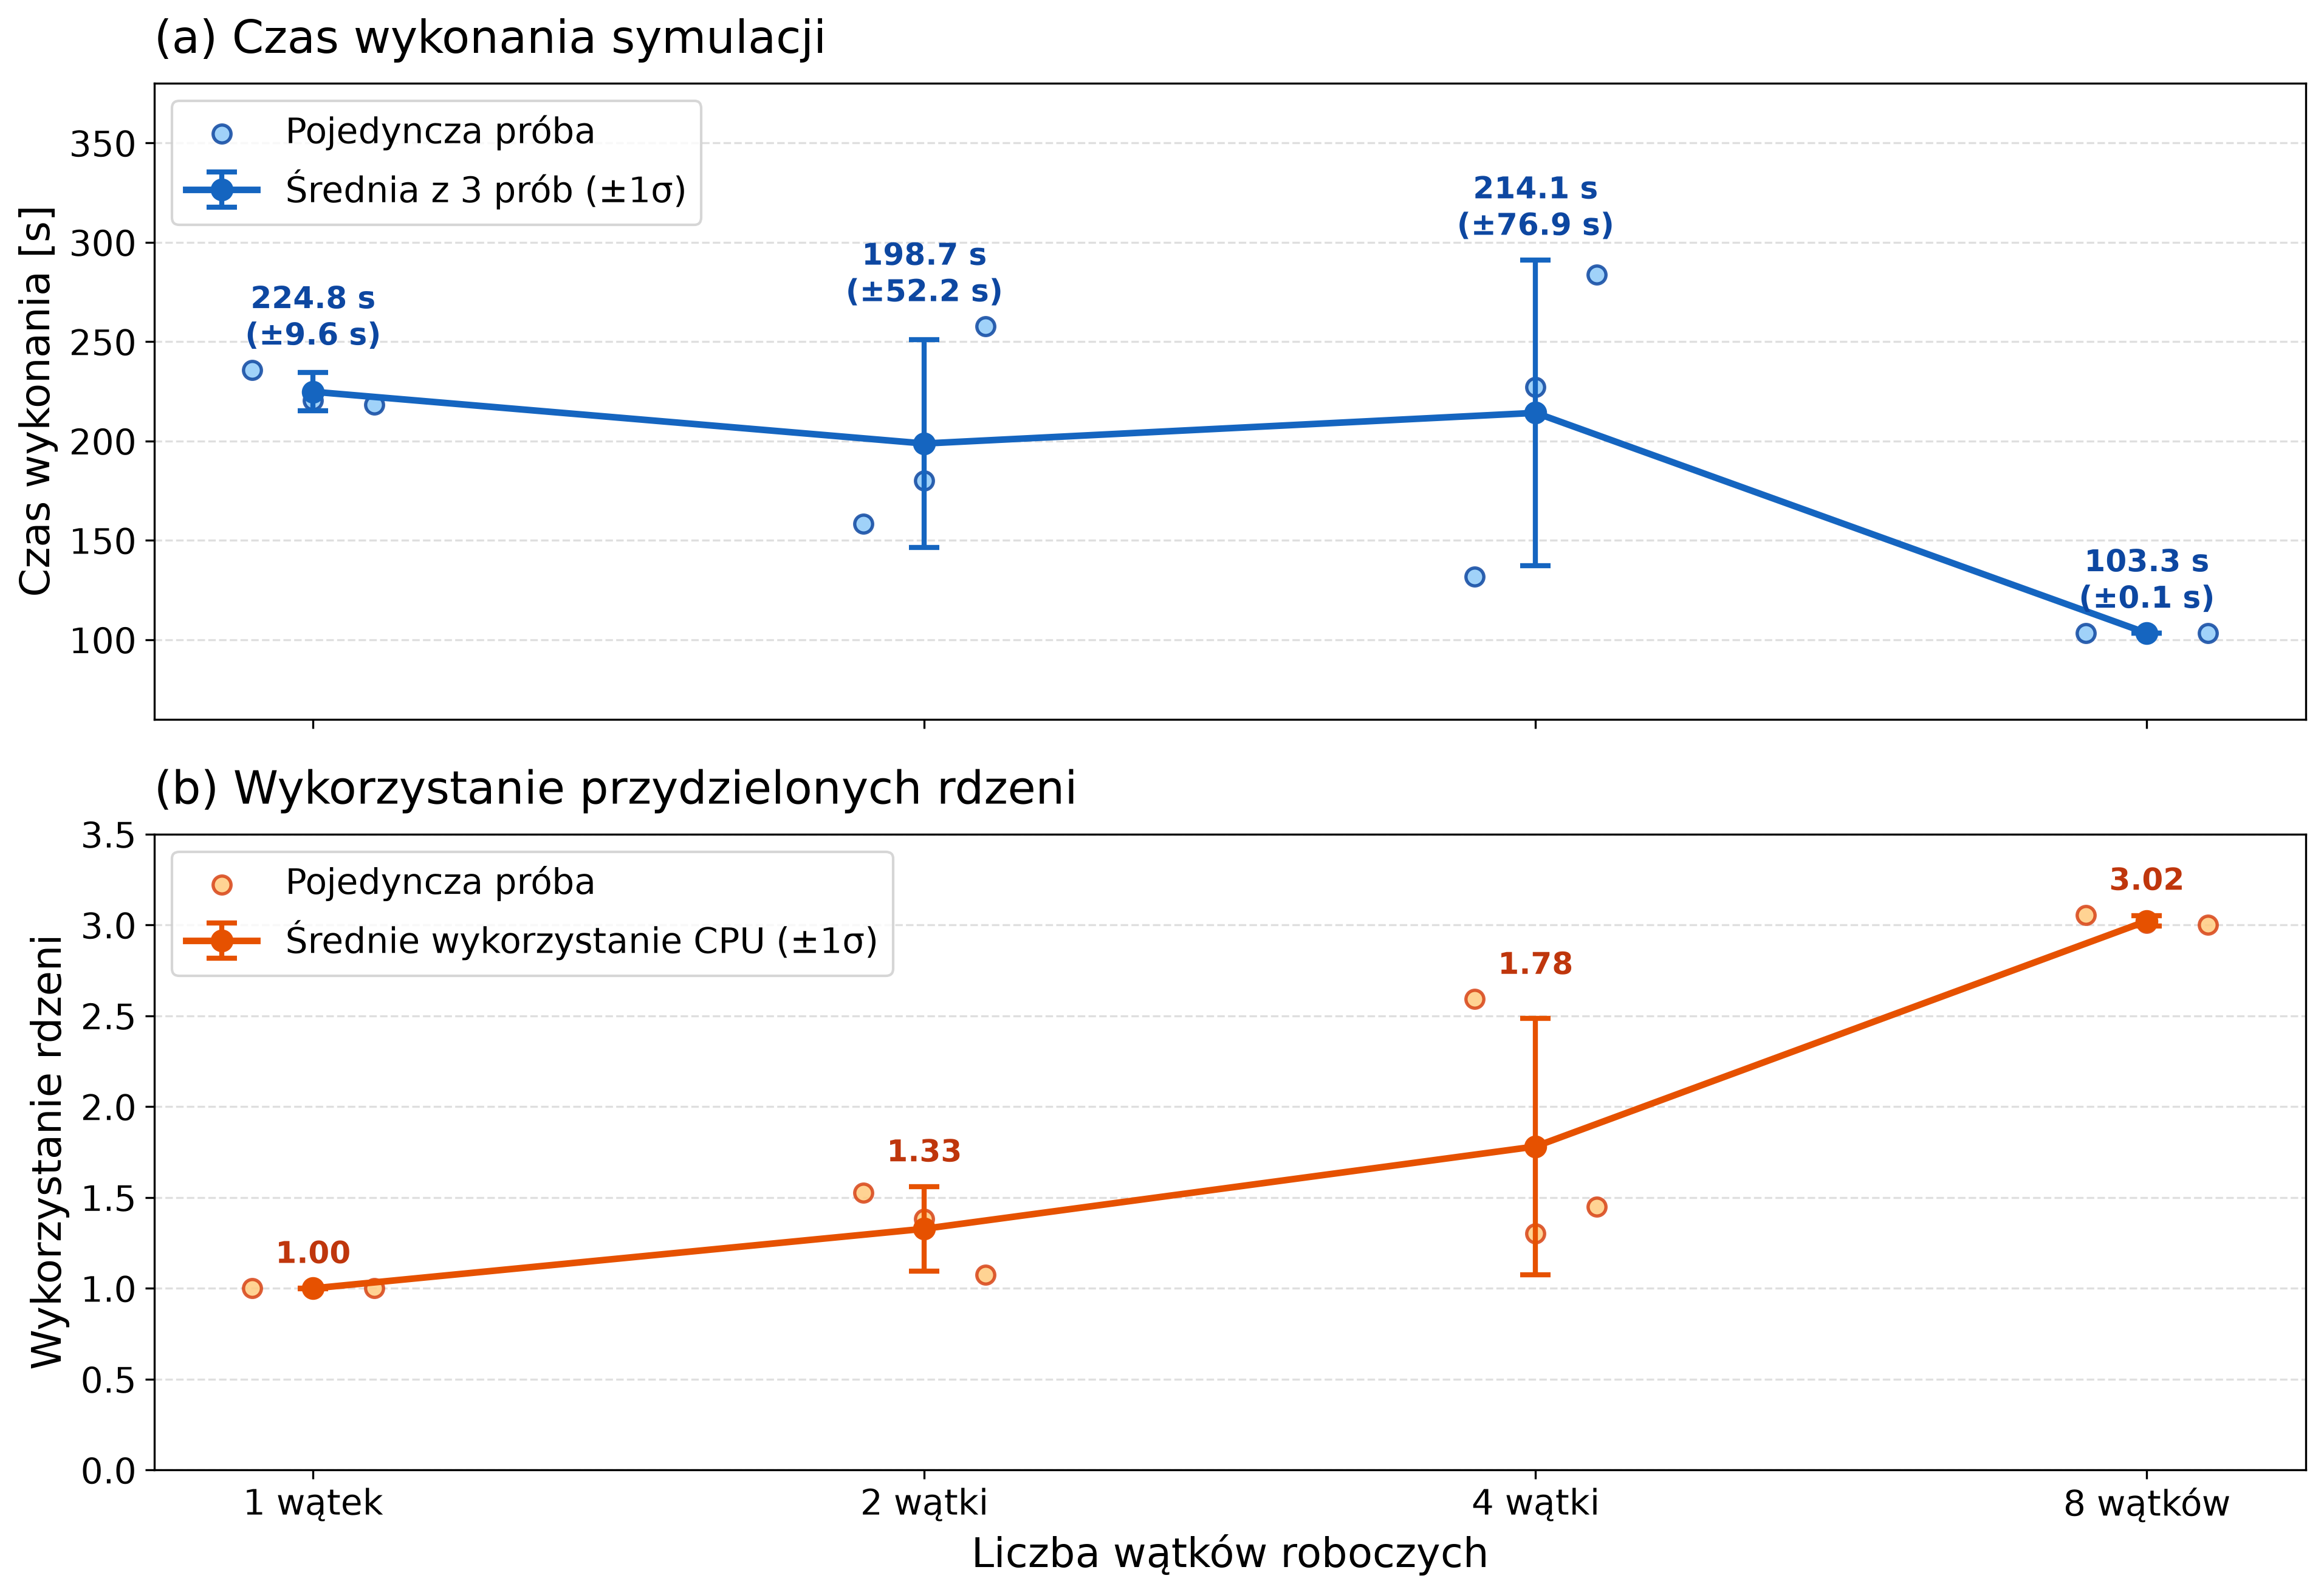

In [ ]:
# 1. Konfiguracja stylu akademickiego spójnego z pracą magisterską
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 15,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "figure.dpi": 300,
})

# 2. Surowe dane z 3 niezależnych prób pomiarowych na klastrze LEM (100 cykli RF, 8 rdzeni CCX)
workers = [1, 2, 4, 8]
x_pos = np.arange(len(workers))
x_labels = ["1 wątek", "2 wątki", "4 wątki", "8 wątków"]

times_raw = {
    1: [235.75, 220.33, 218.17],
    2: [158.40, 180.08, 257.61],
    4: [131.62, 227.10, 283.69],
    8: [103.23, 103.34, 103.30],
}

cpus_raw = {
    1: [1.000, 0.999, 0.999],
    2: [1.527, 1.382, 1.073],
    4: [2.591, 1.302, 1.448],
    8: [3.054, 3.010, 3.000],
}

# Średnie i odchylenia standardowe (próba, n=3)
means_time = [np.mean(times_raw[w]) for w in workers]
stds_time  = [np.std(times_raw[w], ddof=1) for w in workers]

means_cpu = [np.mean(cpus_raw[w]) for w in workers]
stds_cpu = [np.std(cpus_raw[w], ddof=1) for w in workers]

# 3. Tworzenie dwupanelowego wykresu
fig, (ax1, ax2) = plt.subplots(
    2, 1, 
    figsize=(13, 9),
    sharex=True)

# ---------------------------------------------------------------------
# Panel (a): Czas wykonania (3 próby  średnia ze słupkami błędu)
# ---------------------------------------------------------------------
jitter = np.array([-0.10, 0.0, 0.10])

# Punkty pojedynczych prób
for i, w in enumerate(workers):
    vals = times_raw[w]
    ax1.scatter(
        i  jitter, vals,
        color="#90caf9", edgecolors="#0d47a1", s=50, linewidths=1.3,
        alpha=0.85, zorder=4,
        label="Pojedyncza próba" if i == 0 else ""
    )

# Średnia z wąsami błędu (±1σ)
ax1.errorbar(
    x_pos, means_time, yerr=stds_time,
    fmt="o-", color="#1565c0", linewidth=2.6, markersize=8,
    capsize=6, capthick=2.0, elinewidth=2.0, zorder=5,
    label="Średnia z 3 prób (±1σ)"
)

ax1.set_title("(a) Czas wykonania symulacji", loc="left", pad=12)
ax1.set_ylabel("Czas wykonania [s]")
ax1.set_xticks(x_pos)
ax1.set_xticklabels(x_labels)
ax1.set_ylim(60, 380)
ax1.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
ax1.legend(loc="upper left", frameon=True, edgecolor="#cccccc")

# Etykiety tekstowe nad słupkami błędu
for i, (m, s) in enumerate(zip(means_time, stds_time)):
    top_val = max(m  s, max(times_raw[workers[i]]))
    ax1.annotate(
        f"{m:.1f} s\n(±{s:.1f} s)",
        xy=(i, top_val), xytext=(0, 10),
        textcoords="offset points", ha="center",
        fontsize=12, fontweight="bold", color="#0d47a1", zorder=6
    )

# ---------------------------------------------------------------------
# Panel (b): Zuzycie CPU
# ---------------------------------------------------------------------

for i, w in enumerate(workers):
    s_vals = cpus_raw[w]
    ax2.scatter(
        i  jitter, s_vals,
        color="#ffcc80", edgecolors="#d84315", s=50, linewidths=1.3,
        alpha=0.85, zorder=4,
        label="Pojedyncza próba" if i == 0 else ""
    )

ax2.errorbar(
    x_pos, means_cpu, yerr=stds_cpu,
    fmt="o-", color="#e65100", linewidth=2.6, markersize=8,
    capsize=6, capthick=2.0, elinewidth=2.0, zorder=5,
    label="Średnie wykorzystanie CPU (±1σ)"
)

ax2.set_title("(b) Wykorzystanie przydzielonych rdzeni", loc="left", pad=12)
ax2.set_xlabel("Liczba wątków roboczych")
ax2.set_ylabel("Wykorzystanie rdzeni")
ax2.set_xticks(x_pos)
ax2.set_xticklabels(x_labels)
ax2.set_ylim(0, 3.5)
ax2.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
ax2.legend(loc="upper left", frameon=True, edgecolor="#cccccc")

# Etykiety przyspieszenia nad punktami
for i, (m, s) in enumerate(zip(means_cpu, stds_cpu)):
    top_s = max(m  s, max(cpus_raw[workers[i]]))
    ax2.annotate(
        f"{m:.2f}",
        xy=(i, top_s), xytext=(0, 10),
        textcoords="offset points", ha="center",
        fontsize=12, fontweight="bold", color="#bf360c", zorder=6
    )

plt.tight_layout()

out_pdf = "channels_skalowanie.pdf"
plt.savefig(out_pdf, bbox_inches="tight")


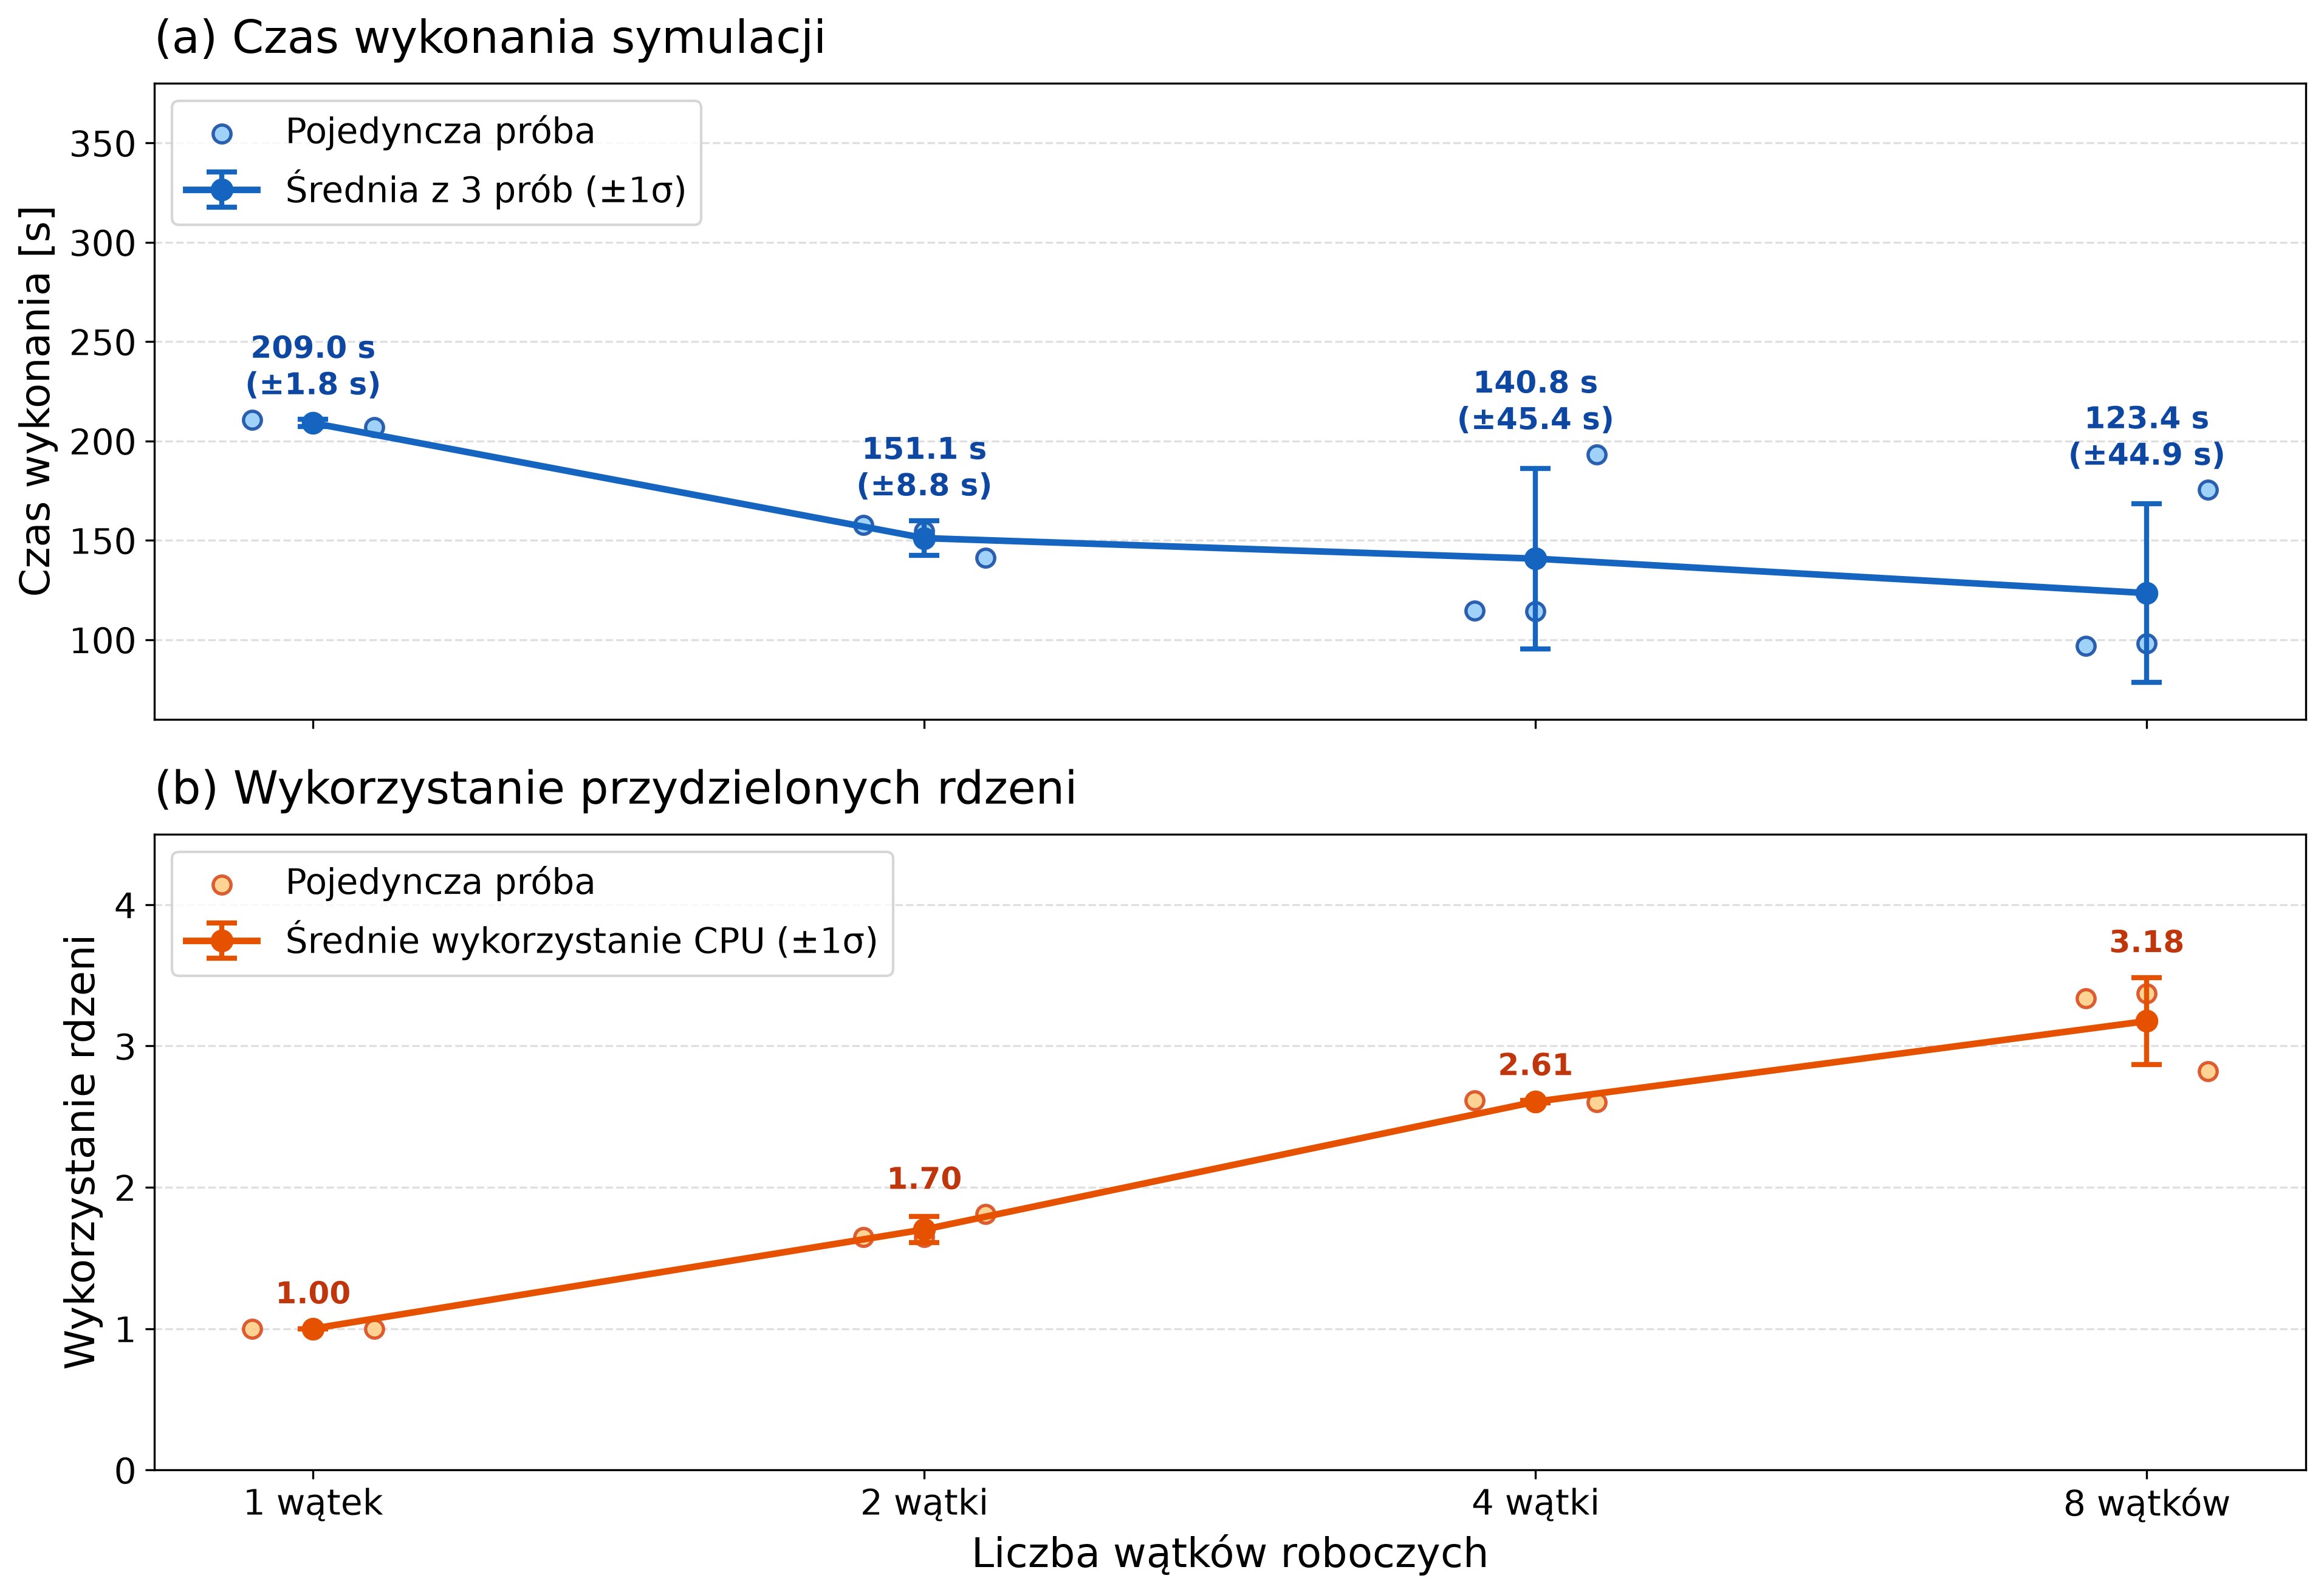

In [ ]:
# 1. Konfiguracja stylu akademickiego spójnego z pracą magisterską
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 15,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "figure.dpi": 300,
})

# 2. Surowe dane z 3 niezależnych prób pomiarowych na klastrze LEM (100 cykli RF, 8 rdzeni CCX)
workers = [1, 2, 4, 8]
x_pos = np.arange(len(workers))
x_labels = ["1 wątek", "2 wątki", "4 wątki", "8 wątków"]

times_raw = {
    1: [210.53, 209.39, 207.01],
    2: [157.57, 154.63, 141.07],
    4: [114.64, 114.40, 193.24],
    8: [96.95,  98.06,  175.31],
}

cpus_raw = {
    1: [1.000, 1.000, 1.000],
    2: [1.649, 1.646, 1.810],
    4: [2.615, 2.600, 2.603],
    8: [3.337, 3.372, 2.820],
}

# Średnie i odchylenia standardowe (próba, n=3)
means_time = [np.mean(times_raw[w]) for w in workers]
stds_time  = [np.std(times_raw[w], ddof=1) for w in workers]

means_cpu = [np.mean(cpus_raw[w]) for w in workers]
stds_cpu = [np.std(cpus_raw[w], ddof=1) for w in workers]

# 3. Tworzenie dwupanelowego wykresu
fig, (ax1, ax2) = plt.subplots(
    2, 1, 
    figsize=(13, 9),
    sharex=True)

# ---------------------------------------------------------------------
# Panel (a): Czas wykonania (3 próby  średnia ze słupkami błędu)
# ---------------------------------------------------------------------
jitter = np.array([-0.10, 0.0, 0.10])

# Punkty pojedynczych prób
for i, w in enumerate(workers):
    vals = times_raw[w]
    ax1.scatter(
        i  jitter, vals,
        color="#90caf9", edgecolors="#0d47a1", s=50, linewidths=1.3,
        alpha=0.85, zorder=4,
        label="Pojedyncza próba" if i == 0 else ""
    )

# Średnia z wąsami błędu (±1σ)
ax1.errorbar(
    x_pos, means_time, yerr=stds_time,
    fmt="o-", color="#1565c0", linewidth=2.6, markersize=8,
    capsize=6, capthick=2.0, elinewidth=2.0, zorder=5,
    label="Średnia z 3 prób (±1σ)"
)

ax1.set_title("(a) Czas wykonania symulacji", loc="left", pad=12)
ax1.set_ylabel("Czas wykonania [s]")
ax1.set_xticks(x_pos)
ax1.set_xticklabels(x_labels)
ax1.set_ylim(60, 380)
ax1.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
ax1.legend(loc="upper left", frameon=True, edgecolor="#cccccc")

# Etykiety tekstowe nad słupkami błędu
for i, (m, s) in enumerate(zip(means_time, stds_time)):
    top_val = max(m  s, max(times_raw[workers[i]]))
    ax1.annotate(
        f"{m:.1f} s\n(±{s:.1f} s)",
        xy=(i, top_val), xytext=(0, 10),
        textcoords="offset points", ha="center",
        fontsize=12, fontweight="bold", color="#0d47a1", zorder=6
    )

# ---------------------------------------------------------------------
# Panel (b): Zuzycie CPU
# ---------------------------------------------------------------------

for i, w in enumerate(workers):
    s_vals = cpus_raw[w]
    ax2.scatter(
        i  jitter, s_vals,
        color="#ffcc80", edgecolors="#d84315", s=50, linewidths=1.3,
        alpha=0.85, zorder=4,
        label="Pojedyncza próba" if i == 0 else ""
    )

ax2.errorbar(
    x_pos, means_cpu, yerr=stds_cpu,
    fmt="o-", color="#e65100", linewidth=2.6, markersize=8,
    capsize=6, capthick=2.0, elinewidth=2.0, zorder=5,
    label="Średnie wykorzystanie CPU (±1σ)"
)

ax2.set_title("(b) Wykorzystanie przydzielonych rdzeni", loc="left", pad=12)
ax2.set_xlabel("Liczba wątków roboczych")
ax2.set_ylabel("Wykorzystanie rdzeni")
ax2.set_xticks(x_pos)
ax2.set_xticklabels(x_labels)
ax2.set_ylim(0, 4.5)
ax2.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
ax2.legend(loc="upper left", frameon=True, edgecolor="#cccccc")

# Etykiety przyspieszenia nad punktami
for i, (m, s) in enumerate(zip(means_cpu, stds_cpu)):
    top_s = max(m  s, max(cpus_raw[workers[i]]))
    ax2.annotate(
        f"{m:.2f}",
        xy=(i, top_s), xytext=(0, 10),
        textcoords="offset points", ha="center",
        fontsize=12, fontweight="bold", color="#bf360c", zorder=6
    )

plt.tight_layout()

out_pdf = "chunking_skalowanie.pdf"
plt.savefig(out_pdf, bbox_inches="tight")


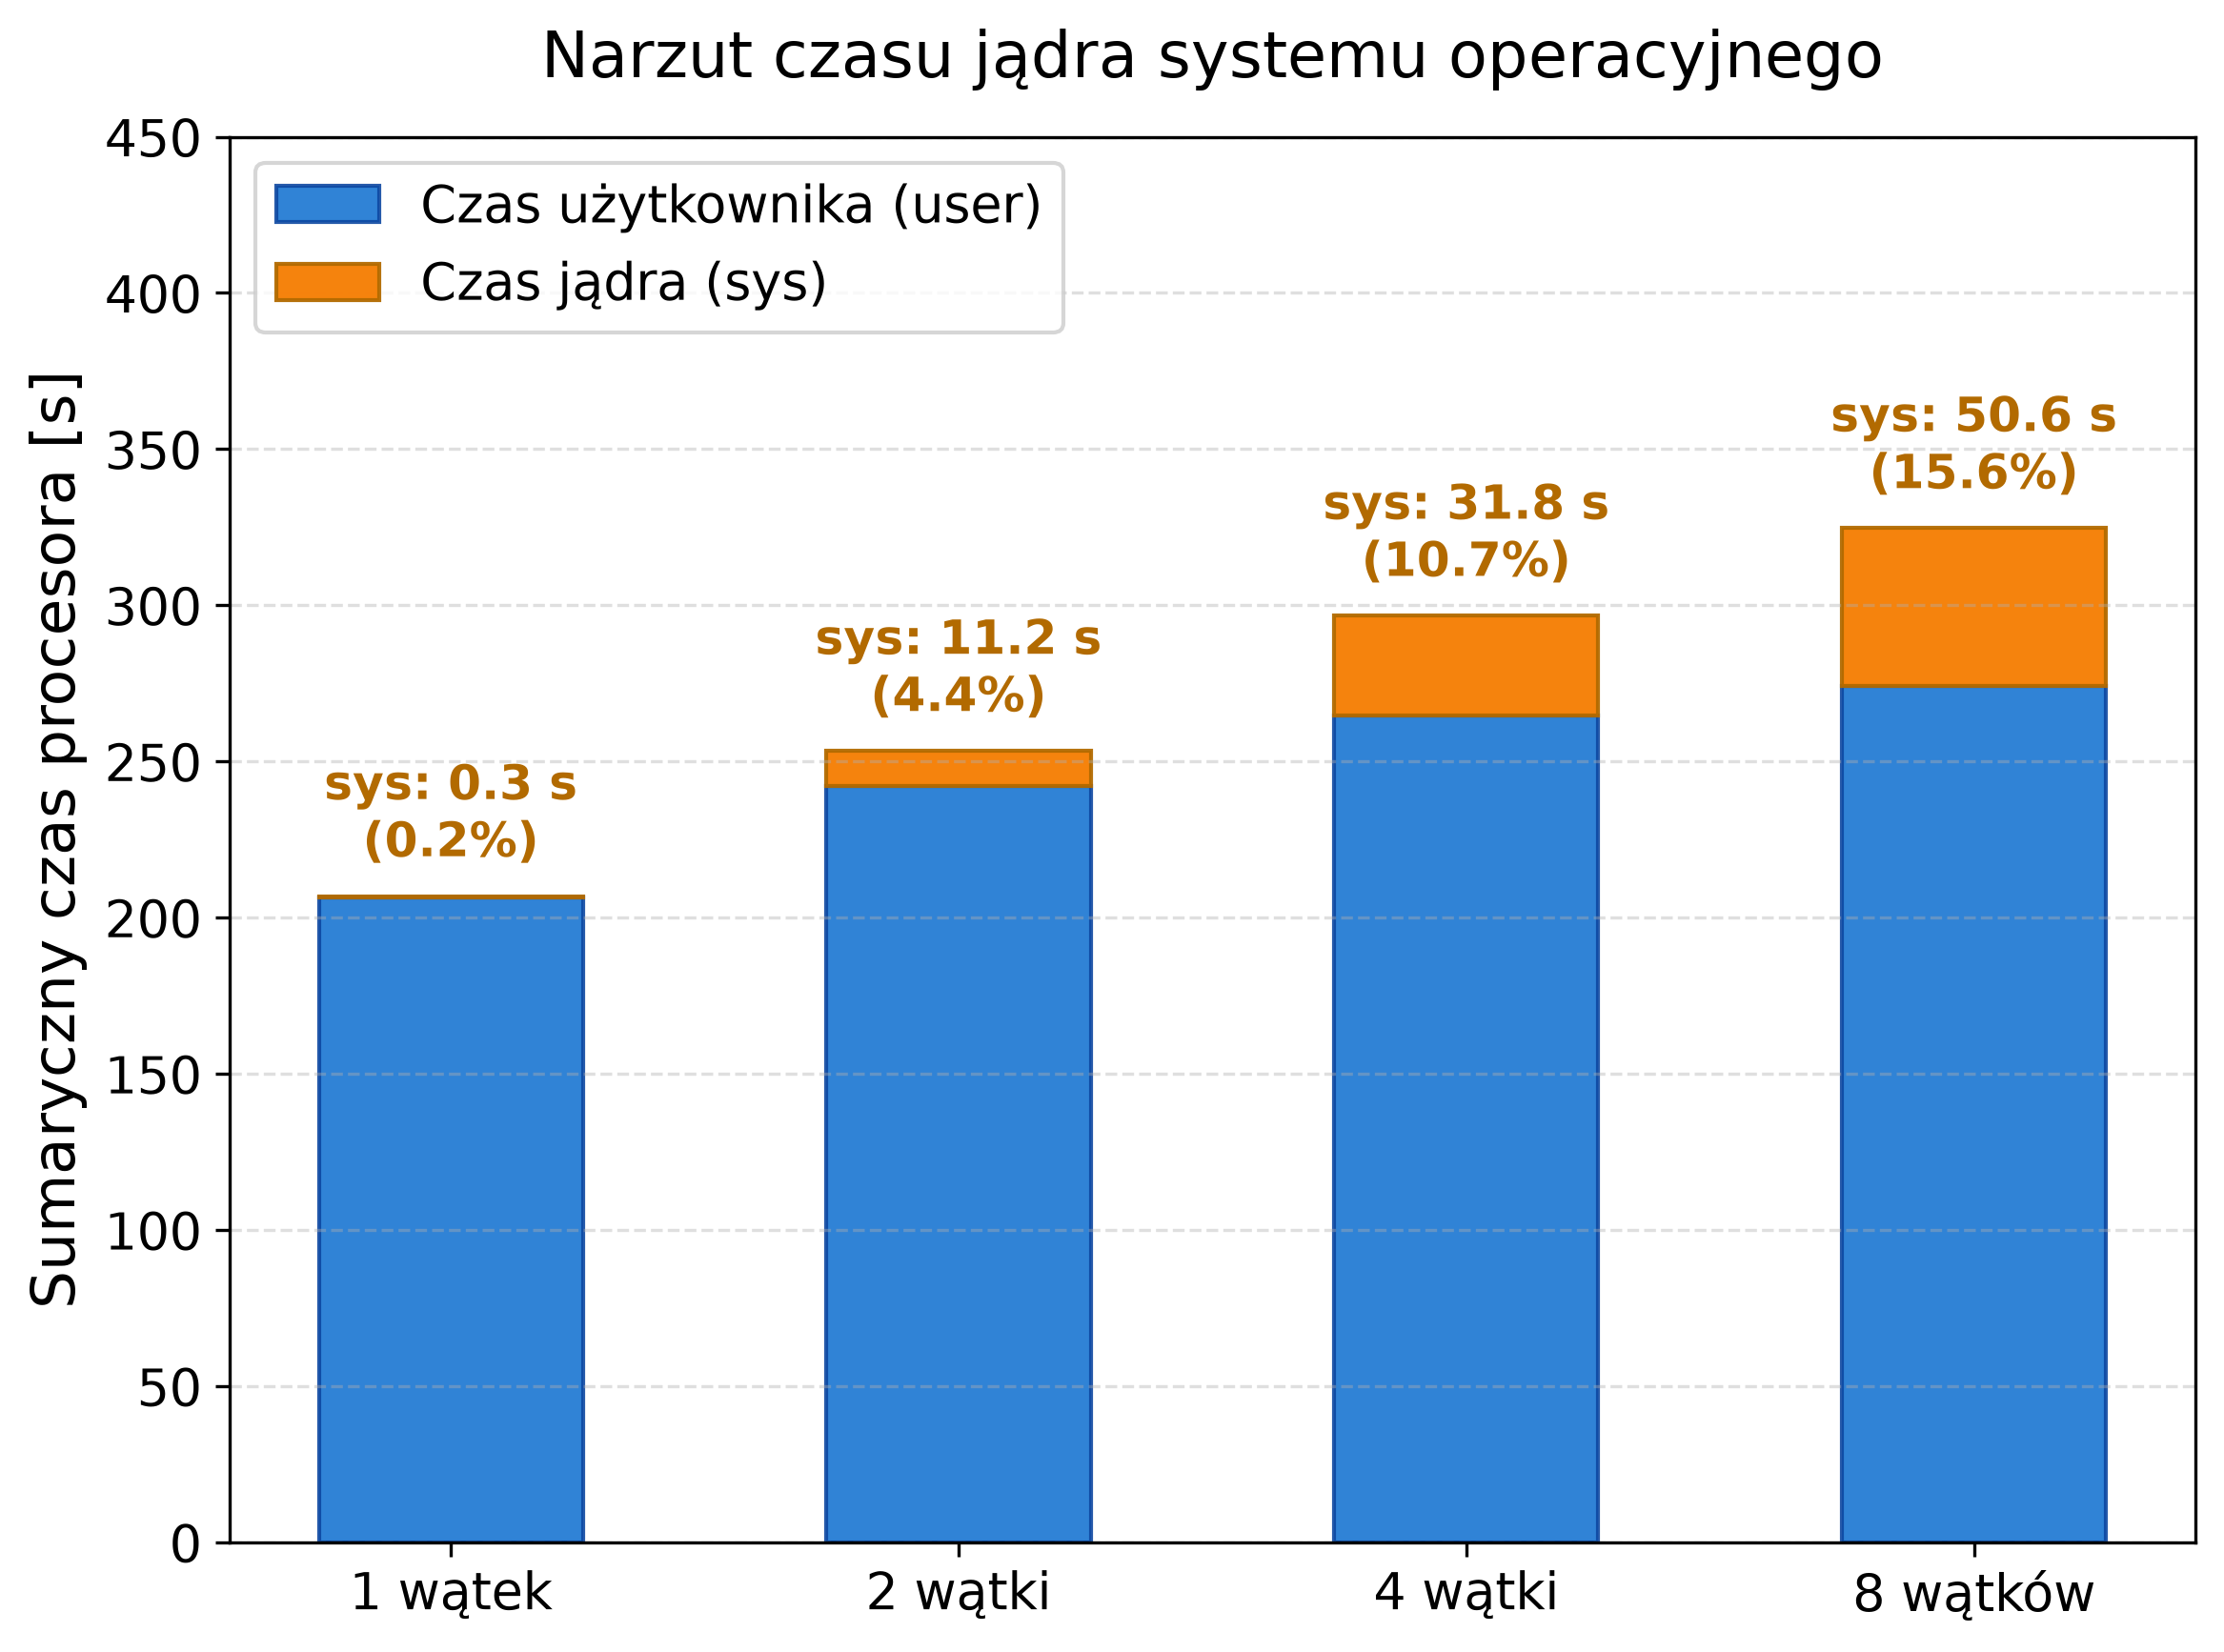

In [54]:
# Konfiguracja stylu spójnego z pracą
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 15,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 13,
    "figure.dpi": 300,
})

labels = ["1 wątek", "2 wątki", "4 wątki", "8 wątków"]
user_times = [206.52, 242.10, 264.76, 274.12]
sys_times = [0.32,  11.24,  31.83,  50.57]

total_cpu_times = [u + s for u, s in zip(user_times, sys_times)]
sys_pct = [s / (u + s) * 100 for u, s in zip(user_times, sys_times)]

x = np.arange(len(labels))
width = 0.52

fig, ax = plt.subplots(figsize=(8, 6))

# Słupki skumulowane: user na dole, sys na górze
p1 = ax.bar(x, user_times, width, label="Czas użytkownika (user)",
            color="#1976d2", edgecolor="#0d47a1", alpha=0.9)
p2 = ax.bar(x, sys_times, width, bottom=user_times, label="Czas jądra (sys)", color="#f57c00", edgecolor="#b26a00",
            alpha=0.95)

ax.set_ylabel("Sumaryczny czas procesora [s]")
ax.set_title("Narzut czasu jądra systemu operacyjnego", pad=15)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 450)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(loc="upper left", frameon=True, edgecolor="#cccccc")

# Etykiety nad słupkami pokazujące czas sys oraz udział procentowy
for i, (tot, s, pct) in enumerate(zip(total_cpu_times, sys_times, sys_pct)):
    ax.annotate(
        f"sys: {s:.1f} s\n({pct:.1f}%)",
        xy=(i, tot),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold",
        color="#b26a00"
    )

plt.tight_layout()
plt.savefig("go_chunking_sys_overhead.pdf",
            bbox_inches="tight")

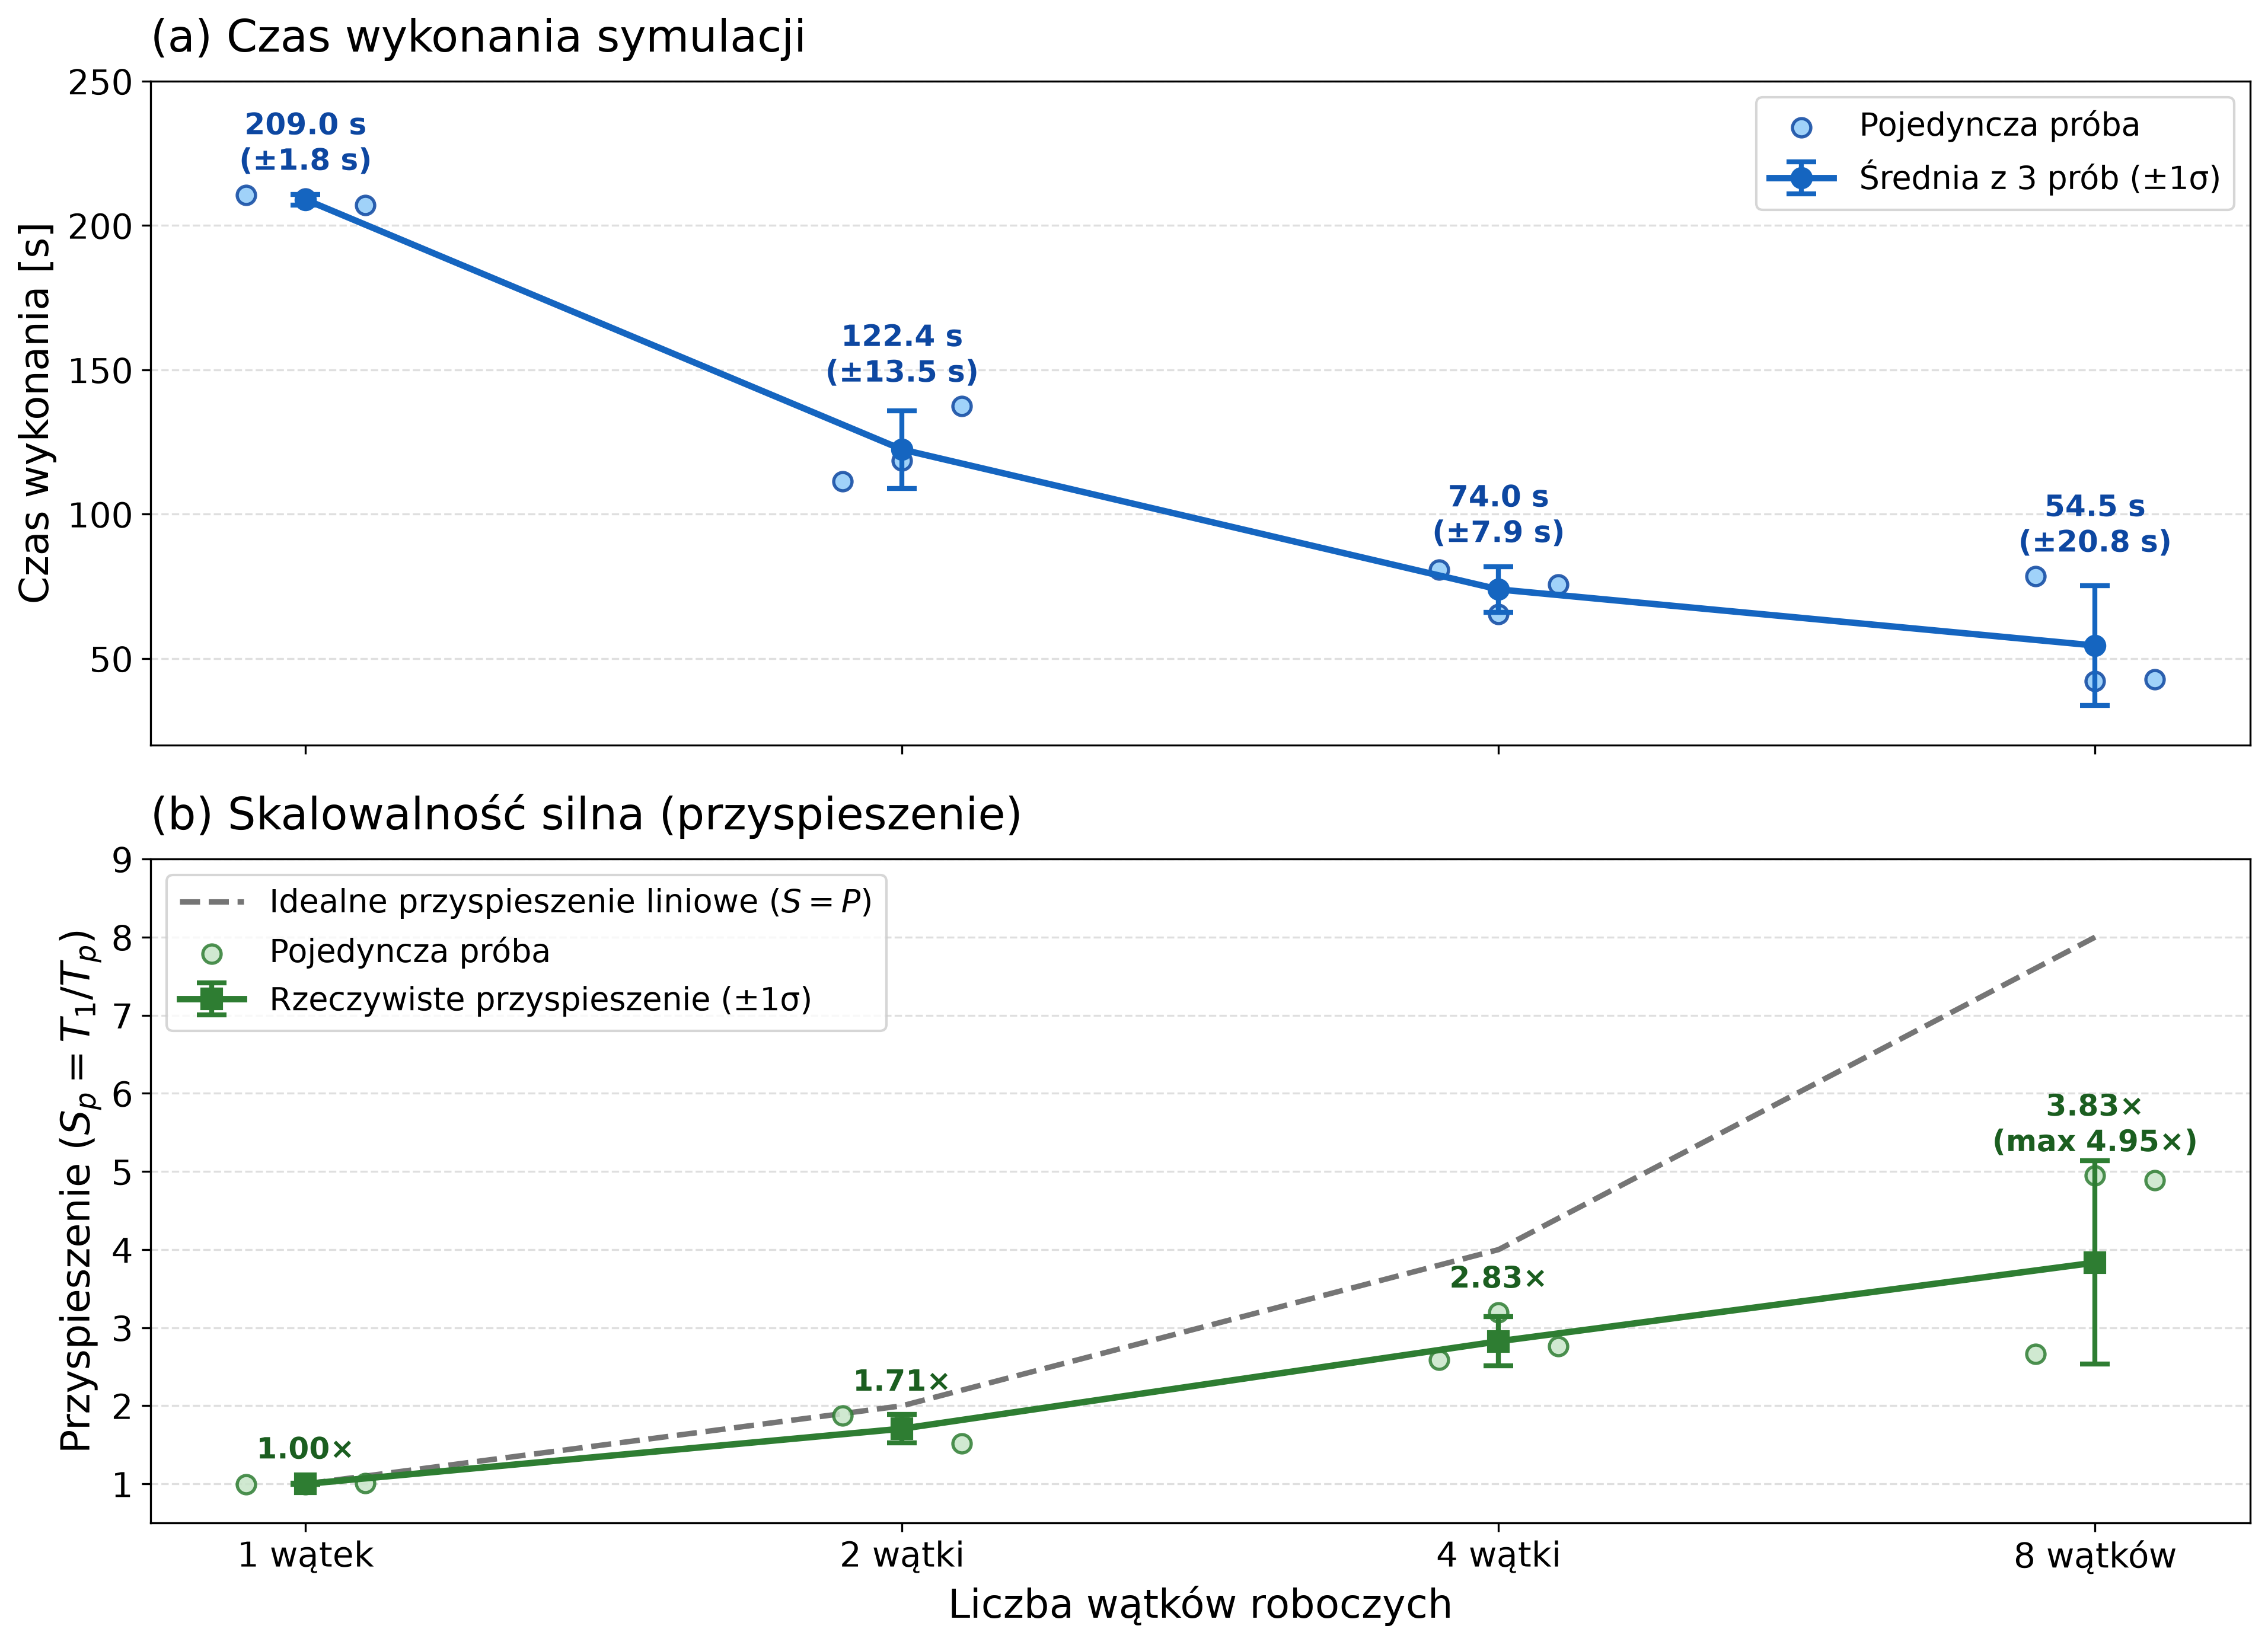

In [56]:
# 1. Konfiguracja stylu spójnego z pracą magisterską
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 15,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 13,
    "figure.dpi": 300,
})

# 2. Dokładne dane z 3 prób pomiarowych na klastrze LEM (100 cykli RF)
workers = [1, 2, 4, 8]
x_pos = np.arange(len(workers))
x_labels = ["1 wątek", "2 wątki", "4 wątki", "8 wątków"]

times_raw = {
    1: [210.53, 209.39, 207.01],  # średnia: 208.98 s (±1.79 s)
    2: [111.31, 118.52, 137.40],  # średnia: 122.41 s (±13.43 s)
    4: [80.80,  65.35,  75.71],  # średnia:  73.95 s (±7.85 s)
    # średnia:  54.52 s (±20.78 s; najlepsze: 42.26 s)
    8: [78.52,  42.26,  42.78],
}

# Średni czas bazowy (1 wątek)
t1_mean = np.mean(times_raw[1])

# Obliczenie średnich i odchyleń czasu
means_time = [np.mean(times_raw[w]) for w in workers]
stds_time = [np.std(times_raw[w], ddof=1) for w in workers]

# Obliczenie przyspieszenia dla każdej próby oraz średniej
speedup_raw = {w: [t1_mean / t for t in times_raw[w]] for w in workers}
means_speedup = [t1_mean / m for m in means_time]
stds_speedup = [np.std(speedup_raw[w], ddof=1) for w in workers]

# Idealne przyspieszenie liniowe S = P
ideal_speedup = [1.0, 2.0, 4.0, 8.0]

# 3. Tworzenie dwupanelowego wykresu
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 9.5), sharex=True)
jitter = np.array([-0.10, 0.0, 0.10])

# ---------------------------------------------------------------------
# Panel (a): Czas wykonania symulacji
# ---------------------------------------------------------------------
for i, w in enumerate(workers):
    vals = times_raw[w]
    ax1.scatter(
        i + jitter, vals,
        color="#90caf9", edgecolors="#0d47a1", s=55, linewidths=1.3,
        alpha=0.85, zorder=4,
        label="Pojedyncza próba" if i == 0 else ""
    )

ax1.errorbar(
    x_pos, means_time, yerr=stds_time,
    fmt="o-", color="#1565c0", linewidth=2.6, markersize=8,
    capsize=6, capthick=2.0, elinewidth=2.0, zorder=5,
    label="Średnia z 3 prób (±1σ)"
)

ax1.set_title("(a) Czas wykonania symulacji", loc="left", pad=12)
ax1.set_ylabel("Czas wykonania [s]")
ax1.set_xticks(x_pos)
ax1.set_xticklabels(x_labels)
ax1.set_ylim(20, 250)
ax1.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
ax1.legend(loc="upper right", frameon=True, edgecolor="#cccccc")

for i, (m, s) in enumerate(zip(means_time, stds_time)):
    top_val = max(m + s, max(times_raw[workers[i]]))
    ax1.annotate(
        f"{m:.1f} s\n(±{s:.1f} s)",
        xy=(i, top_val), xytext=(0, 10),
        textcoords="offset points", ha="center",
        fontsize=12, fontweight="bold", color="#0d47a1", zorder=6
    )

# ---------------------------------------------------------------------
# Panel (b): Przyspieszenie rzeczywiste vs Idealne liniowe
# ---------------------------------------------------------------------
# Linia idealna (referencyjna)
ax2.plot(
    x_pos, ideal_speedup,
    linestyle="--", color="#757575", linewidth=2.2, zorder=2,
    label="Idealne przyspieszenie liniowe ($S = P$)"
)

# Punkty przyspieszenia z pojedynczych prób
for i, w in enumerate(workers):
    s_vals = speedup_raw[w]
    ax2.scatter(
        i + jitter, s_vals,
        color="#c8e6c9", edgecolors="#2e7d32", s=55, linewidths=1.3,
        alpha=0.85, zorder=4,
        label="Pojedyncza próba" if i == 0 else ""
    )

# Krzywa średniego przyspieszenia
ax2.errorbar(
    x_pos, means_speedup, yerr=stds_speedup,
    fmt="s-", color="#2e7d32", linewidth=2.6, markersize=8,
    capsize=6, capthick=2.0, elinewidth=2.0, zorder=5,
    label="Rzeczywiste przyspieszenie (±1σ)"
)

ax2.set_title("(b) Skalowalność silna (przyspieszenie)", loc="left", pad=12)
ax2.set_xlabel("Liczba wątków roboczych")
ax2.set_ylabel("Przyspieszenie ($S_p = T_1 / T_p$)")
ax2.set_xticks(x_pos)
ax2.set_xticklabels(x_labels)
ax2.set_ylim(0.5, 9.0)
ax2.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
ax2.legend(loc="upper left", frameon=True, edgecolor="#cccccc")

# Adnotacje z wartościami przyspieszenia nad punktami
for i, (m_s, w) in enumerate(zip(means_speedup, workers)):
    max_s = max(speedup_raw[w])
    text = f"{m_s:.2f}×" if w != 8 else f"{m_s:.2f}×\n(max {max_s:.2f}×)"
    ax2.annotate(
        text,
        xy=(i, max(m_s, max_s)), xytext=(0, 10),
        textcoords="offset points", ha="center",
        fontsize=12, fontweight="bold", color="#1b5e20", zorder=6
    )

plt.tight_layout()

# 4. Zapis do pliku
plt.savefig("go_barrier_skalowanie.pdf", bbox_inches="tight")

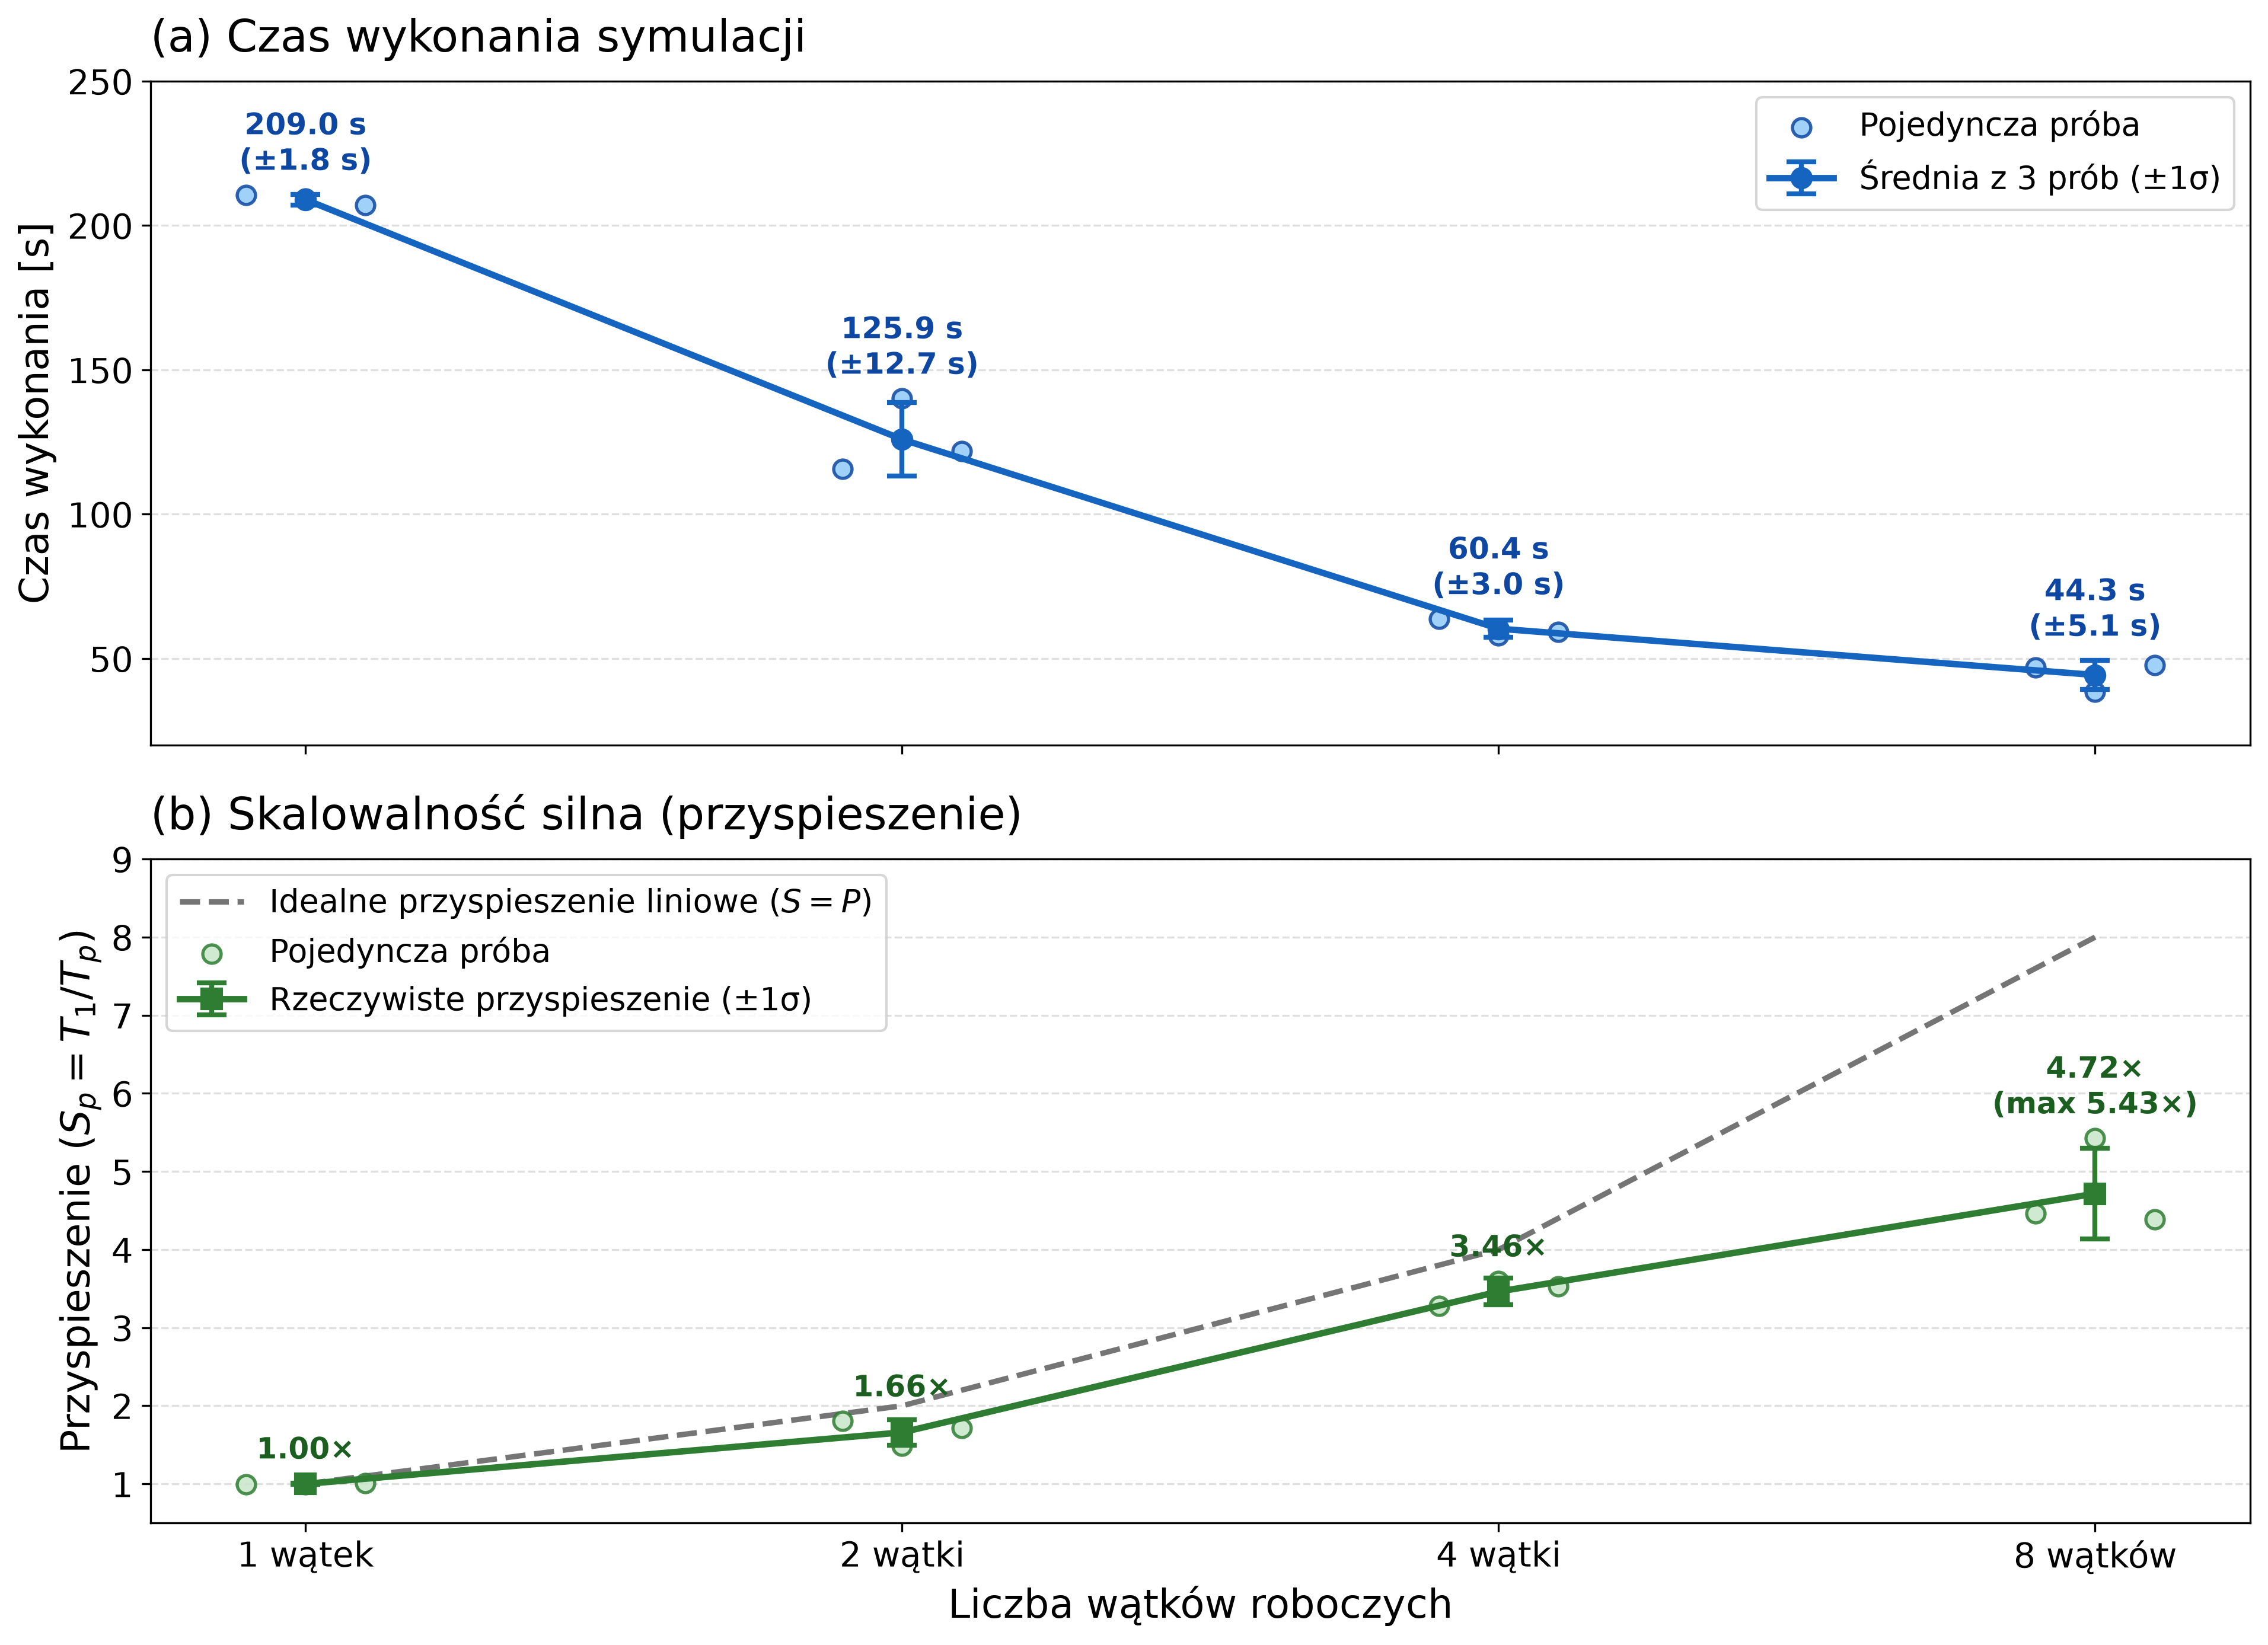

In [60]:
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 15,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 13,
    "figure.dpi": 300,
})

workers = [1, 2, 4, 8]
x_pos = np.arange(len(workers))
x_labels = ["1 wątek", "2 wątki", "4 wątki", "8 wątków"]

# Dokładne dane z 3 prób na klastrze LEM (100 cykli RF, Krok 4: Fused Boundaries)
times_raw = {
    1: [210.53, 209.39, 207.01],  # średnia: 208.98 s (±1.79 s)
    2: [115.70, 140.13, 121.94],  # średnia: 125.92 s (±12.69 s)
    4: [63.78,  58.07,  59.20],  # średnia:  60.35 s (±3.02 s)
    # średnia:  44.32 s (±5.07 s; najlepsza: 38.49 s)
    8: [46.82,  38.49,  47.63],
}

t1_mean = np.mean(times_raw[1])
means_time = [np.mean(times_raw[w]) for w in workers]
stds_time = [np.std(times_raw[w], ddof=1) for w in workers]

speedup_raw = {w: [t1_mean / t for t in times_raw[w]] for w in workers}
means_speedup = [t1_mean / m for m in means_time]
stds_speedup = [np.std(speedup_raw[w], ddof=1) for w in workers]
ideal_speedup = [1.0, 2.0, 4.0, 8.0]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 9.5), sharex=True)
jitter = np.array([-0.10, 0.0, 0.10])

# Panel (a): Czas wykonania
for i, w in enumerate(workers):
    vals = times_raw[w]
    ax1.scatter(
        i + jitter, vals,
        color="#90caf9", edgecolors="#0d47a1", s=55, linewidths=1.3,
        alpha=0.85, zorder=4,
        label="Pojedyncza próba" if i == 0 else ""
    )

ax1.errorbar(
    x_pos, means_time, yerr=stds_time,
    fmt="o-", color="#1565c0", linewidth=2.6, markersize=8,
    capsize=6, capthick=2.0, elinewidth=2.0, zorder=5,
    label="Średnia z 3 prób (±1σ)"
)
ax1.set_title("(a) Czas wykonania symulacji", loc="left", pad=12)
ax1.set_ylabel("Czas wykonania [s]")
ax1.set_xticks(x_pos)
ax1.set_xticklabels(x_labels)
ax1.set_ylim(20, 250)
ax1.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
ax1.legend(loc="upper right", frameon=True, edgecolor="#cccccc")

for i, (m, s) in enumerate(zip(means_time, stds_time)):
    top_val = max(m + s, max(times_raw[workers[i]]))
    ax1.annotate(
        f"{m:.1f} s\n(±{s:.1f} s)",
        xy=(i, top_val), xytext=(0, 10),
        textcoords="offset points", ha="center",
        fontsize=12, fontweight="bold", color="#0d47a1", zorder=6
    )

# Panel (b): Przyspieszenie
ax2.plot(
    x_pos, ideal_speedup,
    linestyle="--", color="#757575", linewidth=2.2, zorder=2,
    label="Idealne przyspieszenie liniowe ($S = P$)"
)

for i, w in enumerate(workers):
    s_vals = speedup_raw[w]
    ax2.scatter(
        i + jitter, s_vals,
        color="#c8e6c9", edgecolors="#2e7d32", s=55, linewidths=1.3,
        alpha=0.85, zorder=4,
        label="Pojedyncza próba" if i == 0 else ""
    )

ax2.errorbar(
    x_pos, means_speedup, yerr=stds_speedup,
    fmt="s-", color="#2e7d32", linewidth=2.6, markersize=8,
    capsize=6, capthick=2.0, elinewidth=2.0, zorder=5,
    label="Rzeczywiste przyspieszenie (±1σ)"
)
ax2.set_title("(b) Skalowalność silna (przyspieszenie)", loc="left", pad=12)
ax2.set_xlabel("Liczba wątków roboczych")
ax2.set_ylabel("Przyspieszenie ($S_p = T_1 / T_p$)")
ax2.set_xticks(x_pos)
ax2.set_xticklabels(x_labels)
ax2.set_ylim(0.5, 9.0)
ax2.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
ax2.legend(loc="upper left", frameon=True, edgecolor="#cccccc")

for i, (m_s, w) in enumerate(zip(means_speedup, workers)):
    max_s = max(speedup_raw[w])
    text = f"{m_s:.2f}×" if w != 8 else f"{m_s:.2f}×\n(max {max_s:.2f}×)"
    ax2.annotate(
        text,
        xy=(i, max(m_s, max_s)), xytext=(0, 10),
        textcoords="offset points", ha="center",
        fontsize=12, fontweight="bold", color="#1b5e20", zorder=6
    )

plt.tight_layout()

plt.savefig("go_fused_skalowanie.pdf", bbox_inches="tight")

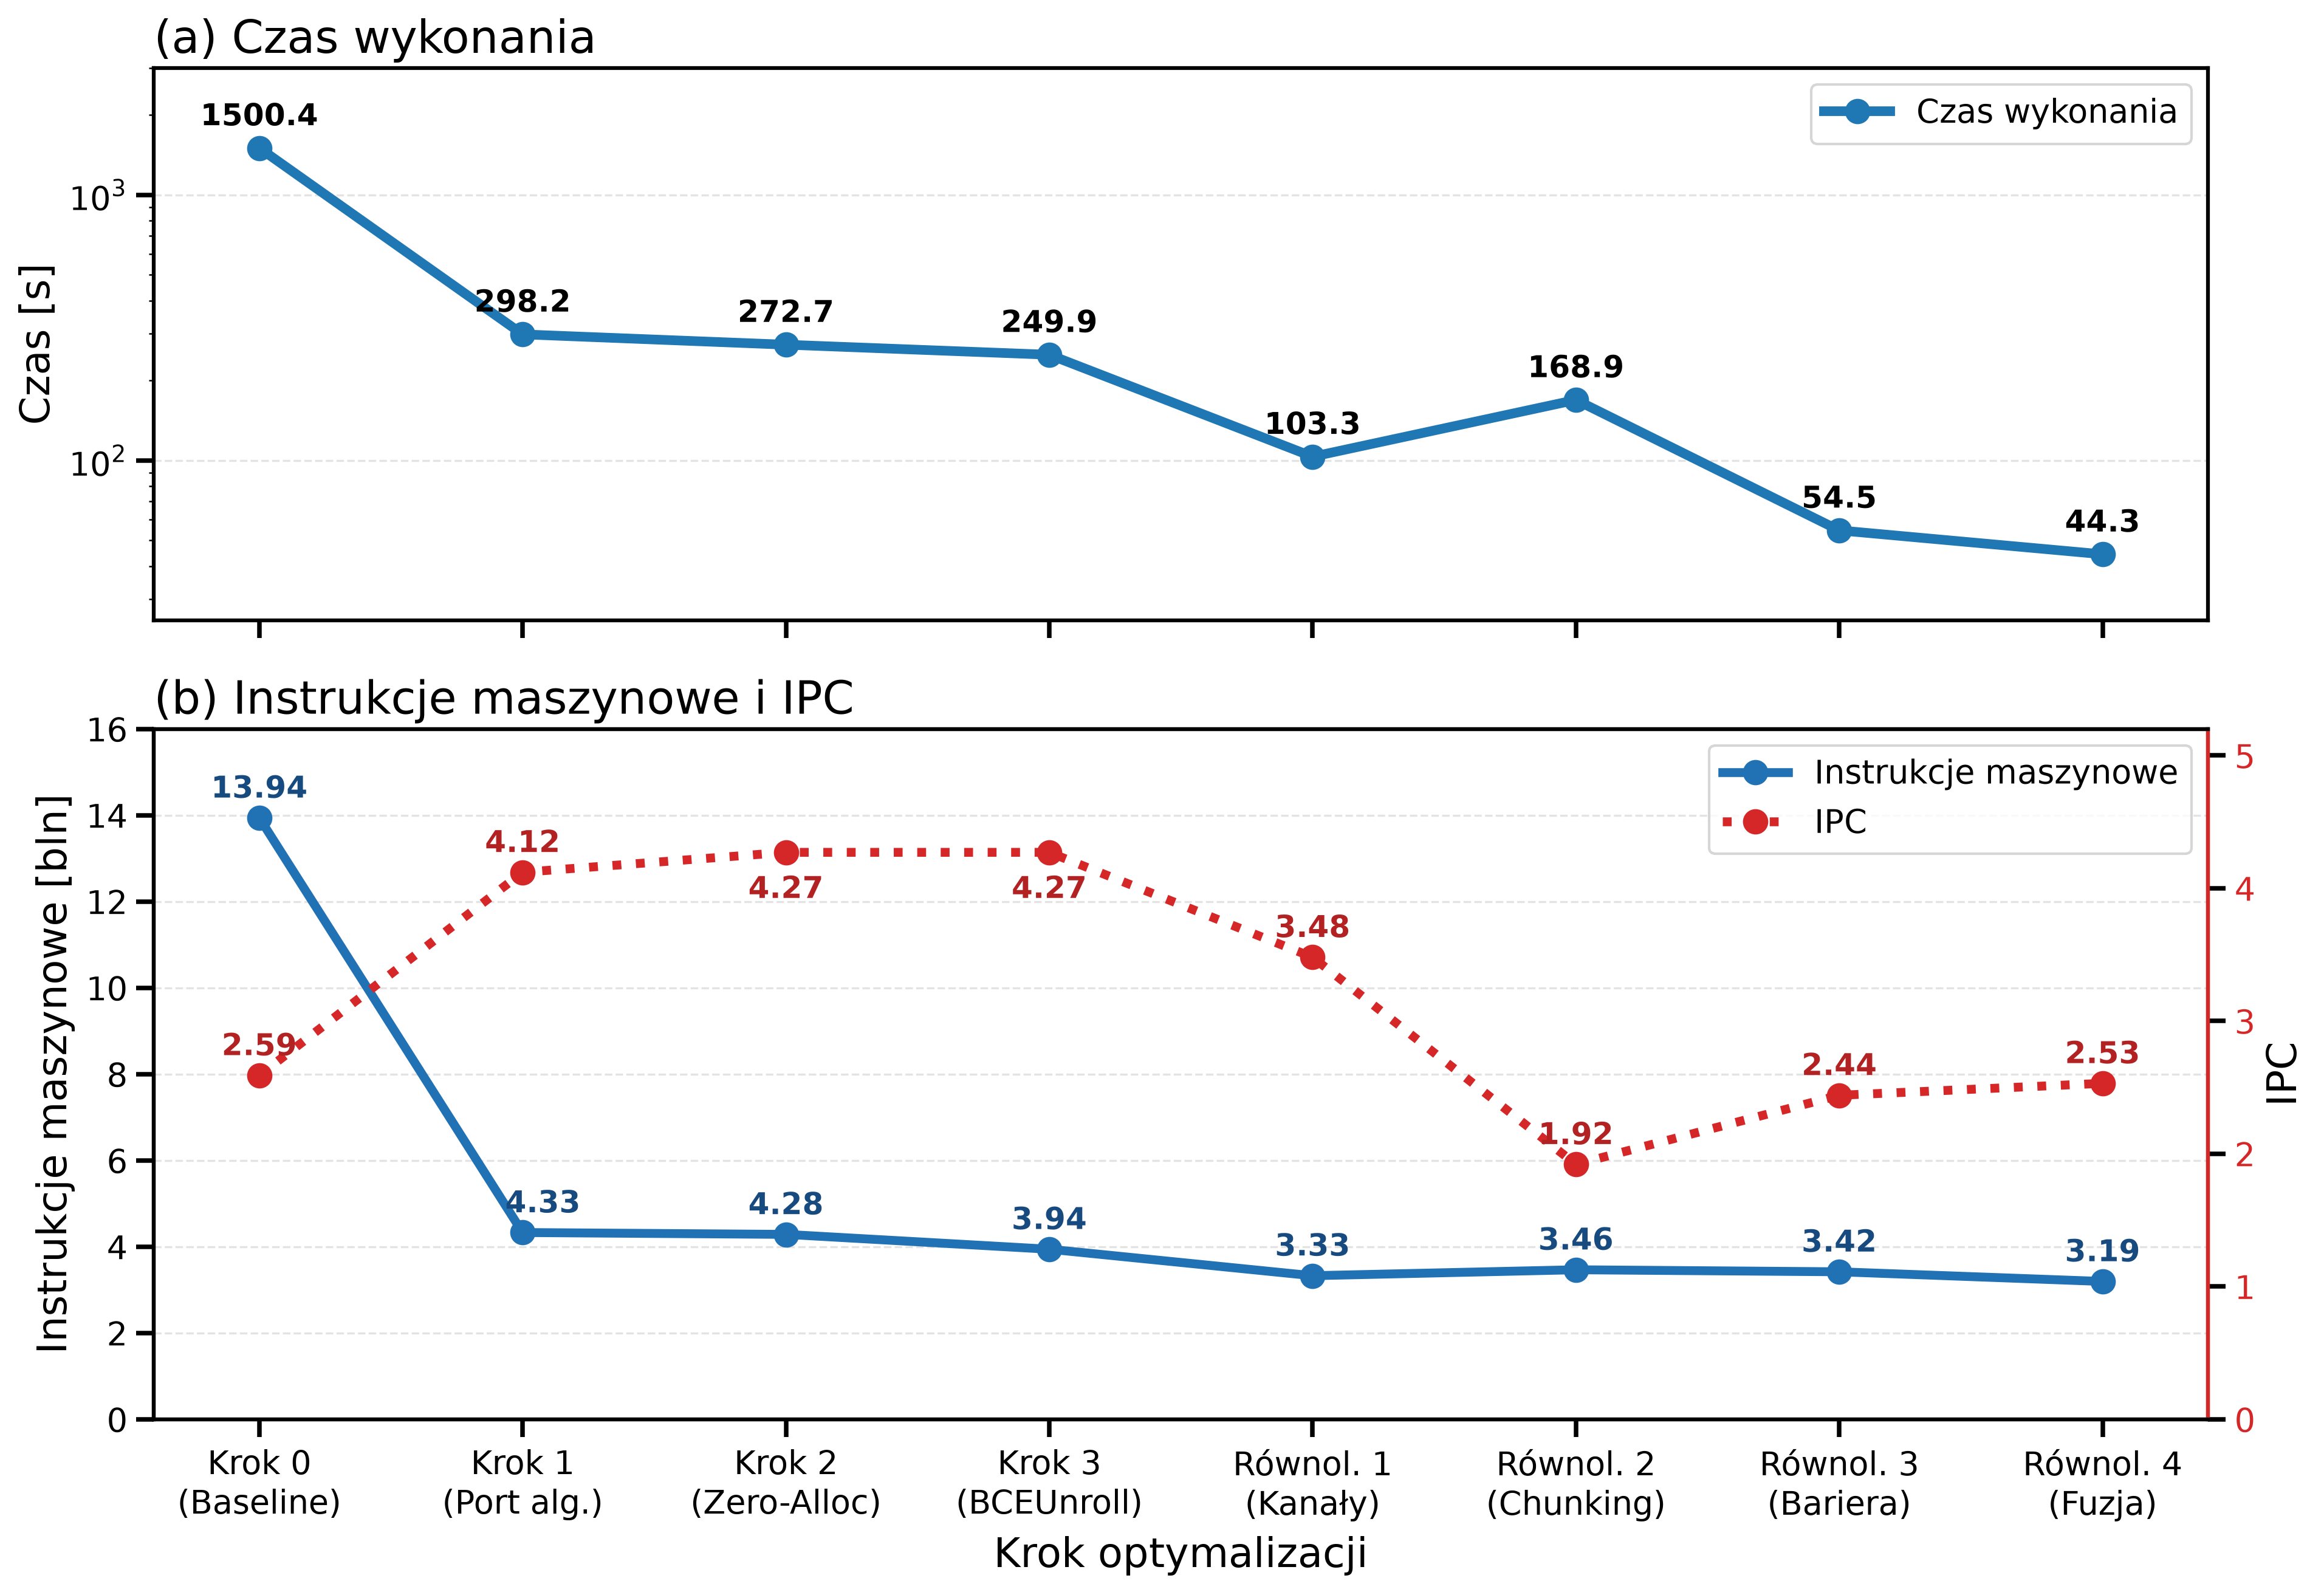

In [62]:
# Etykiety kolejnych kroków optymalizacji Go
labels = [
    "Krok 0\n(Baseline)",
    "Krok 1\n(Port alg.)",
    "Krok 2\n(Zero-Alloc)",
    "Krok 3\n(BCEUnroll)",
    "Równol. 1\n(Kanały)",
    "Równol. 2\n(Chunking)",
    "Równol. 3\n(Bariera)",
    "Równol. 4\n(Fuzja)",
]

# Średnie wyniki z 3 powtórzeń na klastrze LEM (100 cykli RF)
# Kroki 0-3: 1 rdzeń; Równol. 1-4: 8 rdzeni
time_s = [1500.39, 298.25, 272.69, 249.95, 103.29, 168.93, 54.52, 44.32]
instructions_bln = [13.939, 4.327, 4.284, 3.940, 3.326, 3.464, 3.417, 3.193]
ipc = [2.59, 4.12, 4.27, 4.27, 3.48, 1.92, 2.44, 2.53]

# Pozycje na osi X
x = np.arange(len(labels))

plt.rcParams.update({
    "font.size": 15,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 13,
    "ytick.labelsize": 14,
    "legend.fontsize": 13,
    "figure.dpi": 300,
})

fig, (ax_time, ax_perf) = plt.subplots(
    2,
    1,
    figsize=(13, 9),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 1.25]},
)

# ---------------------------------------------------------------------
# Panel (a): czas wykonania (skala logarytmiczna)
# ---------------------------------------------------------------------
ax_time.plot(
    x,
    time_s,
    color="#1f77b4",
    marker="o",
    markersize=9,
    linewidth=3.8,
    label="Czas wykonania",
)

ax_time.set_yscale("log")
ax_time.set_title("(a) Czas wykonania", loc="left")
ax_time.set_ylabel("Czas [s]")
ax_time.set_ylim(25, 3000)
ax_time.set_xlim(-0.4, len(x) - 0.6)
ax_time.grid(axis="y", linestyle="--", alpha=0.35)
ax_time.legend(loc="upper right")

# Etykiety wartości nad punktami czasu
for i, value in enumerate(time_s):
    # Drobne przesunięcie dla czytelności bliskich punktów
    offset_y = 9
    ax_time.annotate(
        f"{value:.1f}",
        xy=(i, value),
        xytext=(0, offset_y),
        textcoords="offset points",
        ha="center",
        fontsize=12,
        fontweight="bold",
    )

# ---------------------------------------------------------------------
# Panel (b): instrukcje i IPC — dwie osie Y
# ---------------------------------------------------------------------
ax_perf.plot(
    x,
    instructions_bln,
    color="#2171b5",
    marker="o",
    markersize=9,
    linewidth=3.5,
    label="Instrukcje maszynowe",
)

ax_perf.set_title(
    "(b) Instrukcje maszynowe i IPC",
    loc="left",
)
ax_perf.set_ylabel("Instrukcje maszynowe [bln]")
ax_perf.set_ylim(0, 16)
ax_perf.grid(axis="y", linestyle="--", alpha=0.35)

# Etykiety liczby instrukcji
for i, value in enumerate(instructions_bln):
    offset_x = 8 if i==1 else 0
    ax_perf.annotate(
        f"{value:.2f}",
        xy=(i, value),
        xytext=(offset_x, 8),
        textcoords="offset points",
        ha="center",
        fontsize=12,
        fontweight="bold",
        color="#174a7e",
    )

# Druga oś Y: IPC
ax_ipc = ax_perf.twinx()

ipc_line = ax_ipc.plot(
    x,
    ipc,
    color="#d62728",
    marker="o",
    linestyle=":",
    linewidth=3.5,
    markersize=9,
    label="IPC",
)

ax_ipc.set_ylabel("IPC")
ax_ipc.set_ylim(0, 5.2)
ax_ipc.tick_params(axis="y", labelcolor="#d62728")
ax_ipc.spines["right"].set_color("#d62728")

# Etykiety IPC
for i, value in enumerate(ipc):
    # Rozsunięcie dla nakładających się wartości 4.27
    offset_y = -18 if i in [2, 3] else 8
    ax_ipc.annotate(
        f"{value:.2f}",
        xy=(i, value),
        xytext=(0, offset_y),
        textcoords="offset points",
        ha="center",
        color="#b22222",
        fontsize=12,
        fontweight="bold",
    )

# Wspólna legenda dla obu osi
handles_left, labels_left = ax_perf.get_legend_handles_labels()
handles_right, labels_right = ax_ipc.get_legend_handles_labels()

ax_perf.legend(
    handles_left + handles_right,
    labels_left + labels_right,
    loc="upper right",
)

# Konfiguracja osi X
ax_perf.set_xticks(x)
ax_perf.set_xticklabels(labels)
ax_perf.set_xlabel("Krok optymalizacji")

for ax in (ax_time, ax_perf, ax_ipc):
    ax.tick_params(
        axis="both",
        which="major",
        labelsize=13,
        width=1.8,
        length=7,
    )
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)

plt.tight_layout()

# Zapis do pliku
plt.savefig(
    "wykresy_optymalizacji_go.pdf",
    bbox_inches="tight",
)
plt.show()

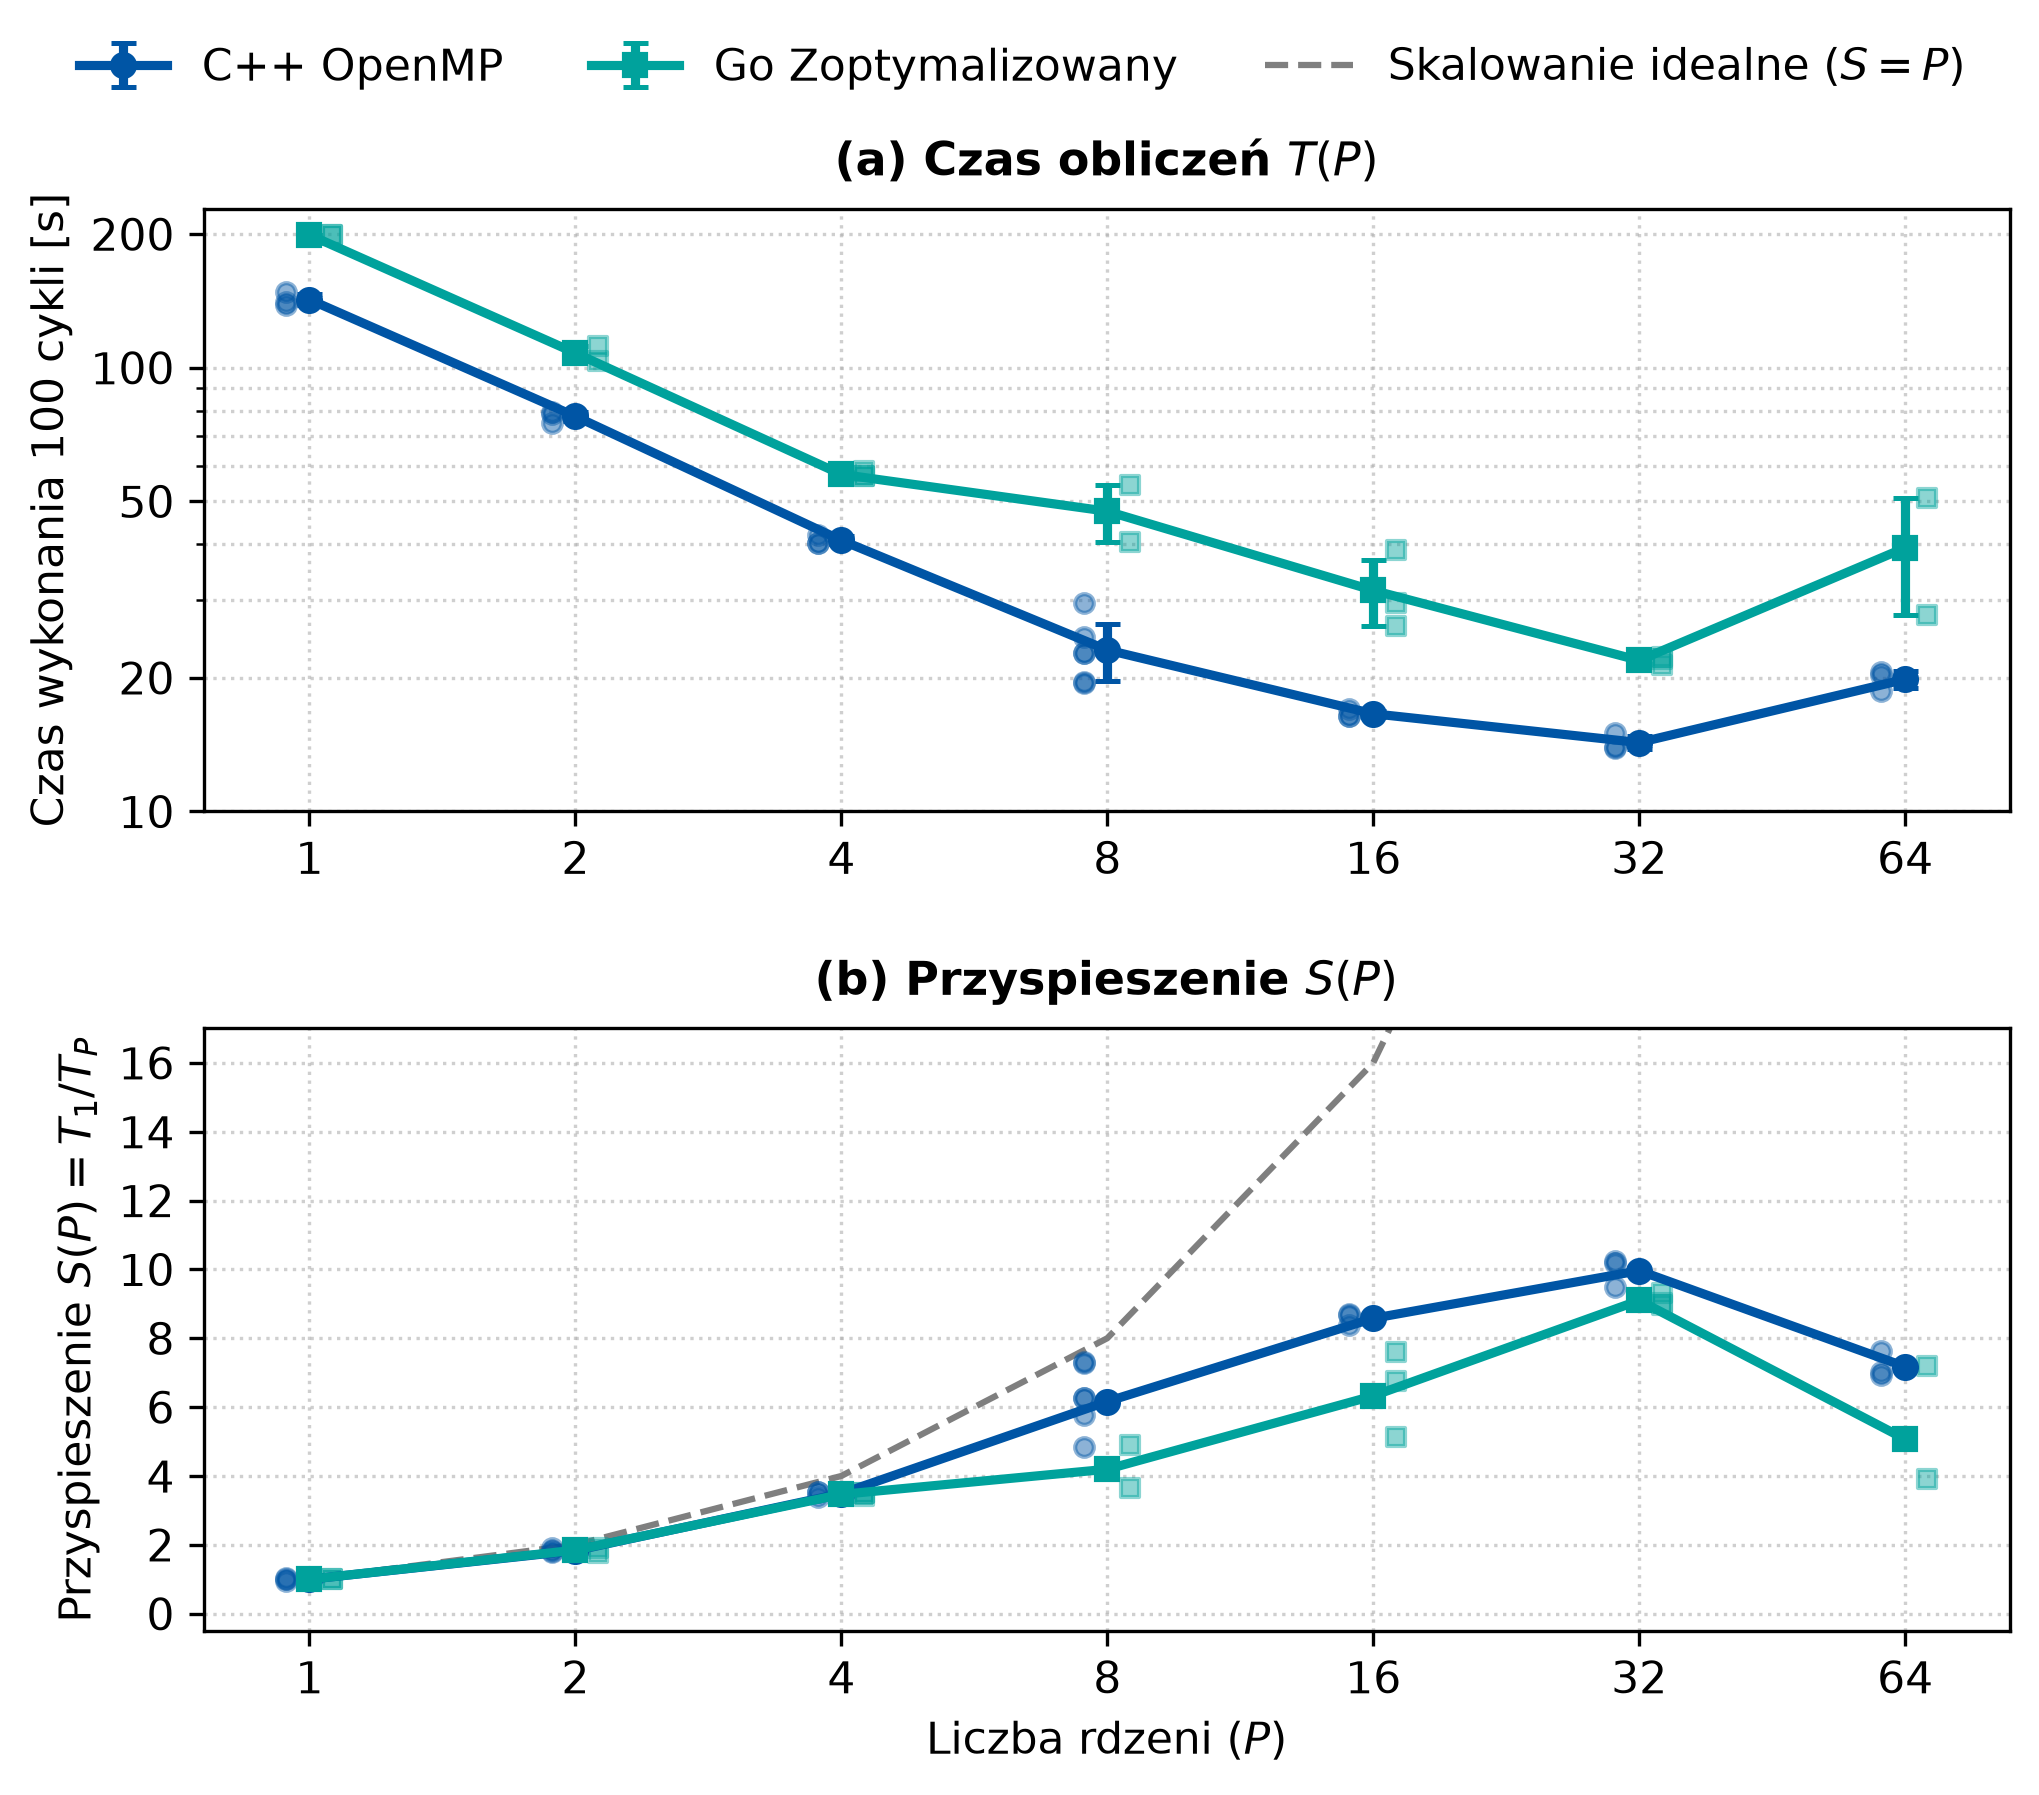

In [3]:
# Surowe dane pomiarowe
raw_cpp = {
    1: [148.242550, 138.366905, 140.648532],
    2: [79.314452, 78.674139, 75.109662],
    4: [41.997398, 40.274840, 40.225000],
    8: [29.477219, 22.741961, 22.712245, 19.584676, 24.695876, 19.461511],
    16: [16.432051, 16.989636, 16.383463],
    32: [13.991928, 13.893360, 15.000015],
    64: [20.312063, 20.570837, 18.670708]
}

raw_go = {
    1: [199.450763, 198.952538],
    2: [103.646939, 112.144675],
    4: [56.980720, 56.984568, 58.515695],
    8: [54.399739, 40.553823],
    16: [38.745998, 26.240619, 29.485975],
    32: [22.253009, 21.374696, 22.053681],
    64: [27.655619, 50.918166]
}

cores = np.array([1, 2, 4, 8, 16, 32, 64])

mean_cpp = np.array([np.mean(raw_cpp[p]) for p in cores])
std_cpp = np.array([np.std(raw_cpp[p]) for p in cores])
speedup_cpp = mean_cpp[0] / mean_cpp

mean_go = np.array([np.mean(raw_go[p]) for p in cores])
std_go = np.array([np.std(raw_go[p]) for p in cores])
speedup_go = mean_go[0] / mean_go

# 2. BUDOWA WYKRESU (UKŁAD PIONOWY 2x1)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 300

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 6))
# top=0.88 daje swobodną przestrzeń na legendę, hspace=0.36 rozsuwa panele
plt.subplots_adjust(left=0.11, right=0.97, bottom=0.09, top=0.88, hspace=0.36)

col_cpp = '#0055A5'  # Klasyczny niebieski
col_go = '#00A29C'  # Morski / turkus
col_ideal = '#7F7F7F'  # Szary

# --- PANEL (a): Czas obliczeń T(P) ---
for p in cores:
    # Surowe próby w tle (półprzezroczyste punkty)
    ax1.scatter([p * 0.94] * len(raw_cpp[p]), raw_cpp[p],
                color=col_cpp, alpha=0.45, s=20, zorder=3)
    ax1.scatter([p * 1.06] * len(raw_go[p]), raw_go[p],
                color=col_go, alpha=0.45, s=20, marker='s', zorder=3)

# Linie średnich z wąsami (+/- sigma)
line_cpp = ax1.errorbar(cores, mean_cpp, yerr=std_cpp, fmt='o-', color=col_cpp, lw=2.2, ms=5.5,
                        capsize=3, capthick=1.2, label='C++ OpenMP', zorder=4)
line_go = ax1.errorbar(cores, mean_go, yerr=std_go, fmt='s-', color=col_go, lw=2.2, ms=5.5,
                       capsize=3, capthick=1.2, label='Go Zoptymalizowany', zorder=4)

ax1.set_xscale('log', base=2)
ax1.set_yscale('log', base=10)
ax1.set_xticks(cores)
ax1.set_xticklabels([str(p) for p in cores], fontsize=10.5)

# Czyste etykiety osi Y – wyłączamy minor ticks, wymuszamy jawne liczby (brak 6x10^1)
ax1.yaxis.set_minor_formatter(ticker.NullFormatter())
ax1.set_yticks([10, 20, 50, 100, 200])
ax1.set_yticklabels(['10', '20', '50', '100', '200'], fontsize=10.5)

ax1.set_ylabel('Czas wykonania 100 cykli [s]', fontsize=10.5)
ax1.set_title(r'(a) Czas obliczeń $T(P)$',
              fontsize=11, fontweight='bold', pad=8)
ax1.grid(True, which='both', linestyle=':', alpha=0.6)


# --- PANEL (b): Przyspieszenie S(P) ---
for p in cores:
    s_raw_cpp = [mean_cpp[0] / t for t in raw_cpp[p]]
    s_raw_go = [mean_go[0] / t for t in raw_go[p]]
    ax2.scatter([p * 0.94] * len(s_raw_cpp), s_raw_cpp,
                color=col_cpp, alpha=0.45, s=20, zorder=3)
    ax2.scatter([p * 1.06] * len(s_raw_go), s_raw_go,
                color=col_go, alpha=0.45, s=20, marker='s', zorder=3)

# Linia idealnego skalowania S = P
line_ideal = ax2.plot(cores, cores, '--', color=col_ideal,
                      lw=1.5, label=r'Skalowanie idealne ($S=P$)')

# Linie średniego przyspieszenia
ax2.plot(cores, speedup_cpp, 'o-', color=col_cpp, lw=2.2,
         ms=5.5, label='C++ OpenMP', zorder=4)
ax2.plot(cores, speedup_go, 's-', color=col_go, lw=2.2,
         ms=5.5, label='Go Zoptymalizowany', zorder=4)

ax2.set_xscale('log', base=2)
ax2.set_xticks(cores)
ax2.set_xticklabels([str(p) for p in cores], fontsize=10.5)
ax2.set_yticks(range(0, 18, 2))
ax2.set_yticklabels(range(0, 18, 2), fontsize=10.5)
ax2.set_ylim(-0.5, 17)

ax2.set_xlabel(r'Liczba rdzeni ($P$)', fontsize=10.5)
ax2.set_ylabel(r'Przyspieszenie $S(P) = T_1 / T_P$', fontsize=10.5)
ax2.set_title(r'(b) Przyspieszenie $S(P)$',
              fontsize=11, fontweight='bold', pad=8)
ax2.grid(True, which='both', linestyle=':', alpha=0.6)


# --- WSPÓLNA LEGENDA NA GÓRZE ---
fig.legend([line_cpp, line_go, line_ideal[0]],
           ['C++ OpenMP', 'Go Zoptymalizowany', r'Skalowanie idealne ($S=P$)'],
           loc='upper center', bbox_to_anchor=(0.50, 0.992), ncol=3,
           fontsize=10.5, frameon=False, edgecolor='#CCCCCC')

# Zapis do pliku PDF
plt.savefig('skalowanie_silne.pdf', format='pdf')
plt.show()

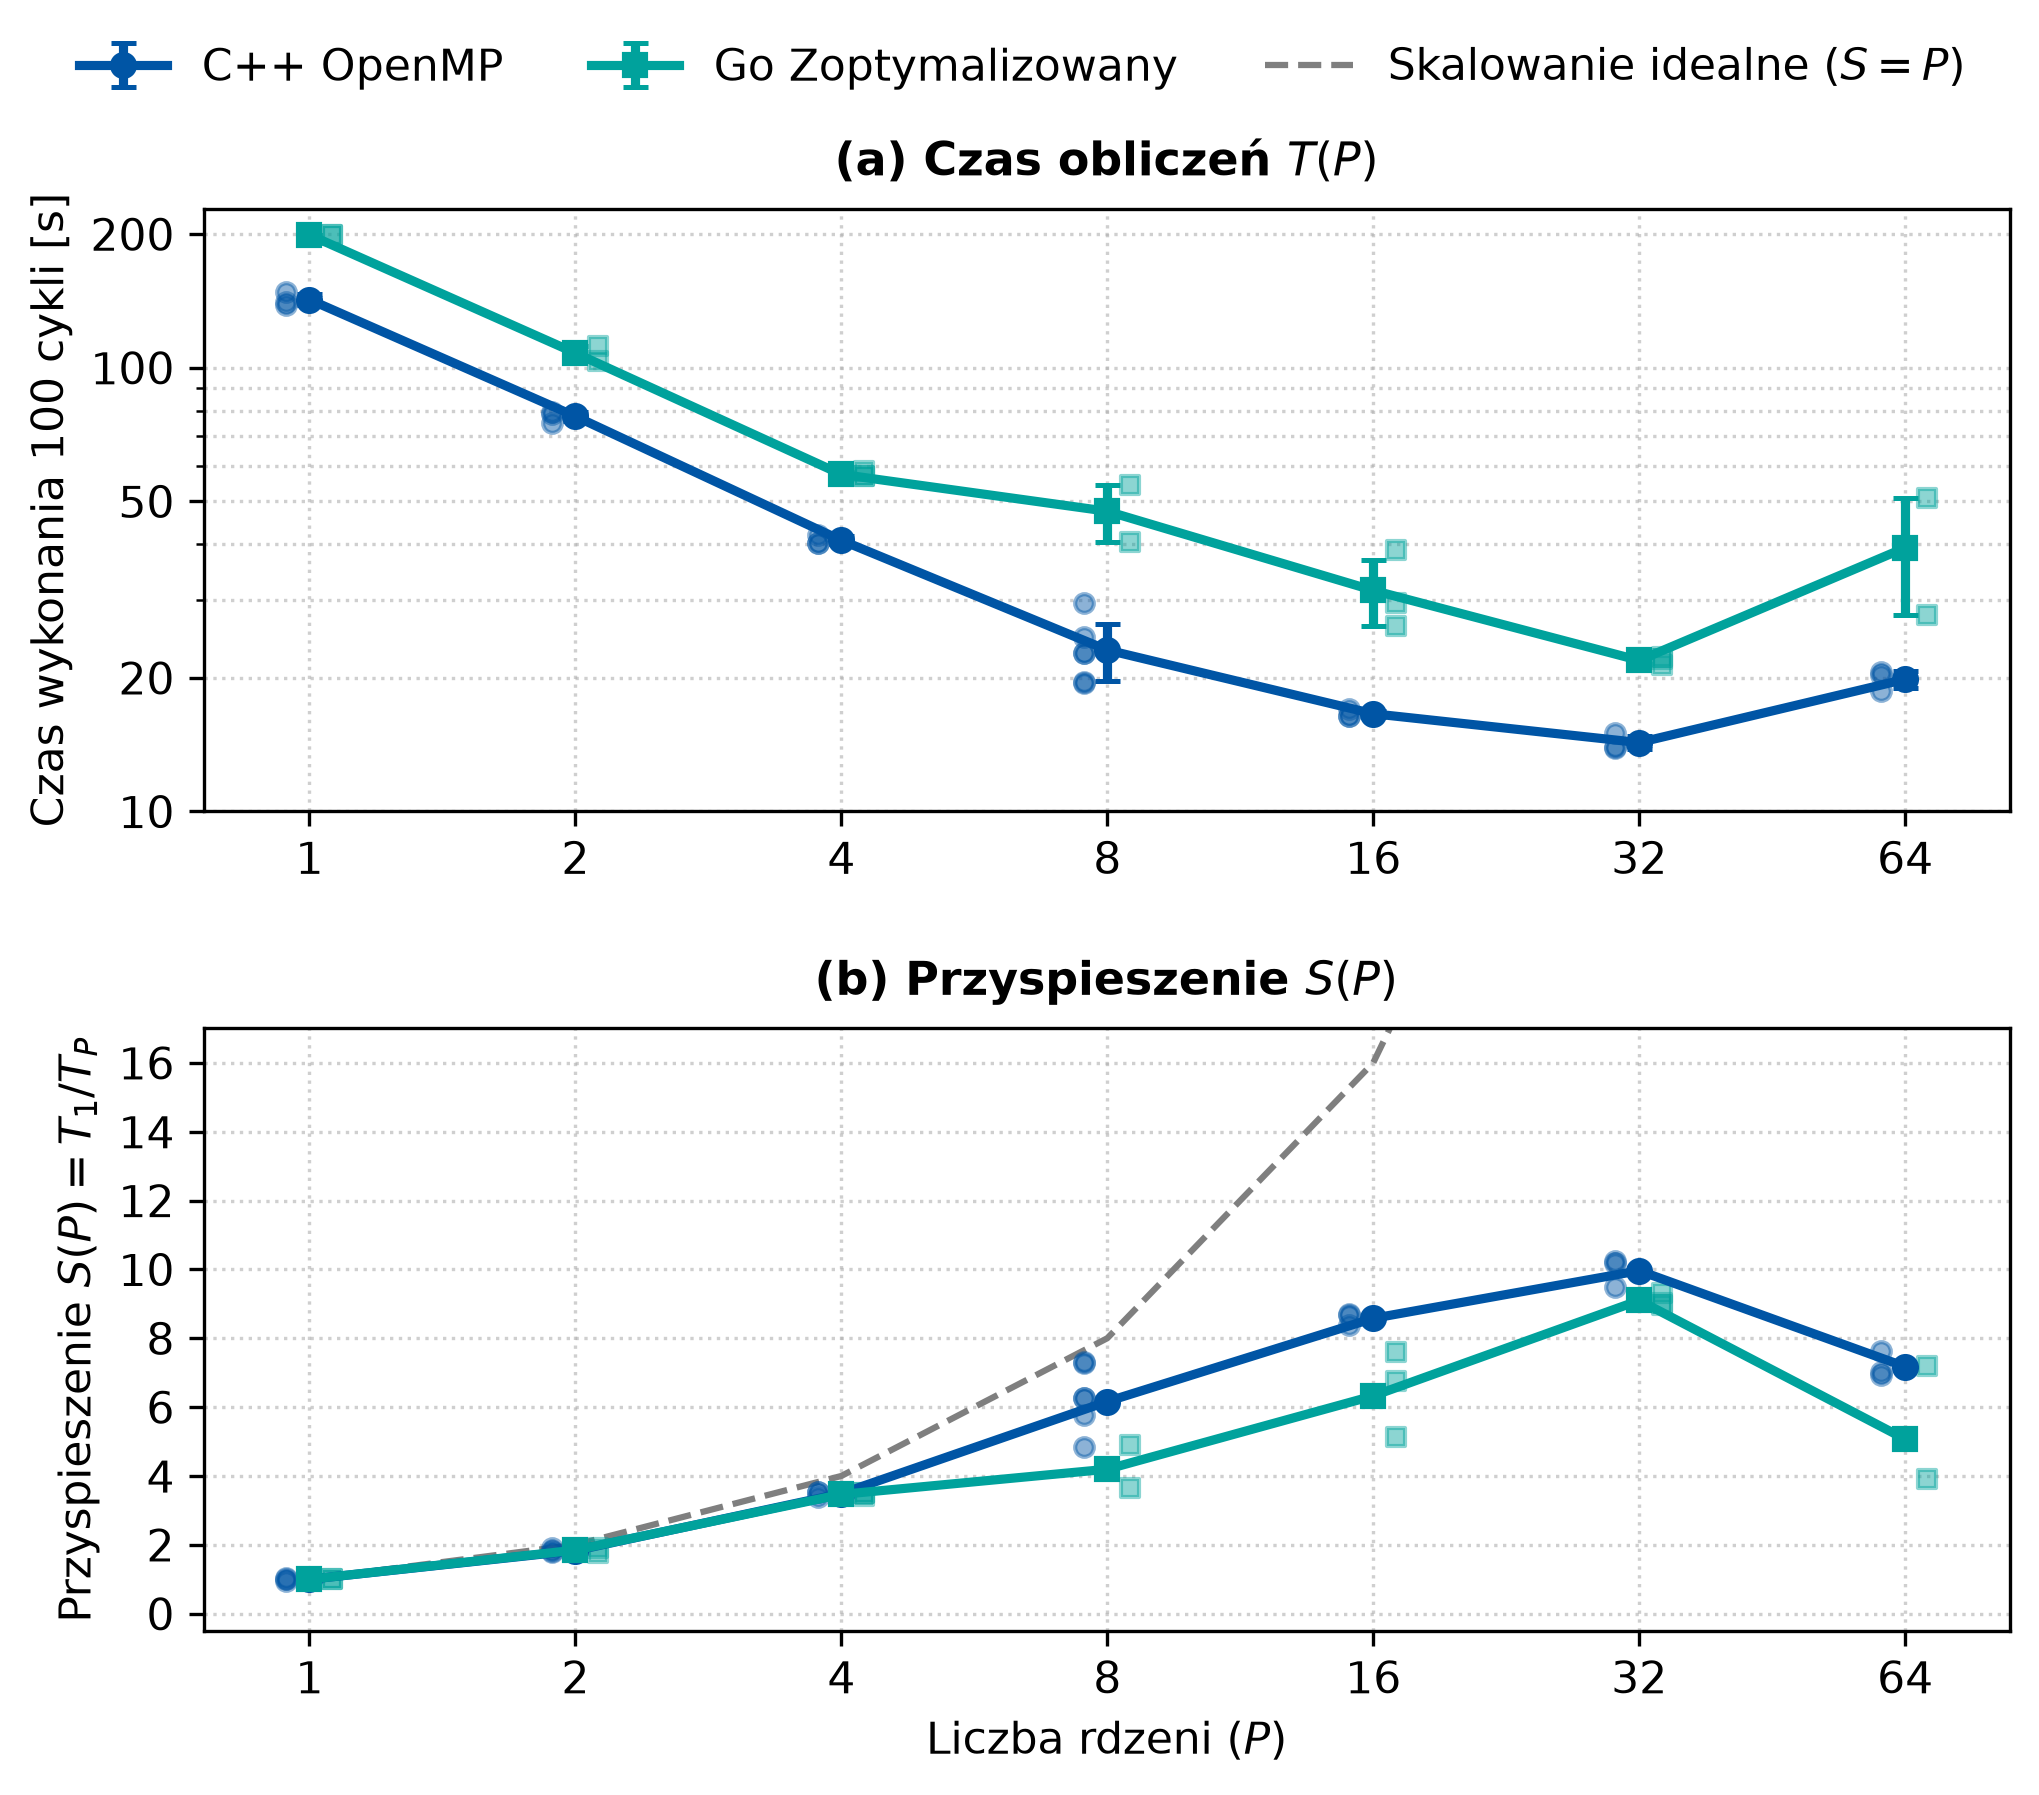

In [4]:
# Surowe dane pomiarowe
raw_cpp = {
    1: [148.242550, 138.366905, 140.648532],
    2: [79.314452, 78.674139, 75.109662],
    4: [41.997398, 40.274840, 40.225000],
    8: [29.477219, 22.741961, 22.712245, 19.584676, 24.695876, 19.461511],
    16: [16.432051, 16.989636, 16.383463],
    32: [13.991928, 13.893360, 15.000015],
    64: [20.312063, 20.570837, 18.670708]
}

raw_go = {
    1: [199.450763, 198.952538],
    2: [103.646939, 112.144675],
    4: [56.980720, 56.984568, 58.515695],
    8: [54.399739, 40.553823],
    16: [38.745998, 26.240619, 29.485975],
    32: [22.253009, 21.374696, 22.053681],
    64: [27.655619, 50.918166]
}

cores = np.array([1, 2, 4, 8, 16, 32, 64])

mean_cpp = np.array([np.mean(raw_cpp[p]) for p in cores])
std_cpp = np.array([np.std(raw_cpp[p]) for p in cores])
speedup_cpp = mean_cpp[0] / mean_cpp

mean_go = np.array([np.mean(raw_go[p]) for p in cores])
std_go = np.array([np.std(raw_go[p]) for p in cores])
speedup_go = mean_go[0] / mean_go

# 2. BUDOWA WYKRESU (UKŁAD PIONOWY 2x1)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 300

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 6))
# top=0.88 daje swobodną przestrzeń na legendę, hspace=0.36 rozsuwa panele
plt.subplots_adjust(left=0.11, right=0.97, bottom=0.09, top=0.88, hspace=0.36)

col_cpp = '#0055A5'  # Klasyczny niebieski
col_go = '#00A29C'  # Morski / turkus
col_ideal = '#7F7F7F'  # Szary

# --- PANEL (a): Czas obliczeń T(P) ---
for p in cores:
    # Surowe próby w tle (półprzezroczyste punkty)
    ax1.scatter([p * 0.94] * len(raw_cpp[p]), raw_cpp[p],
                color=col_cpp, alpha=0.45, s=20, zorder=3)
    ax1.scatter([p * 1.06] * len(raw_go[p]), raw_go[p],
                color=col_go, alpha=0.45, s=20, marker='s', zorder=3)

# Linie średnich z wąsami (+/- sigma)
line_cpp = ax1.errorbar(cores, mean_cpp, yerr=std_cpp, fmt='o-', color=col_cpp, lw=2.2, ms=5.5,
                        capsize=3, capthick=1.2, label='C++ OpenMP', zorder=4)
line_go = ax1.errorbar(cores, mean_go, yerr=std_go, fmt='s-', color=col_go, lw=2.2, ms=5.5,
                       capsize=3, capthick=1.2, label='Go Zoptymalizowany', zorder=4)

ax1.set_xscale('log', base=2)
ax1.set_yscale('log', base=10)
ax1.set_xticks(cores)
ax1.set_xticklabels([str(p) for p in cores], fontsize=10.5)

# Czyste etykiety osi Y – wyłączamy minor ticks, wymuszamy jawne liczby (brak 6x10^1)
ax1.yaxis.set_minor_formatter(ticker.NullFormatter())
ax1.set_yticks([10, 20, 50, 100, 200])
ax1.set_yticklabels(['10', '20', '50', '100', '200'], fontsize=10.5)

ax1.set_ylabel('Czas wykonania 100 cykli [s]', fontsize=10.5)
ax1.set_title(r'(a) Czas obliczeń $T(P)$',
              fontsize=11, fontweight='bold', pad=8)
ax1.grid(True, which='both', linestyle=':', alpha=0.6)


# --- PANEL (b): Przyspieszenie S(P) ---
for p in cores:
    s_raw_cpp = [mean_cpp[0] / t for t in raw_cpp[p]]
    s_raw_go = [mean_go[0] / t for t in raw_go[p]]
    ax2.scatter([p * 0.94] * len(s_raw_cpp), s_raw_cpp,
                color=col_cpp, alpha=0.45, s=20, zorder=3)
    ax2.scatter([p * 1.06] * len(s_raw_go), s_raw_go,
                color=col_go, alpha=0.45, s=20, marker='s', zorder=3)

# Linia idealnego skalowania S = P
line_ideal = ax2.plot(cores, cores, '--', color=col_ideal,
                      lw=1.5, label=r'Skalowanie idealne ($S=P$)')

# Linie średniego przyspieszenia
ax2.plot(cores, speedup_cpp, 'o-', color=col_cpp, lw=2.2,
         ms=5.5, label='C++ OpenMP', zorder=4)
ax2.plot(cores, speedup_go, 's-', color=col_go, lw=2.2,
         ms=5.5, label='Go Zoptymalizowany', zorder=4)

ax2.set_xscale('log', base=2)
ax2.set_xticks(cores)
ax2.set_xticklabels([str(p) for p in cores], fontsize=10.5)
ax2.set_yticks(range(0, 18, 2))
ax2.set_yticklabels(range(0, 18, 2), fontsize=10.5)
ax2.set_ylim(-0.5, 17)

ax2.set_xlabel(r'Liczba rdzeni ($P$)', fontsize=10.5)
ax2.set_ylabel(r'Przyspieszenie $S(P) = T_1 / T_P$', fontsize=10.5)
ax2.set_title(r'(b) Przyspieszenie $S(P)$',
              fontsize=11, fontweight='bold', pad=8)
ax2.grid(True, which='both', linestyle=':', alpha=0.6)


# --- WSPÓLNA LEGENDA NA GÓRZE ---
fig.legend([line_cpp, line_go, line_ideal[0]],
           ['C++ OpenMP', 'Go Zoptymalizowany', r'Skalowanie idealne ($S=P$)'],
           loc='upper center', bbox_to_anchor=(0.50, 0.992), ncol=3,
           fontsize=10.5, frameon=False, edgecolor='#CCCCCC')

# Zapis do pliku PDF
plt.savefig('skalowanie_silne_5x.pdf', format='pdf')
plt.show()

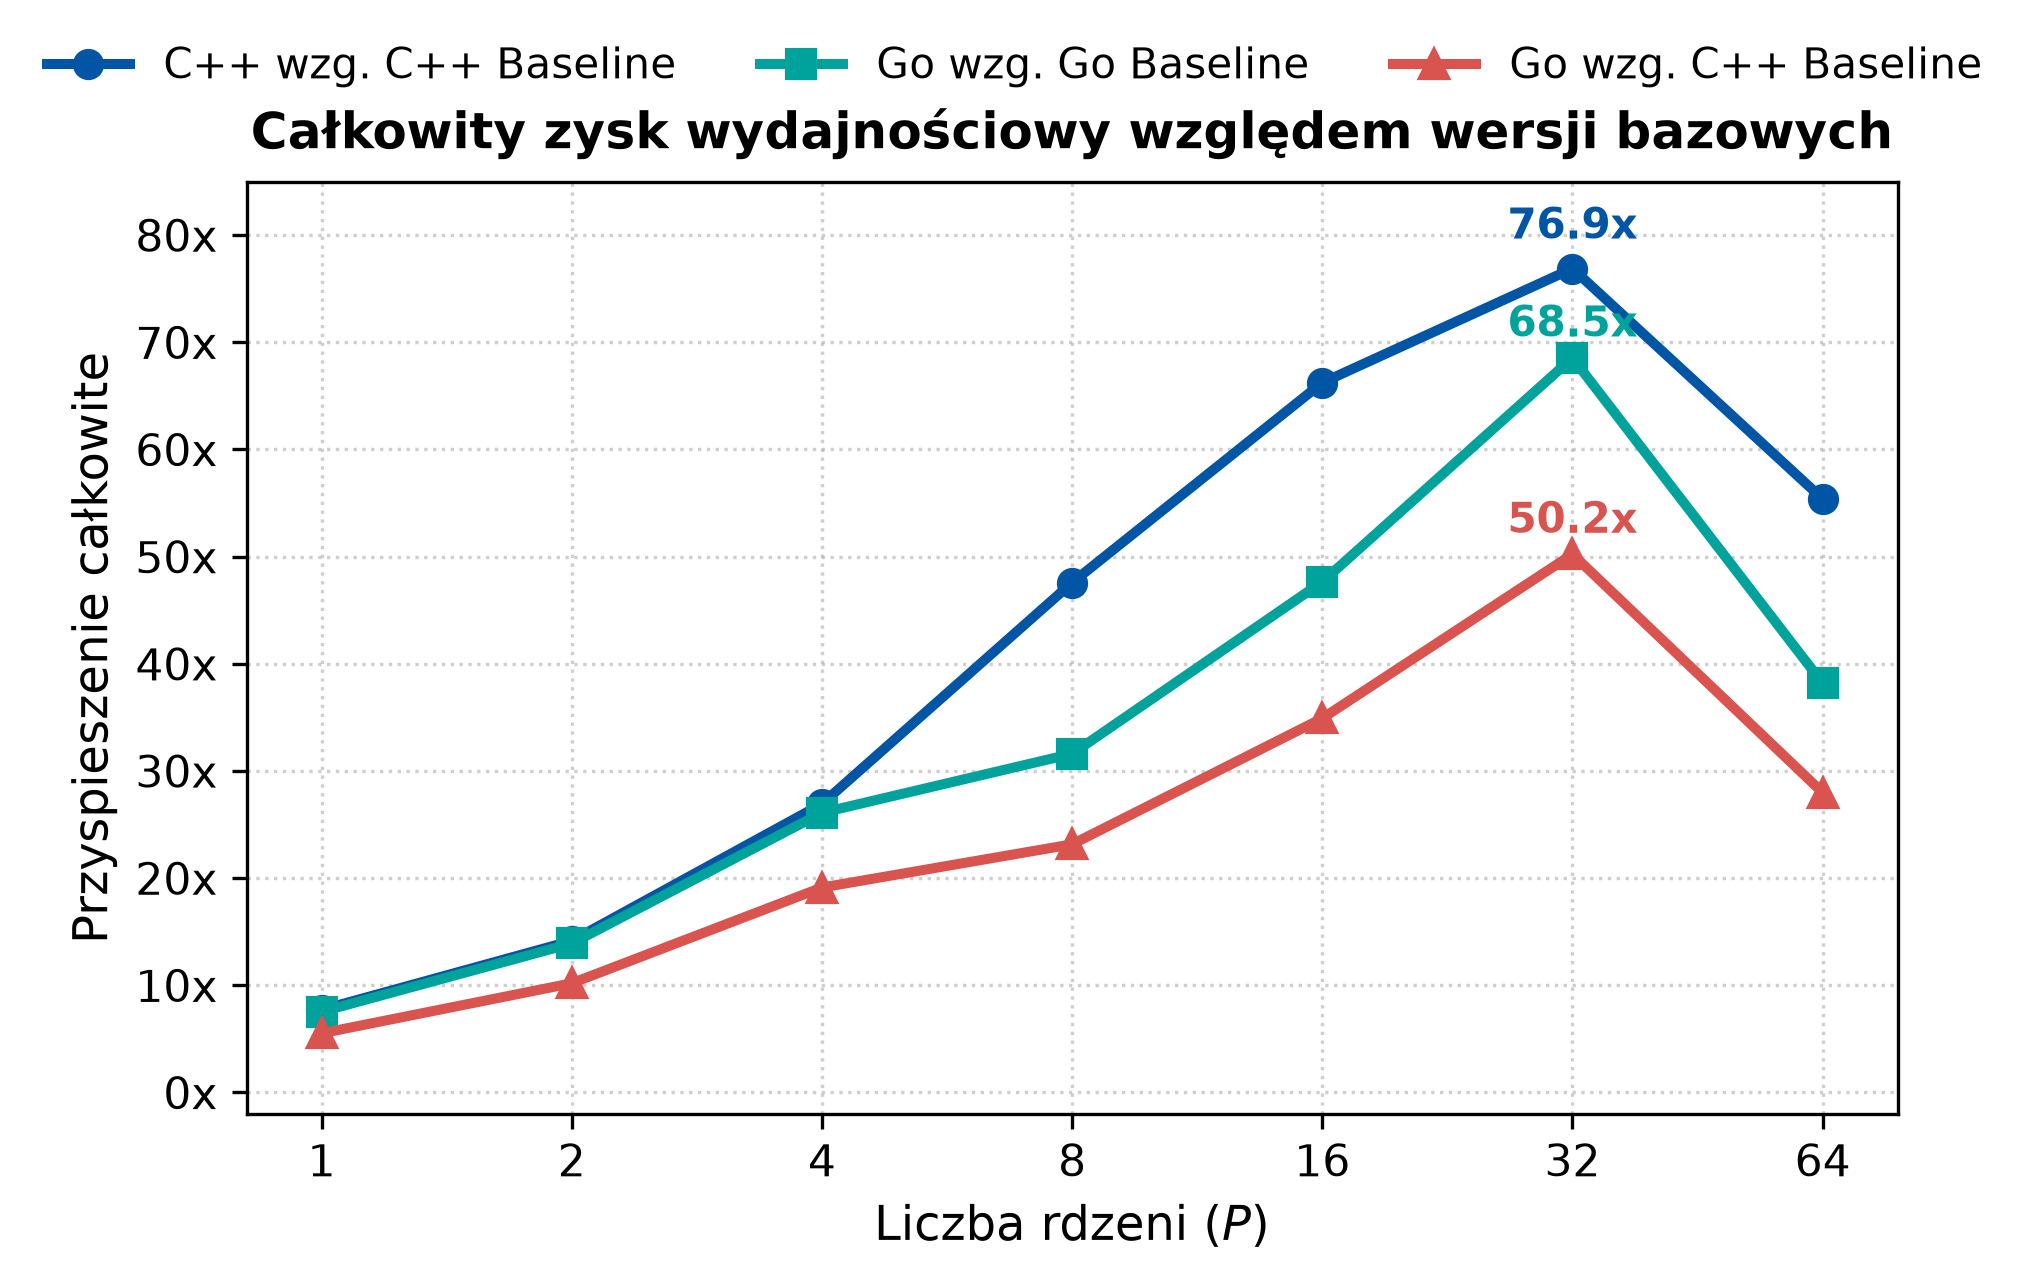

In [ ]:

# 1. DANE I OBLICZENIE TRZECH METRYK PRZYSPIESZENIA
cores = np.array([1, 2, 4, 8, 16, 32, 64])

# Czasy bazowe
t_cpp_base = 1099.38  # C++ eduPIC Baseline
t_go_base = 1500.39  # Go Krok 0 Baseline

# Średnie czasy wykonania wersji zoptymalizowanych (Klaster Lem)
t_cpp = np.array([142.42, 77.70, 40.83, 23.11, 16.60, 14.30, 19.85])
t_go = np.array([199.20, 107.90, 57.49, 47.48, 31.49, 21.89, 39.29])

# 1. C++ wzg. C++ Baseline
s_cpp_vs_cpp_base = t_cpp_base / t_cpp

# 2. Go wzg. Go Baseline
s_go_vs_go_base = t_go_base / t_go

# 3. Go wzg. C++ Baseline
s_go_vs_cpp_base = t_cpp_base / t_go

# 2. BUDOWA WYKRESU (CZYSTY, JEDNOPANELOWY, 3 KRZYWE)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 300

fig, ax = plt.subplots(figsize=(6.4, 4.2))
plt.subplots_adjust(left=0.10, right=0.96, top=0.86, bottom=0.12)

col_cpp_rel = '#0055A5'  # Ciemnoniebieski
col_go_rel = '#00A29C'  # Morski / turkus
col_go_abs = '#D9534F'  # Koralowy / czerwony

# Rysowanie trzech krzywych
line1 = ax.plot(cores, s_cpp_vs_cpp_base, 'o-', color=col_cpp_rel, lw=2.4, ms=6.5,
                label='C++ wzg. C++ Baseline')[0]
line2 = ax.plot(cores, s_go_vs_go_base, 's-', color=col_go_rel, lw=2.4, ms=6.5,
                label='Go wzg. Go Baseline')[0]
line3 = ax.plot(cores, s_go_vs_cpp_base, '^-', color=col_go_abs, lw=2.4, ms=6.5,
                label='Go wzg. C++ Baseline')[0]

ax.set_xscale('log', base=2)
ax.set_xticks(cores)
ax.set_xticklabels([str(p) for p in cores], fontsize=10.5)

ax.set_yticks(range(0, 90, 10))
ax.set_yticklabels([f'{y}x' for y in range(0, 90, 10)], fontsize=10.5)
ax.set_ylim(-2, 85)

ax.set_xlabel(r'Liczba rdzeni ($P$)', fontsize=11.5)
ax.set_ylabel('Przyspieszenie całkowite', fontsize=11.5)
ax.set_title('Całkowity zysk wydajnościowy względem wersji bazowych',
             fontsize=12, fontweight='bold', pad=8)
ax.grid(True, which='both', linestyle=':', alpha=0.6)

# Podpisy wartości szczytowych przy P=32
ax.text(32, s_cpp_vs_cpp_base[5] + 2.8, f'{s_cpp_vs_cpp_base[5]:.1f}x',
        color=col_cpp_rel, fontweight='bold', ha='center', fontsize=10)
ax.text(32, s_go_vs_go_base[5] + 2.0, f'{s_go_vs_go_base[5]:.1f}x',
        color=col_go_rel, fontweight='bold', ha='center', fontsize=10)
ax.text(32, s_go_vs_cpp_base[5] + 2.0, f'{s_go_vs_cpp_base[5]:.1f}x',
        color=col_go_abs, fontweight='bold', ha='center', fontsize=10)

# Legenda wyciągnięta na górę, bez ramki
fig.legend([line1, line2, line3],
           ['C++ wzg. C++ Baseline', 'Go wzg. Go Baseline', 'Go wzg. C++ Baseline'],
           loc='upper center', bbox_to_anchor=(0.50, 0.997), ncol=3,
           fontsize=10, frameon=False)

# Zapis do PDF
plt.savefig('skumulowany_zysk_trzy_metryki.pdf', format='pdf')
plt.show()

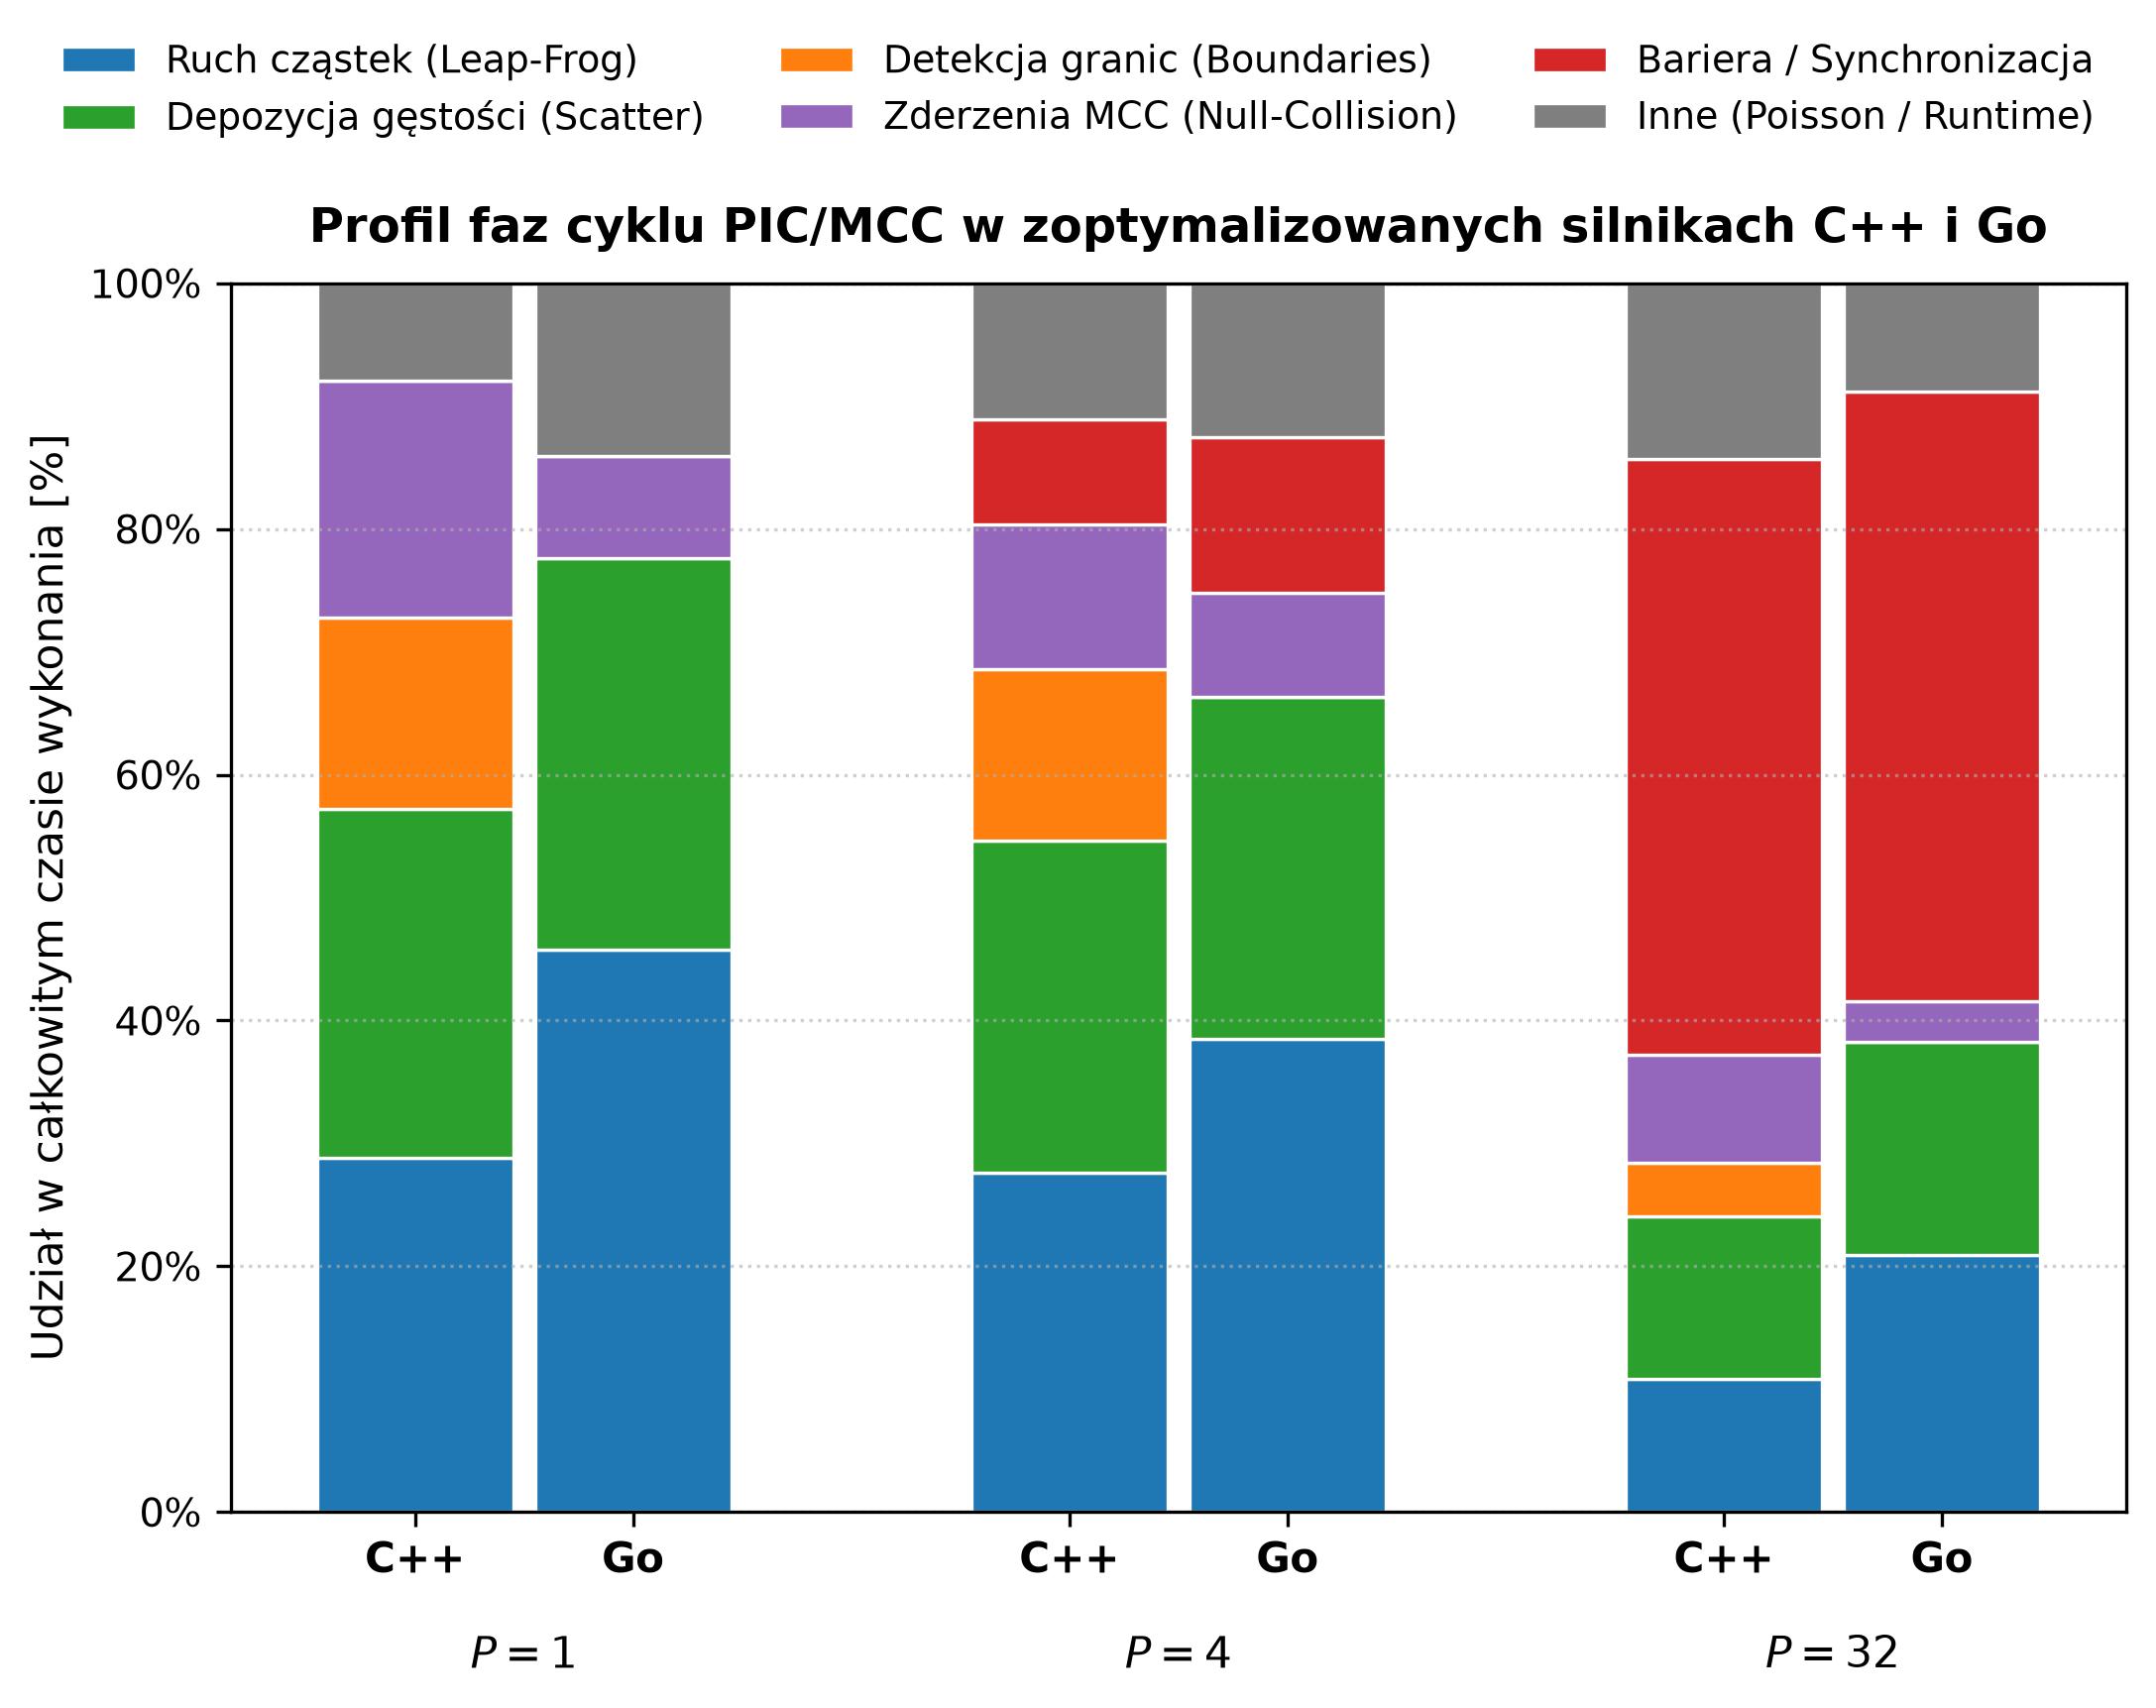

In [69]:
categories = [
    'Ruch cząstek (Leap-Frog)',
    'Depozycja gęstości (Scatter)',
    'Detekcja granic (Boundaries)',
    'Zderzenia MCC (Null-Collision)',
    'Bariera / Synchronizacja',
    'Inne (Poisson / Runtime)'
]

# Udziały procentowe [Ruch, Depozycja, Granice, Zderzenia, Bariera, Inne]
data_cpp = np.array([
    [28.8, 28.4, 15.6, 19.3,  0.0,  7.9],  # P=1
    [27.6, 27.0, 14.0, 11.8,  8.5, 11.1],  # P=4
    [10.8, 13.3,  4.3,  8.8, 48.5, 14.3]   # P=32
])

data_go = np.array([
    [45.8, 31.8,  0.0,  8.3,  0.0, 14.1],  # P=1 (Granice = 0% dzięki fuzji!)
    [38.5, 27.8,  0.0,  8.5, 12.7, 12.5],  # P=4
    [20.9, 17.4,  0.0,  3.3, 49.6,  8.8]   # P=32 (Bariera StarBarrier = 49.6%)
])

colors = [
    '#1f77b4',  # Ruch cząstek - niebieski
    '#2ca02c',  # Depozycja - zielony
    '#ff7f0e',  # Granice - pomarańczowy
    '#9467bd',  # Zderzenia - fioletowy
    '#d62728',  # Bariera - czerwony
    '#7f7f7f'   # Inne - szary
]

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 300

fig, ax = plt.subplots(figsize=(7.5, 5.4))

bar_width = 0.36
# Pozycje na osi X dla par (C++, Go)
x_cpp = np.array([0.8, 2.0, 3.2])
x_go = np.array([1.2, 2.4, 3.6])

# Rysowanie słupków skumulowanych
for i in range(3):
    bot_c = 0.0
    for cat in range(len(categories)):
        ax.bar(x_cpp[i], data_cpp[i, cat], bar_width, bottom=bot_c,
               color=colors[cat], edgecolor='white', linewidth=0.8,
               label=categories[cat] if i == 0 else '')
        bot_c += data_cpp[i, cat]

    bot_g = 0.0
    for cat in range(len(categories)):
        ax.bar(x_go[i], data_go[i, cat], bar_width, bottom=bot_g,
               color=colors[cat], edgecolor='white', linewidth=0.8)
        bot_g += data_go[i, cat]

# Podpisy słupków na osi X: C++ oraz Go
all_x = [0.8, 1.2, 2.0, 2.4, 3.2, 3.6]
all_labels = ['C++', 'Go', 'C++', 'Go', 'C++', 'Go']
ax.set_xticks(all_x)
ax.set_xticklabels(all_labels, fontsize=10, fontweight='bold')

# Podpisy grup pod parami słupków
group_centers = [1.0, 2.2, 3.4]
group_titles = [r'$P = 1$', r'$P = 4$',
                r'$P = 32$']

for xc, title in zip(group_centers, group_titles):
    ax.annotate(title, xy=(xc, 0), xytext=(xc, -10),
                textcoords='data', ha='center', va='top',
                fontsize=10.5, fontweight='bold',
                annotation_clip=False)

# Oś Y i siatka
ax.set_ylabel('Udział w całkowitym czasie wykonania [%]', fontsize=10.5)
ax.set_ylim(0, 100)
ax.set_yticks(range(0, 101, 20))
ax.set_yticklabels([f'{y}%' for y in range(0, 101, 20)], fontsize=9.5)
ax.grid(axis='y', linestyle=':', alpha=0.6)

# Więcej miejsca na tytuł i dwuwierszową legendę
plt.subplots_adjust(
    left=0.09,
    right=0.97,
    bottom=0.15,
    top=0.68
)

# Tytuł wewnątrz obszaru wykresu
ax.set_title(
    r'Profil faz cyklu PIC/MCC w zoptymalizowanych silnikach C++ i Go',
    fontsize=11.5,
    fontweight='bold',
    pad=10
)

# Wspólna legenda nad tytułem
handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.50, 1.08),
    ncol=3,
    fontsize=9.0,
    frameon=False
)

# Zapis do pliku PDF
plt.savefig('wykres_perf_record.pdf', format='pdf', bbox_inches='tight')
plt.show()

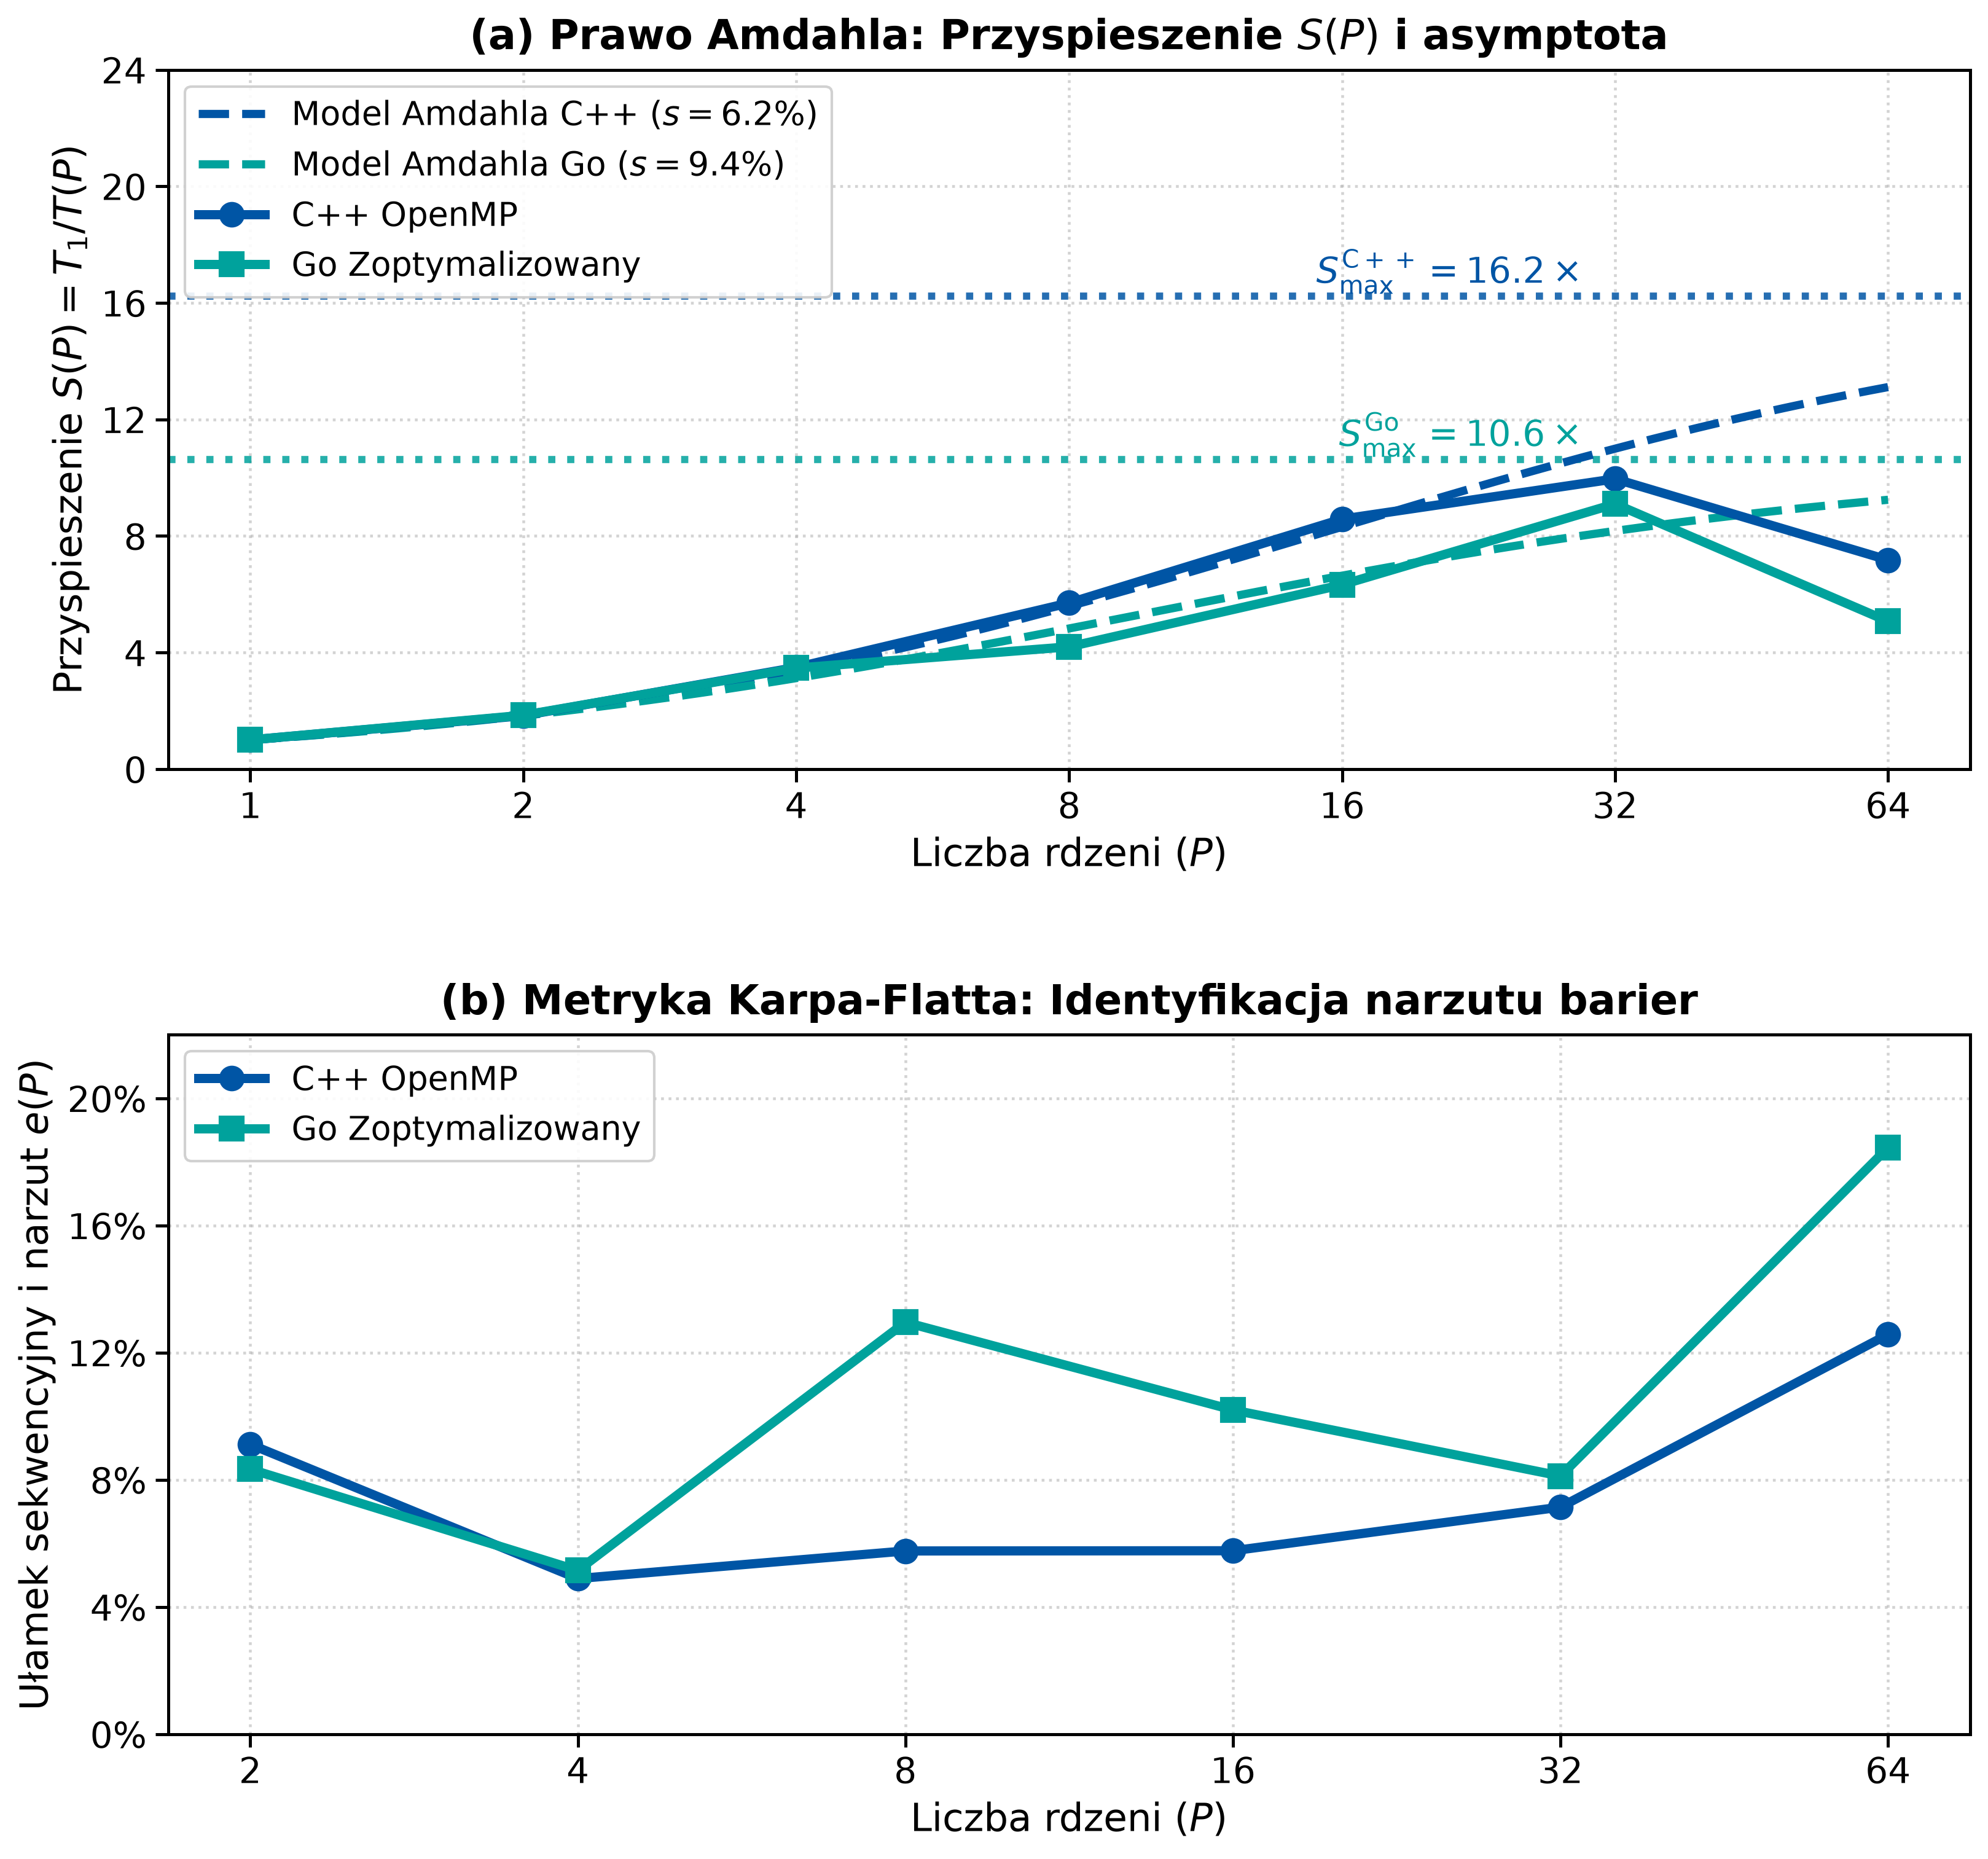

In [2]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

# Konfiguracja stylu wykresu
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 300

# Liczba rdzeni procesora AMD EPYC 9554
cores = np.array([1, 2, 4, 8, 16, 32, 64])

# Średnie czasy wykonania 100 cykli RF [s] (Klaster LEM)
t_cpp = np.array([142.42, 77.70, 40.83, 24.98, 16.60, 14.30, 19.85])
t_go = np.array([199.20, 107.90, 57.49, 47.48, 31.49, 21.89, 39.29])

# Przyspieszenia empiryczne S(P) = T_1 / T(P)
s_cpp = t_cpp[0] / t_cpp
s_go = t_go[0] / t_go

# Dopasowanie modelu Amdahla dla strefy stabilnego skalowania (P <= 32)
mask_fit = cores <= 32
p_fit = cores[mask_fit]
inv_p = 1.0 / p_fit

# Regresja liniowa: T(P) = T_seq + T_par * (1/P)
a_cpp, b_cpp = np.polyfit(inv_p, t_cpp[mask_fit], 1)
t_par_cpp, t_seq_cpp = a_cpp, b_cpp
s_cpp_frac = t_seq_cpp / (t_seq_cpp + t_par_cpp)
s_max_cpp = 1.0 / s_cpp_frac

a_go, b_go = np.polyfit(inv_p, t_go[mask_fit], 1)
t_par_go, t_seq_go = a_go, b_go
s_go_frac = t_seq_go / (t_seq_go + t_par_go)
s_max_go = 1.0 / s_go_frac

# Gęsta siatka dla teoretycznych krzywych Amdahla
p_dense = np.geomspace(1, 64, 300)
s_model_cpp = (t_seq_cpp + t_par_cpp) / (t_seq_cpp + t_par_cpp / p_dense)
s_model_go = (t_seq_go + t_par_go) / (t_seq_go + t_par_go / p_dense)

# Metryka Karpa-Flatta e(P) dla P > 1
cores_kf = cores[cores > 1]
e_cpp = [
    ((1.0 / sp - 1.0 / p) / (1.0 - 1.0 / p)) * 100.0
    for p, sp in zip(cores_kf, s_cpp[cores > 1])
]
e_go = [
    ((1.0 / sp - 1.0 / p) / (1.0 - 1.0 / p)) * 100.0
    for p, sp in zip(cores_kf, s_go[cores > 1])
]

# Budowa układu dwóch paneli (2x1)
plt.rcParams['axes.linewidth'] = 1.2
plt.rcParams['xtick.major.width'] = 1.2
plt.rcParams['ytick.major.width'] = 1.2
plt.rcParams['xtick.major.size'] = 5
plt.rcParams['ytick.major.size'] = 5
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11.5, 10.5))
plt.subplots_adjust(left=0.12, right=0.97, bottom=0.08, top=0.94, hspace=0.38)

col_cpp = '#0055A5'  # Niebieski inżynierski
col_go = '#00A29C'  # Morski / Go
col_ideal = '#7F7F7F'  # Szary
col_ccx = '#D9534F'  # Czerwony dla granicy CCX

# =========================================================================
# PANEL (a): Prawo Amdahla i Asymptota Teoretyczna
# =========================================================================

# Asymptoty teoretyczne S_max
ax1.axhline(s_max_cpp, color=col_cpp, linestyle=':',
            lw=2.8, alpha=0.85, zorder=2)
ax1.axhline(s_max_go, color=col_go, linestyle=':', lw=2.8, alpha=0.85, zorder=2)
ax1.text(
    30,
    s_max_cpp + 0.45,
    rf'$S_{{\max}}^{{\mathrm{{C++}}}} = {s_max_cpp:.1f}\times$',
    color=col_cpp,
    fontsize=14,
    fontweight='bold',
    ha='right',
    zorder=5,
)
ax1.text(
    30,
    s_max_go + 0.45,
    rf'$S_{{\max}}^{{\mathrm{{Go}}}} = {s_max_go:.1f}\times$',
    color=col_go,
    fontsize=14,
    fontweight='bold',
    ha='right',
    zorder=5,
)

# Dopasowane krzywe teoretyczne Amdahla
ax1.plot(
    p_dense,
    s_model_cpp,
    '--',
    color=col_cpp,
    lw=3.2,
    label=rf'Model Amdahla C++ ($s = {s_cpp_frac*100:.1f}\%$)',
    zorder=3,
)
ax1.plot(
    p_dense,
    s_model_go,
    '--',
    color=col_go,
    lw=3.2,
    label=rf'Model Amdahla Go ($s = {s_go_frac*100:.1f}\%$)',
    zorder=3,
)

# Punkty empiryczne zmierzone na klastrze LEM
ax1.plot(
    cores,
    s_cpp,
    'o-',
    color=col_cpp,
    lw=3.6,
    ms=9,
    label='C++ OpenMP',
    zorder=4,
)
ax1.plot(
    cores,
    s_go,
    's-',
    color=col_go,
    lw=3.6,
    ms=9,
    label='Go Zoptymalizowany',
    zorder=4,
)

ax1.set_xscale('log', base=2)
ax1.set_xticks(cores)
ax1.set_xticklabels([str(p) for p in cores], fontsize=14)
ax1.set_yticks(range(0, 28, 4))
ax1.set_yticklabels(range(0, 28, 4), fontsize=14)
ax1.set_ylim(0, 24)
ax1.set_xlabel(r'Liczba rdzeni ($P$)', fontsize=15)
ax1.set_ylabel(r'Przyspieszenie $S(P) = T_1 / T(P)$', fontsize=15)
ax1.set_title(
    r'(a) Prawo Amdahla: Przyspieszenie $S(P)$ i asymptota',
    fontsize=16,
    fontweight='bold',
    pad=8,
)
ax1.grid(True, which='both', linestyle=':', linewidth=1.1, alpha=0.55)
ax1.legend(
    loc='upper left',
    fontsize=13,
    frameon=True,
    facecolor='white',
    framealpha=0.9,
    edgecolor='#CCCCCC',
)

# =========================================================================
# PANEL (b): Metryka Karpa-Flatta e(P) i Identyfikacja Narzutu
# =========================================================================
ax2.plot(
    cores_kf,
    e_cpp,
    'o-',
    color=col_cpp,
    lw=3.6,
    ms=9,
    label='C++ OpenMP',
    zorder=4,
)
ax2.plot(
    cores_kf,
    e_go,
    's-',
    color=col_go,
    lw=3.6,
    ms=9,
    label='Go Zoptymalizowany',
    zorder=4,
)

ax2.set_xscale('log', base=2)
ax2.set_xticks(cores_kf)
ax2.set_xticklabels([str(p) for p in cores_kf], fontsize=14)
ax2.set_yticks(range(0, 24, 4))
ax2.set_yticklabels([f'{y}%' for y in range(0, 24, 4)], fontsize=14)
ax2.set_ylim(0, 22)
ax2.set_xlabel(r'Liczba rdzeni ($P$)', fontsize=15)
ax2.set_ylabel(r'Ułamek sekwencyjny i narzut $e(P)$', fontsize=15)
ax2.set_title(
    r'(b) Metryka Karpa-Flatta: Identyfikacja narzutu barier',
    fontsize=16,
    fontweight='bold',
    pad=8,
)
ax2.grid(True, which='both', linestyle=':', linewidth=1.1, alpha=0.55)
ax2.legend(
    loc='upper left',
    fontsize=13,
    frameon=True,
    facecolor='white',
    framealpha=0.9,
    edgecolor='#CCCCCC',
)

plt.savefig('skalowanie_amdahl_karp_flatt.pdf', format='pdf')
plt.show()

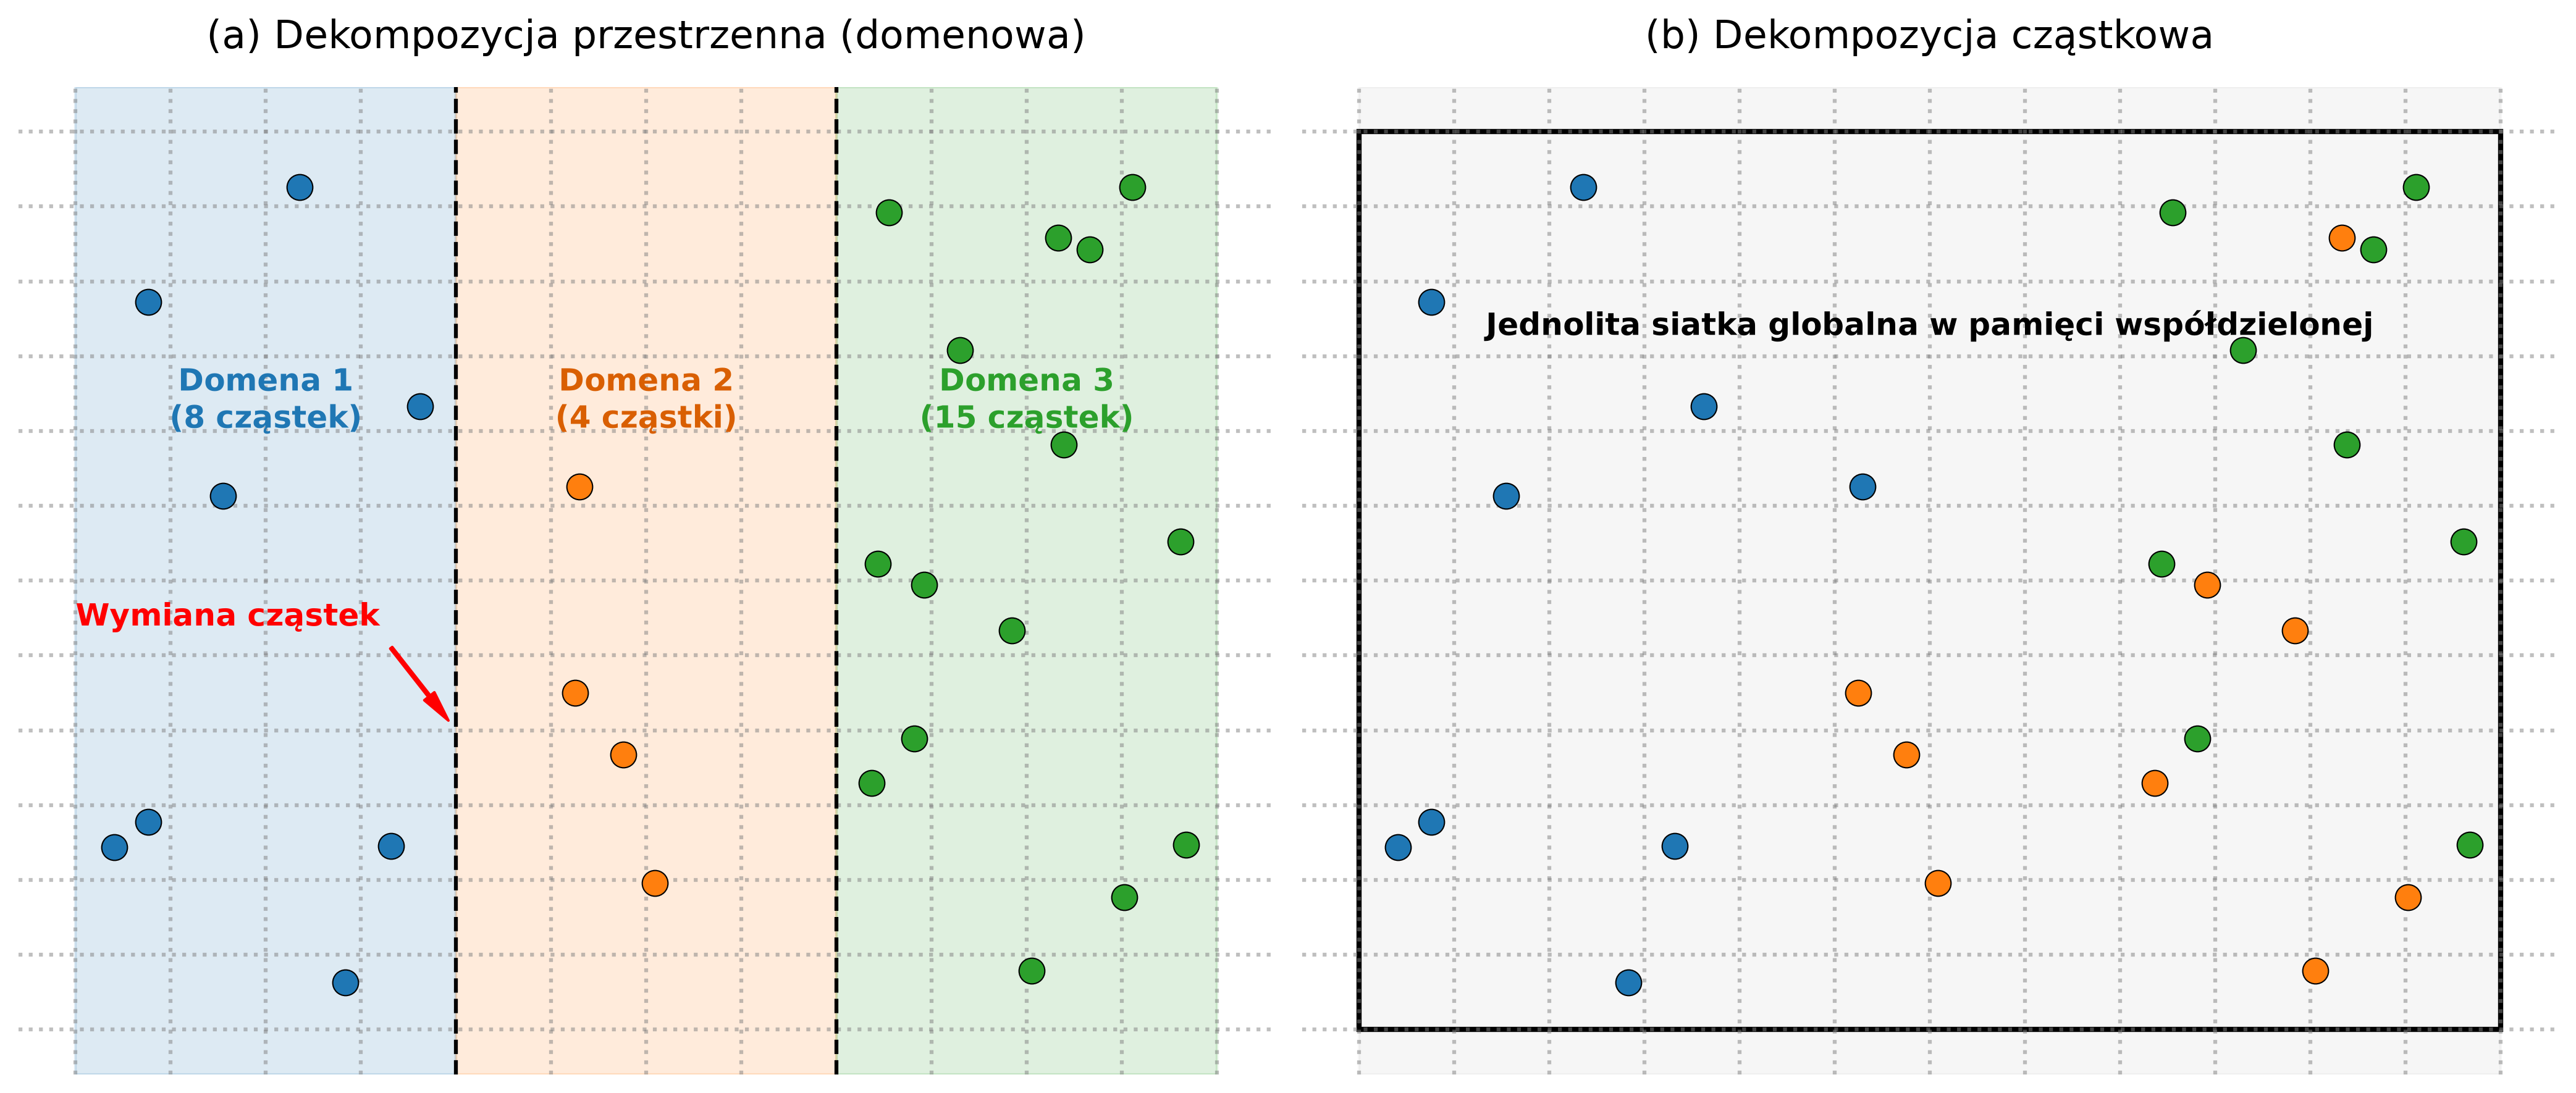

In [68]:
# Konfiguracja stylu wykresu 
plt.rcParams['font.family'] = 'sans-serif' 
plt.rcParams['font.size'] = 10

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), dpi=300)

# PANEL (a): DEKOMPOZYCJA PRZESTRZENNA
ax1.set_title("(a) Dekompozycja przestrzenna (domenowa)", fontsize=15, pad=15)

# Tła dla poddomen
ax1.axvspan(0, 2, color='#1f77b4', alpha=0.15, label='Wątek 1 (Domena 1)')
ax1.axvspan(2, 4, color="#ff7f0e", alpha=0.15, label='Wątek 2 (Domena 2)')
ax1.axvspan(4, 6, color='#2ca02c', alpha=0.15, label='Wątek 3 (Domena 3)')

# Rysowanie siatki
for x in np.arange(0, 6.5, 0.5):
    ax1.axvline(x, color='gray', linestyle=':', alpha=0.5)
for y in np.arange(0, 6.5, 0.5):
    ax1.axhline(y, color='gray', linestyle=':', alpha=0.5)

# Linie podziału domen
ax1.axvline(2, color='black', linestyle='--', linewidth=1.5)
ax1.axvline(4, color='black', linestyle='--', linewidth=1.5)

# Cząstki (zagęszczone w domenie 3)
np.random.seed(42)

# Cząstki domeny 1
x1 = np.random.uniform(0.1, 1.9, 8)
y1 = np.random.uniform(0.2, 5.8, 8)
ax1.scatter(x1, y1, color='#1f77b4', s=100, zorder = 3, edgecolors='black', linewidth=0.5)

# Cząstki domeny 2
x2 = np.random.uniform(2.1, 3.9, 4)
y2 = np.random.uniform(0.2, 5.8, 4)
ax1.scatter(x2, y2, color='#ff7f0e', s=100, zorder = 3, edgecolors='black', linewidth=0.5)

# Cząstki domeny 3
x3 = np.random.uniform(4.1, 5.9, 15)
y3 = np.random.uniform(0.2, 5.8, 15)
ax1.scatter(x3, y3, color='#2ca02c', s=100, zorder = 3, edgecolors='black', linewidth=0.5)

# Etykiety
ax1.text(1, 4.2, "Domena 1\n(8 cząstek)", ha='center', va='center', color='#1f77b4', fontweight='bold', fontsize=12)
ax1.text(3, 4.2, "Domena 2\n(4 cząstki)", ha='center', va='center', color='#d95f02', fontweight='bold', fontsize=12)
ax1.text(5, 4.2, "Domena 3\n(15 cząstek)", ha='center', va='center', color='#2ca02c', fontweight='bold', fontsize=12)

# Strzałka ghost cells
ax1.annotate('Wymiana cząstek', xy=(2.00, 2.0), xytext=(0.0, 2.7), arrowprops=dict(facecolor='red', edgecolor='red', shrink=0.1, width=1.0, headwidth=5),
             fontsize=12, fontweight='bold', color='red')

ax1.axis('off')


# PANEL (b): DEKOMPOZYCJA CZĄSTKOWA

ax2.set_title("(b) Dekompozycja cząstkowa", fontsize=15, pad=15)

ax2.axvspan(0,6, color='lightgray', alpha=0.2)

# Rysowanie siatki
for x in np.arange(0, 6.5, 0.5):
    ax2.axvline(x, color='gray', linestyle=':', alpha=0.5)
for y in np.arange(0, 6.5, 0.5):
    ax2.axhline(y, color='gray', linestyle=':', alpha=0.5)

# Obramowanie całej siatki
rect = plt.Rectangle((0,0), 6, 6, linewidth=2, edgecolor='black', facecolor='none')
ax2.add_patch(rect)

# Cząstki podzielone równo między 3 wątki
all_x = np.concatenate([x1, x2, x3])
all_y = np.concatenate([y1, y2, y3])
total_p = len(all_x)

p_per_thread = total_p // 3

ax2.scatter(all_x[:p_per_thread], all_y[:p_per_thread], color='#1f77b4', s=100, zorder=3, edgecolors='black', linewidth=0.5, label=f'Wątek 1 ({p_per_thread} cz.)')
ax2.scatter(all_x[p_per_thread:p_per_thread*2], all_y[p_per_thread:p_per_thread*2], color='#ff7f0e', s=100, zorder=3, edgecolors='black', linewidth=0.5, label=f'Wątek 2 ({p_per_thread} cz.)')
ax2.scatter(all_x[p_per_thread*2:], all_y[p_per_thread*2:], color='#2ca02c', s=100, zorder=3, edgecolors='black', linewidth=0.5, label=f'Wątek 3 ({p_per_thread} cz.)')

# Etykieta siatki globalnej i informacja o prywatnych siatkach
ax2.text(3, 4.7, "Jednolita siatka globalna w pamięci współdzielonej", ha='center', va='center', fontweight='bold', color='black', fontsize=12)

ax2.axis('off')


# Zapis do pliku
plt.tight_layout()
plt.savefig('dekompozycja_porownania.pdf', bbox_inches='tight')
plt.show()